# AI-Driven Discovery of Novel Aroma and Taste Molecules
### A merged, multi-source structure–odor / structure–taste database and ML pipeline

**Author:** Babak, Computational Chemist / Cheminformatician
**Context:** technical presentation for the DSM-Firmenich Perfumery & Beauty and Taste, Texture & Health R&D teams

---

**What this notebook demonstrates.** Public structure–odor data is small and spread across many sources, and each source uses its own vocabulary. Most published models train on just one of them. Here I build a **single curated, provenance-tracked database** that merges nine public aroma sources, panel ratings, and taste databases. Then (in later parts) I train and stress-test models on it the way an industrial team would before using them to triage synthesis candidates.

| Part | Content | |
|---|---|---|
| **1** | **Data layer:** acquisition, standardization, vocabulary harmonization, merge, database, EDA | included |
| 2 | Featurization (chirality-aware fingerprints, descriptors, embeddings), chemical space, leakage-safe splits | included |
| 3 | Aroma multi-label and taste models, baselines, grouped CV, calibration, applicability domain | |
| 4 | Interpretability (substructure attribution, known SOR rules), enantiomer case studies, virtual screening, deployment | |

**Design principles**

* **Every number traces to a source.** Each label keeps the source and raw text it came from.
* **Odor and taste are separate problems.** Volatile odorants act on olfactory GPCRs; tastants act on TAS1R/TAS2R receptors and ion channels. They share a molecule table but never a label column. A "sweet" *odor note* is not a "sweet" *taste*.
* **Stereochemistry is kept.** Molecules are merged on the InChIKey connectivity block, and every stereo variant is preserved, because enantiomers can smell different (carvone, for example).
* **Reproducible and cache-first.** Every download is cached with a SHA-256 manifest, so a live demo never depends on a third-party server.

## 0. Colab setup

Run the two cells below **once per runtime**, before anything else. They install the packages Colab does not ship with and pick up the ChemTastesDB spreadsheet.

**The first cell restarts the runtime if it had to install anything.** That is deliberate: upgrading pandas or numpy under a running kernel leaves the imported copy half-replaced, which shows up much later as `ImportError: cannot import name 'Pandas4Warning' from 'pandas.errors'` in an unrelated cell. When the runtime comes back, run that cell again (it will install nothing and just print versions) and carry on.

* **Runtime:** CPU is enough; a high-RAM runtime helps Part 3. No GPU is used.
* **Runtime > Run all** executes the whole notebook; expect roughly 45–75 minutes, most of it in Part 3.
* **Everything is written under the working directory** (`data/`, `src/`, `models/`, `figures/`, `results/`). Colab deletes that when the runtime recycles, so to keep results across sessions, mount Drive first (`from google.colab import drive; drive.mount('/content/drive')`) and `%cd` into a folder there before running anything.
* **ChemTastesDB:** Zenodo rate-limits scripted downloads, so the second cell asks you to upload `ChemTastesDB_database.xlsx` if it is not already in `data/raw/`. Download it once from the [Zenodo record](https://zenodo.org/records/15051366).

In [ ]:
# Install what Colab does not already have, then restart the runtime once.
# A pip install that upgrades pandas/numpy under a running kernel leaves the already-imported
# copy half-replaced, which surfaces later as e.g.
#   ImportError: cannot import name 'Pandas4Warning' from 'pandas.errors'
# The restart below prevents that. After it, simply run this cell again and continue.
import importlib.util, os, subprocess, sys

IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [pkg for mod, pkg in [("rdkit", "rdkit"), ("lightgbm", "lightgbm"), ("umap", "umap-learn")]
           if importlib.util.find_spec(mod) is None]
if missing:
    print("installing:", ", ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
    if IN_COLAB:
        print("Install done. Restarting the runtime; when it comes back, run this cell again "
              "and then Runtime > Run all.")
        os.kill(os.getpid(), 9)          # Colab restarts the kernel automatically
    else:
        print("Install done. Restart the kernel before continuing.")

import numpy, pandas, sklearn, matplotlib, rdkit, lightgbm
print(f"python {sys.version.split()[0]} | numpy {numpy.__version__} | pandas {pandas.__version__} | "
      f"scikit-learn {sklearn.__version__} | rdkit {rdkit.__version__} | lightgbm {lightgbm.__version__}")

In [2]:
# ChemTastesDB: reuse the file if it is already here, otherwise ask for it (Colab only).
import importlib.util, shutil
from pathlib import Path

TARGET = Path("data/raw/chemtastesdb__ChemTastesDB_database.xlsx")
TARGET.parent.mkdir(parents=True, exist_ok=True)
if TARGET.exists():
    print(f"ChemTastesDB already present: {TARGET} ({TARGET.stat().st_size / 1e6:.1f} MB)")
elif importlib.util.find_spec("google.colab") is not None:
    from google.colab import files
    print("Upload ChemTastesDB_database.xlsx (from https://zenodo.org/records/15051366)")
    for name in files.upload():
        shutil.move(name, TARGET)
        print("saved ->", TARGET)
else:
    print(f"{TARGET} not found. The taste track will be skipped unless you put the file there.")

ChemTastesDB already present: data/raw/chemtastesdb__ChemTastesDB_database.xlsx (0.4 MB)


---
# Part 1: The Data Layer
Acquisition, standardization, vocabulary harmonization, the merged database, and EDA.

## 1. Environment and configuration

Dependencies are pinned in the companion `requirements.txt` rather than auto-installed here. Run `pip install -r requirements.txt` once (on Colab: `!pip install -r requirements.txt`).

In [3]:
import ast
import hashlib
import json
import os
import random
import re
import sqlite3
import time
import warnings
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed
from dataclasses import dataclass, field
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

import rdkit
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Crippen, rdMolDescriptors
from rdkit.Chem.MolStandardize import rdMolStandardize

RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore", category=FutureWarning)

# ---------------- reproducibility ----------------
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# ---------------- paths ----------------
PROJECT_ROOT = Path.cwd()
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "figures"
for p in (DATA_RAW, DATA_PROCESSED, FIG_DIR):
    p.mkdir(parents=True, exist_ok=True)
DB_PATH = DATA_PROCESSED / "aroma_taste.sqlite"

# ---------------- run switches ----------------
# FlavorDB2 has no bulk download; it is scraped politely entity by entity and cached.
# The first run takes roughly 5-15 minutes; later runs read the cache.
RUN_FLAVORDB2_SCRAPE = True
FLAVORDB2_MAX_ENTITY_ID = 1000      # FlavorDB has ~950 food entities
FLAVORDB2_WORKERS = 4               # small, polite concurrency
HTTP_TIMEOUT_S = 30

# ---------------- plotting ----------------
# Colorblind-validated categorical order, assigned in fixed order (never cycled).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = sns.light_palette("#2a78d6", as_cmap=True)
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": INK_2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_2, "ytick.color": INK_2, "legend.frameon": False,
    "figure.facecolor": "white",
})
sns.set_palette(CAT)


def savefig(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path)
    return path


print(f"Python libs: pandas {pd.__version__} | numpy {np.__version__} | RDKit {rdkit.__version__}")
print(f"Project root: {PROJECT_ROOT}")

Python libs: pandas 3.0.5 | numpy 2.5.3 | RDKit 2026.09.1
Project root: /tmp/claude-0/-home-claude/b11bfd01-4ccd-5160-a739-b0babeca4f15/scratchpad/merged_run


## 2. Data source registry

Each source is declared once, with its URL, citation, licence, and the modality it contributes. Keeping the licence next to the data is an industry habit. Several of these sets are research-use or non-commercial only, so a production model at an ingredients company would be retrained on licensed or in-house data. The pipeline stays the same.

| Key | Modality | What it contributes | Licence (summary) |
|---|---|---|---|
| `gslf` | odor | OpenPOM curated GoodScents + Leffingwell matrix, 138 labels (the reference vocabulary) | code MIT, labels follow GoodScents/Leffingwell terms |
| `leffingwell` | odor | Leffingwell & Associates expert descriptors with stereo SMILES | research use |
| `goodscents` | odor | The Good Scents Company descriptors, with concentration and solvent | TGSC terms |
| `sigma_2014` | odor | Sigma-Aldrich Flavors & Fragrances catalogue descriptors | catalogue data |
| `arctander_1960` | odor | Arctander, *Perfume and Flavor Chemicals* | research use |
| `ifra_2019` | odor | IFRA Fragrance Ingredient Glossary (3 descriptors each) | IFRA |
| `flavornet` | odor | Flavornet GC-olfactometry descriptors (Acree & Arn) | © Datu Inc. |
| `aromadb` | odor | AromaDb (Kumar et al., 2018) | public |
| `keller_2016` | odor (panel) | 480 molecules × 55 subjects: intensity, pleasantness, 20 descriptors (DREAM challenge data) | open |
| `dravnieks_1985` | odor (panel) | ASTM Atlas of Odor Character Profiles, 146 graded descriptors | research use |
| `chemtastesdb` | taste | ChemTastesDB v2.1, 4,075 tastants in 10 taste classes | CC BY 4.0 |
| `sweetenersdb` | taste | SweetenersDB v2.0, 316 sweeteners with log relative sweetness | academic |
| `flavordb2` | odor + taste | FlavorDB2 molecules scraped from food entities (fixed parser) | CC BY-NC-SA 3.0 |

BitterDB is deliberately excluded. Its site reserves all rights, explicitly including AI training.

In [4]:
PYRFUME = "https://raw.githubusercontent.com/pyrfume/pyrfume-data/main"


@dataclass
class Source:
    key: str
    modality: str
    files: dict                 # local filename -> URL
    citation: str
    license: str
    optional: bool = False      # optional sources may fail without stopping the pipeline


def _pyrfume(key, names):
    return {f"{key}__{n}": f"{PYRFUME}/{key}/{n}" for n in names}


SOURCES = {s.key: s for s in [
    Source("gslf", "odor",
           {"gslf__curated_GS_LF_merged_4983.csv":
            "https://raw.githubusercontent.com/BioMachineLearning/openpom/main/openpom/data/curated_datasets/curated_GS_LF_merged_4983.csv"},
           "Lee et al., Science 2023 (Principal Odor Map); OpenPOM, Barsainyan et al. 2023", "MIT code; labels research use"),
    Source("leffingwell", "odor", _pyrfume("leffingwell", ["stimuli.csv", "behavior_sparse.csv"]),
           "Leffingwell & Associates via Sanchez-Lengeling et al. 2019", "research use (see Pyrfume LICENSE)"),
    Source("goodscents", "odor", _pyrfume("goodscents", ["molecules.csv", "stimuli.csv", "behavior.csv"]),
           "The Good Scents Company via Pyrfume", "TGSC terms"),
    Source("sigma_2014", "odor", _pyrfume("sigma_2014", ["molecules.csv", "stimuli.csv", "behavior_sparse.csv"]),
           "Sigma-Aldrich F&F catalogue 2014 via Pyrfume", "catalogue data"),
    Source("arctander_1960", "odor", _pyrfume("arctander_1960", ["molecules.csv", "stimuli.csv", "behavior_1_sparse.csv"]),
           "Arctander 1960/1969 via Mainland lab / Pyrfume", "research use"),
    Source("ifra_2019", "odor", _pyrfume("ifra_2019", ["molecules.csv", "stimuli.csv", "behavior.csv"]),
           "IFRA Fragrance Ingredient Glossary 2019 via Pyrfume", "IFRA"),
    Source("flavornet", "odor", _pyrfume("flavornet", ["molecules.csv", "stimuli.csv", "behavior.csv"]),
           "Acree & Arn, Flavornet, via Pyrfume", "(c) Datu Inc."),
    Source("aromadb", "odor", _pyrfume("aromadb", ["molecules.csv", "stimuli.csv", "behavior.csv"]),
           "Kumar et al. 2018, AromaDb, via Pyrfume", "public"),
    Source("keller_2016", "odor_panel", _pyrfume("keller_2016", ["molecules.csv", "stimuli.csv", "behavior.csv"]),
           "Keller & Vosshall, BMC Neurosci 2016; Keller et al., Science 2017 (DREAM)", "open"),
    Source("dravnieks_1985", "odor_panel", _pyrfume("dravnieks_1985", ["molecules.csv", "stimuli.csv", "behavior_1.csv"]),
           "Dravnieks, ASTM DS61 1985, via Pyrfume", "research use"),
    Source("sweetenersdb", "taste",
           {"sweetenersdb__SweetenersDB_v2.0.csv":
            "https://raw.githubusercontent.com/chemosim-lab/SweetenersDB/master/SweetenersDB_v2.0.csv"},
           "Bouysset et al., Food Chem 2020; Cheron et al., Food Chem 2017", "academic"),
    Source("chemtastesdb", "taste",
           {"chemtastesdb__ChemTastesDB_database.xlsx":
            "https://zenodo.org/records/15051366/files/ChemTastesDB_database.xlsx?download=1"},
           "Rojas et al., Food Chem: Mol Sci 2022; v2.1 Zenodo 2025 (doi:10.5281/zenodo.15051366)", "CC BY 4.0",
           optional=True),
]}

print(f"{len(SOURCES)} file-based sources registered (+ FlavorDB2 scraper).")

12 file-based sources registered (+ FlavorDB2 scraper).


## 3. Cached download with an integrity manifest

Files are downloaded once into `data/raw/`. The manifest records each file's URL, size, SHA-256, and download time, so a reviewer can confirm exactly which snapshot produced the results.

**ChemTastesDB note:** Zenodo occasionally rate-limits scripted downloads. If the download fails, download `ChemTastesDB_database.xlsx` from the [Zenodo record](https://zenodo.org/records/15051366) in a browser and save it as `data/raw/chemtastesdb__ChemTastesDB_database.xlsx`. The cell will then pick it up.

In [5]:
MANIFEST_PATH = DATA_RAW / "manifest.json"
HEADERS = {"User-Agent": "aroma-taste-research-notebook/1.0 (academic; contact via GitHub)"}


def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def download(url, dest, retries=3):
    """Download url to dest unless it is already cached. Returns True on success."""
    if dest.exists() and dest.stat().st_size > 0:
        return True
    for attempt in range(1, retries + 1):
        try:
            with requests.get(url, headers=HEADERS, timeout=HTTP_TIMEOUT_S, stream=True) as r:
                r.raise_for_status()
                tmp = dest.with_suffix(dest.suffix + ".part")
                with open(tmp, "wb") as fh:
                    for block in r.iter_content(1 << 16):
                        fh.write(block)
                tmp.rename(dest)
            return True
        except Exception as exc:
            if attempt == retries:
                print(f"   [failed] {dest.name}: {type(exc).__name__}: {exc}")
                return False
            time.sleep(2 ** attempt)


manifest = json.loads(MANIFEST_PATH.read_text()) if MANIFEST_PATH.exists() else {}
availability = {}
for src in SOURCES.values():
    ok = True
    for fname, url in src.files.items():
        dest = DATA_RAW / fname
        if download(url, dest):
            if fname not in manifest:
                manifest[fname] = {"url": url, "bytes": dest.stat().st_size, "sha256": sha256(dest),
                                   "downloaded_utc": datetime.now(timezone.utc).isoformat(timespec="seconds")}
        else:
            ok = False
    availability[src.key] = ok
    status = "ok" if ok else ("SKIPPED (optional)" if src.optional else "MISSING")
    print(f"{src.key:16s} {status}")

MANIFEST_PATH.write_text(json.dumps(manifest, indent=2))
missing_required = [k for k, ok in availability.items() if not ok and not SOURCES[k].optional]
if missing_required:
    raise RuntimeError(f"Required sources missing: {missing_required}. Check network access to raw.githubusercontent.com.")
print(f"\nManifest: {len(manifest)} files, {sum(v['bytes'] for v in manifest.values()) / 1e6:.1f} MB")

gslf             ok


leffingwell      ok


goodscents       ok


sigma_2014       ok


arctander_1960   ok


...

flavornet        ok


aromadb          ok


keller_2016      ok


dravnieks_1985   ok


sweetenersdb     ok
chemtastesdb     ok

Manifest: 29 files, 72.8 MB


## 4. Parsing every source into one tidy record format

Every source becomes the same long-format record: one row per (source, stimulus) holding a SMILES, identifiers, the raw descriptor text, and a parsed token list. Concentration and solvent are kept where the source has them, because odor character depends on dilution. Indole, for example, is floral when dilute and fecal when concentrated.

The Pyrfume layout is consistent across sources: `molecules.csv` (CID → SMILES), `stimuli.csv` (stimulus → CID and conditions), and `behavior*.csv` (stimulus → labels). One generic loader handles all of them.

In [6]:
RECORD_COLS = ["source", "modality", "stimulus", "cid", "name", "cas", "smiles_raw",
               "raw_descriptors", "tokens", "concentration", "solvent", "value"]


def _raw(key, name):
    return DATA_RAW / f"{key}__{name}"


def split_tokens(text, seps=r"[;,@|/]"):
    """Split a free-text descriptor string into clean lower-case tokens."""
    if text is None or (np.ndim(text) == 0 and pd.isna(text)):   # covers None, NaN and pd.NA
        return []
    text = str(text)
    if text.strip().startswith("["):                       # python-list strings, e.g. "['green', 'waxy']"
        try:
            return [str(t).strip().lower() for t in ast.literal_eval(text) if str(t).strip()]
        except (ValueError, SyntaxError):
            pass
    return [t.strip().lower() for t in re.split(seps, text) if t.strip()]


def pyrfume_records(key, behavior_file, descriptor_fn, stim_cid_col="CID"):
    """Generic Pyrfume loader: behavior -> stimuli -> molecules (CID -> SMILES)."""
    beh = pd.read_csv(_raw(key, behavior_file))
    stim = pd.read_csv(_raw(key, "stimuli.csv"))
    mols = pd.read_csv(_raw(key, "molecules.csv"))
    if stim_cid_col not in stim.columns:                    # stimulus id is itself the CID
        stim[stim_cid_col] = stim["Stimulus"]
    df = beh.merge(stim, on="Stimulus", how="left", suffixes=("", "_stim"))
    df["cid"] = pd.to_numeric(df[stim_cid_col], errors="coerce")
    df = df.merge(mols[["CID", "IsomericSMILES", "name"]], left_on="cid", right_on="CID", how="left")
    raw, tokens = zip(*df.apply(descriptor_fn, axis=1)) if len(df) else ([], [])
    out = pd.DataFrame({
        "source": key, "modality": "odor", "stimulus": df["Stimulus"].astype(str),
        "cid": df["cid"], "name": df["name"], "cas": df.get("CAS"),
        "smiles_raw": df["IsomericSMILES"], "raw_descriptors": raw, "tokens": tokens,
        "concentration": df.get("Concentration %"), "solvent": df.get("Solvent"), "value": np.nan,
    })
    return out[RECORD_COLS]


records = []

# --- GoodScents: CAS-keyed stimuli, ';'-separated descriptors, concentration + solvent
records.append(pyrfume_records("goodscents", "behavior.csv",
                               lambda r: (r["Descriptors"], split_tokens(r["Descriptors"]))))

# --- Sigma 2014: stimulus id is the CID; negative ids have no structure and drop out at the merge
records.append(pyrfume_records("sigma_2014", "behavior_sparse.csv",
                               lambda r: (r["descriptors"], split_tokens(r["descriptors"]))))

# --- Arctander: CID column is called new_CID
records.append(pyrfume_records("arctander_1960", "behavior_1_sparse.csv",
                               lambda r: (r["Labels"], split_tokens(r["Labels"])), stim_cid_col="new_CID"))

# --- IFRA glossary: three descriptor columns
def _ifra(r):
    vals = [r[c] for c in ("Descriptor 1", "Descriptor 2", "Descriptor 3") if isinstance(r[c], str)]
    return ("; ".join(vals), [v.strip().lower() for v in vals])
records.append(pyrfume_records("ifra_2019", "behavior.csv", _ifra))

# --- Flavornet (GC-O descriptors)
records.append(pyrfume_records("flavornet", "behavior.csv",
                               lambda r: (r["Descriptors"], split_tokens(r["Descriptors"]))))

# --- AromaDb: use the filtered descriptor; 'no aroma' means odorless
def _aromadb(r):
    t = r["Filtered Descriptors"]
    toks = ["odorless"] if t == "no aroma" else split_tokens(t)
    return (r["Raw Descriptors"], toks)
records.append(pyrfume_records("aromadb", "behavior.csv", _aromadb))

# --- Leffingwell: SMILES live in stimuli.csv (some have no CID -> negative ids)
lf_stim = pd.read_csv(_raw("leffingwell", "stimuli.csv"))
lf_beh = pd.read_csv(_raw("leffingwell", "behavior_sparse.csv"))
lf = lf_beh.merge(lf_stim, on="Stimulus", how="left")
records.append(pd.DataFrame({
    "source": "leffingwell", "modality": "odor", "stimulus": lf["Stimulus"].astype(str),
    "cid": pd.to_numeric(lf["CID"], errors="coerce").where(lambda s: s > 0),
    "name": lf["name"], "cas": lf["cas"], "smiles_raw": lf["IsomericSMILES"],
    "raw_descriptors": lf["Raw Labels"], "tokens": lf["Labels"].apply(split_tokens),
    "concentration": np.nan, "solvent": np.nan, "value": np.nan})[RECORD_COLS])

# --- OpenPOM GS-LF: already in the reference vocabulary, non-stereo SMILES
gslf = pd.read_csv(_raw("gslf", "curated_GS_LF_merged_4983.csv"))
GSLF_VOCAB = [c for c in gslf.columns if c not in ("nonStereoSMILES", "descriptors")]
records.append(pd.DataFrame({
    "source": "gslf", "modality": "odor", "stimulus": gslf.index.astype(str), "cid": np.nan,
    "name": np.nan, "cas": np.nan, "smiles_raw": gslf["nonStereoSMILES"],
    "raw_descriptors": gslf["descriptors"], "tokens": gslf["descriptors"].apply(split_tokens),
    "concentration": np.nan, "solvent": np.nan, "value": np.nan})[RECORD_COLS])

odor_records = pd.concat(records, ignore_index=True)
odor_records = odor_records[odor_records["smiles_raw"].notna()].reset_index(drop=True)
print(f"Reference vocabulary (GS-LF): {len(GSLF_VOCAB)} odor labels")
print(odor_records.groupby("source").agg(records=("stimulus", "size"),
                                         with_tokens=("tokens", lambda s: int((s.str.len() > 0).sum()))))

Reference vocabulary (GS-LF): 138 odor labels
                records  with_tokens
source                              
arctander_1960     2824         2580
aromadb             869          869
flavornet           716          716
goodscents         4626         4622
gslf               4983         4983
ifra_2019          1146         1146
leffingwell        3522         3522
sigma_2014          884          884


### 4.1 Human panel data: Keller 2016 (DREAM) and Dravnieks 1985

These are not tag lists. They are **continuous ratings from trained or naïve panels**, the closest public analogue to an internal sensory panel. They go into their own long table, `panel_ratings` (molecule × concentration × attribute → mean, sd, n), for regression tasks such as predicting intensity and pleasantness.

* **Keller 2016:** 55 subjects rated each molecule at two dilutions on a 0–100 scale. Following the DREAM convention, the higher concentration is used for descriptor ratings. Descriptor ratings are blank when a subject reported no smell; they are averaged over the subjects who answered.
* **Dravnieks 1985:** percent-applicability scores for 146 descriptors, averaged across the panel.

In [7]:
# ---------------- Keller 2016 ----------------
k_beh = pd.read_csv(_raw("keller_2016", "behavior.csv"), usecols=["Stimulus", "Subject", "MeasurementValue", "Value"])
k_stim = pd.read_csv(_raw("keller_2016", "stimuli.csv"))
k_mol = pd.read_csv(_raw("keller_2016", "molecules.csv"))

k_beh["score"] = pd.to_numeric(k_beh["Value"], errors="coerce")
k_num = k_beh.dropna(subset=["score"])
k_num = k_num[~k_num["MeasurementValue"].isin(["CAN OR CAN'T SMELL", "KNOW OR DON'T KNOW THE SMELL", "THE ODOR IS:"])]
k_attr = (k_num.groupby(["Stimulus", "MeasurementValue"])["score"]
          .agg(mean="mean", sd="std", n="size").reset_index())
k_attr = k_attr.merge(k_stim[["Stimulus", "CIDs", "Concentration"]], on="Stimulus")
k_attr["cid"] = pd.to_numeric(k_attr["CIDs"], errors="coerce")
# label each stimulus as the high or low dilution of its molecule
k_attr["dilution"] = np.where(
    k_attr["Concentration"] == k_attr.groupby("cid")["Concentration"].transform("max"), "high", "low")
k_attr["attribute"] = (k_attr["MeasurementValue"]
                       .str.replace("HOW STRONG IS THE SMELL?", "INTENSITY", regex=False)
                       .str.replace("HOW PLEASANT IS THE SMELL?", "PLEASANTNESS", regex=False)
                       .str.replace("HOW FAMILIAR IS THE SMELL?", "FAMILIARITY", regex=False)
                       .str.lower())
k_attr = k_attr.merge(k_mol[["CID", "CanonicalSMILES", "OdorName"]], left_on="cid", right_on="CID", how="left")
keller = pd.DataFrame({"source": "keller_2016", "cid": k_attr["cid"], "name": k_attr["OdorName"],
                       "smiles_raw": k_attr["CanonicalSMILES"], "concentration": k_attr["Concentration"],
                       "dilution": k_attr["dilution"], "attribute": k_attr["attribute"],
                       "mean": k_attr["mean"], "sd": k_attr["sd"], "n": k_attr["n"]})

# ---------------- Dravnieks 1985 ----------------
d_beh = pd.read_csv(_raw("dravnieks_1985", "behavior_1.csv"))
d_stim = pd.read_csv(_raw("dravnieks_1985", "stimuli.csv"))
d_mol = pd.read_csv(_raw("dravnieks_1985", "molecules.csv"))
d_long = d_beh.melt(id_vars="Stimulus", var_name="attribute", value_name="mean")
d_long = d_long.merge(d_stim[["Stimulus", "CID", "Conc", "Name"]], on="Stimulus", how="left")
d_long = d_long.merge(d_mol[["CID", "IsomericSMILES"]], on="CID", how="left")
dravnieks = pd.DataFrame({"source": "dravnieks_1985", "cid": d_long["CID"], "name": d_long["Name"],
                          "smiles_raw": d_long["IsomericSMILES"], "concentration": np.nan,
                          "dilution": d_long["Conc"], "attribute": d_long["attribute"].str.lower(),
                          "mean": d_long["mean"], "sd": np.nan, "n": np.nan})

panel_raw = pd.concat([keller, dravnieks], ignore_index=True).dropna(subset=["smiles_raw", "mean"])
print(panel_raw.groupby("source").agg(molecules=("cid", "nunique"), attributes=("attribute", "nunique"),
                                      rows=("mean", "size")))

                molecules  attributes   rows
source                                      
dravnieks_1985        138         146  21024
keller_2016           478          23  21569


### 4.2 Taste sources: ChemTastesDB and SweetenersDB

* **ChemTastesDB v2.1** is the backbone: 4,075 curated tastants in 10 classes (sweet, bitter, umami, sour, salty, multitaste, tasteless, non-sweet, non-bitter, miscellaneous). The parser finds its columns by name, so a minor change between versions won't break it.
* **SweetenersDB v2.0** adds 316 sweeteners with **log relative sweetness (logSw, sucrose = 0)**, a continuous target suited to sugar-reduction work.

Taste labels are normalized to a small controlled vocabulary. "Non-sweet" and "non-bitter" are kept as explicit negatives. A missing label is never treated as a negative.

In [8]:
TASTE_VOCAB = ["sweet", "bitter", "umami", "sour", "salty", "tasteless", "multitaste",
               "non-sweet", "non-bitter", "miscellaneous", "pungent", "cooling", "kokumi", "astringent"]


def normalize_taste(token):
    t = str(token).strip().lower().replace("_", "-")
    t = re.sub(r"\(.*?\)", "", t)                       # "sweet(6)" -> "sweet"
    t = re.sub(r"^(slightly|very|extremely|somewhat|weakly|weak|strongly|intensely|mildly|faintly|moderately|low|hot)\s+", "", t)
    t = re.sub(r"\s+", " ", t).strip()
    aliases = {"sweetness": "sweet", "bitterness": "bitter", "sourness": "sour", "saltiness": "salty",
               "umaminess": "umami", "tastelessness": "tasteless", "non-sweetness": "non-sweet",
               "non-bitterness": "non-bitter", "neutral": "tasteless", "heating": "pungent",
               "tingling": "pungent", "and tingling": "pungent", "and pungent": "pungent",
               "burning": "pungent", "msg-like": "umami", "like msg": "umami", "sweetish": "sweet",
               "bitter with sweet aftertaste": "multitaste","non sweet": "non-sweet", "nonsweet": "non-sweet", "non bitter": "non-bitter",
               "nonbitter": "non-bitter", "salt": "salty", "acid": "sour", "sourness": "sour",
               "multi-taste": "multitaste", "multi taste": "multitaste", "misc": "miscellaneous",
               "sweetness": "sweet", "bitterness": "bitter", "hot": "pungent", "spicy": "pungent",
               "cool": "cooling", "menthol-like": "cooling", "odorless": "tasteless"}
    t = aliases.get(t, t)
    return t if t in TASTE_VOCAB else None


def find_col(df, *candidates):
    """Return the first column whose normalized name contains any candidate string."""
    norm = {c: re.sub(r"[^a-z]", "", str(c).lower()) for c in df.columns}
    for cand in candidates:
        cand = re.sub(r"[^a-z]", "", cand.lower())
        for c, n in norm.items():
            if cand == n:
                return c
    for cand in candidates:
        cand = re.sub(r"[^a-z]", "", cand.lower())
        for c, n in norm.items():
            if cand in n:
                return c
    return None


taste_records = []

# ---------------- SweetenersDB ----------------
sw = pd.read_csv(_raw("sweetenersdb", "SweetenersDB_v2.0.csv"))
taste_records.append(pd.DataFrame({
    "source": "sweetenersdb", "modality": "taste", "stimulus": sw["ID"].astype(str), "cid": np.nan,
    "name": sw["Name"], "cas": np.nan, "smiles_raw": sw["Smiles"], "raw_descriptors": "sweet",
    "tokens": [["sweet"]] * len(sw), "concentration": np.nan, "solvent": np.nan, "value": sw["logSw"]}))

# ---------------- ChemTastesDB ----------------
ctdb_path = _raw("chemtastesdb", "ChemTastesDB_database.xlsx")
if ctdb_path.exists():
    sheets = pd.read_excel(ctdb_path, sheet_name=None)
    # pick the sheet that has both a SMILES column and a taste column
    ctdb = next(df for df in sheets.values()
                if find_col(df, "canonical smiles", "smiles") and find_col(df, "class taste", "taste"))
    c_smi = find_col(ctdb, "canonical smiles", "smiles")
    c_cls = find_col(ctdb, "class taste", "taste class", "class")
    c_tst = find_col(ctdb, "taste")
    c_name = find_col(ctdb, "name")
    c_cid = find_col(ctdb, "pubchem cid", "cid")
    c_cas = find_col(ctdb, "cas")
    print(f"ChemTastesDB columns used -> smiles={c_smi!r}, class={c_cls!r}, taste={c_tst!r}, name={c_name!r}")
    # labels = class taste + every taste named in the free-text Taste column (resolves "Multitaste")
    def _ct_tokens(row):
        toks = {normalize_taste(x) for x in split_tokens(row[c_cls])}
        if c_tst and c_tst != c_cls:
            toks |= {normalize_taste(x) for x in split_tokens(row[c_tst])}
        return sorted(t for t in toks if t)
    cls_tokens = ctdb.apply(_ct_tokens, axis=1)
    taste_records.append(pd.DataFrame({
        "source": "chemtastesdb", "modality": "taste", "stimulus": ctdb.index.astype(str),
        "cid": pd.to_numeric(ctdb[c_cid], errors="coerce") if c_cid else np.nan,
        "name": ctdb[c_name] if c_name else np.nan, "cas": ctdb[c_cas] if c_cas else np.nan,
        "smiles_raw": ctdb[c_smi],
        "raw_descriptors": (ctdb[c_cls].astype(str) + (" | " + ctdb[c_tst].astype(str) if c_tst and c_tst != c_cls else "")),
        "tokens": cls_tokens, "concentration": np.nan, "solvent": np.nan, "value": np.nan}))
    unmapped = Counter(x for col in {c_cls, c_tst} - {None} for v in ctdb[col]
                       for x in split_tokens(v) if not normalize_taste(x))
    conflict = cls_tokens.apply(lambda t: ("sweet" in t and "non-sweet" in t) or ("bitter" in t and "non-bitter" in t))
    print(f"ChemTastesDB records: {len(ctdb):,} | with >=1 taste label: {(cls_tokens.str.len() > 0).sum():,} "
          f"| self-contradictory (e.g. 'Non-sweet/Sweet'): {conflict.sum()}")
    if unmapped:
        print("Unmapped ChemTastesDB classes (kept in raw_descriptors):", dict(unmapped.most_common(10)))
else:
    print("ChemTastesDB not available: taste track runs on SweetenersDB + FlavorDB2 only. "
          "See Section 3 for the manual download.")

taste_records = pd.concat(taste_records, ignore_index=True)[RECORD_COLS]
print(taste_records.groupby("source").size().rename("records"))

ChemTastesDB columns used -> smiles='canonical SMILES', class='Class taste', taste='Taste', name='Name'
ChemTastesDB records: 4,078 | with >=1 taste label: 4,075 | self-contradictory (e.g. 'Non-sweet/Sweet'): 70
Unmapped ChemTastesDB classes (kept in raw_descriptors): {'aniline- or hydrocarbon-like': 5, 'less sweet': 4, 'umami > bitter': 4, 'indistinct umami': 4, 'brothy': 4, 'strong umami': 4, 'umami-like (slight)': 4, 'fairly sweet': 3, 'sulphurous': 2, 'brothy (6.0)': 2}
source
chemtastesdb    4078
sweetenersdb     316
Name: records, dtype: int64


### 4.3 FlavorDB2, with the parser fixed

**Why the original notebook got no molecules from FlavorDB2:** `entities_json?id=N` does not return a molecule. It returns a **food entity** (id 1 is *bakery*) with its molecules nested under `molecules`. Inside each molecule the SMILES key is `smile` (singular), and descriptor fields are `@`-delimited. The old code looked for a top-level `smiles` key, found nothing, and silently fell back to a hand-typed list.

The scraper below:
1. checks reachability with a single request and skips cleanly if the host is unreachable,
2. caches every entity's raw JSON, so it can resume and never re-downloads,
3. uses 4 workers with retries and stops after a long run of missing ids,
4. flattens molecules and deduplicates on PubChem CID. Odor-type fields go to the odor track; `taste`, `bitter`, and `super_sweet` go to the taste track.

In [9]:
FLAVORDB2_URLS = ["https://cosylab.iiitd.edu.in/flavordb2/entities_json?id={}",
                  "https://cosylab.iiitd.edu.in/flavordb/entities_json?id={}"]
FDB_CACHE = DATA_RAW / "flavordb2_entities"
FDB_CACHE.mkdir(exist_ok=True)


def _fetch_entity(eid, session):
    path = FDB_CACHE / f"{eid}.json"
    if path.exists():
        txt = path.read_text()
        return json.loads(txt) if txt.strip() not in ("", "null") else None
    for url in FLAVORDB2_URLS:
        for attempt in range(3):
            try:
                r = session.get(url.format(eid), headers=HEADERS, timeout=HTTP_TIMEOUT_S)
                if r.status_code == 200 and r.text.lstrip().startswith("{"):
                    payload = r.json()
                    path.write_text(json.dumps(payload))
                    return payload
                if r.status_code in (404, 500):
                    break                       # id does not exist on this mirror
            except (requests.RequestException, ValueError):
                time.sleep(1.5 * (attempt + 1))
    path.write_text("null")                     # remember misses so reruns are fast
    return None


def flatten_flavordb2(payloads):
    """Flatten entity payloads into one row per (entity, molecule)."""
    rows = []
    for p in payloads:
        if not p:
            continue
        for m in p.get("molecules", []) or []:
            rows.append({
                "entity": p.get("entity_alias_readable"), "entity_category": p.get("category_readable"),
                "cid": m.get("pubchem_id"), "name": m.get("common_name"), "cas": m.get("cas_id"),
                "smiles_raw": m.get("smile"),
                "flavor_profile": m.get("flavor_profile"), "fema_flavor_profile": m.get("fema_flavor_profile"),
                "odor": m.get("odor"), "taste": m.get("taste"),
                "bitter": m.get("bitter"), "super_sweet": m.get("super_sweet"),
            })
    return pd.DataFrame(rows)


def scrape_flavordb2(max_id=FLAVORDB2_MAX_ENTITY_ID, workers=FLAVORDB2_WORKERS):
    session = requests.Session()
    cached = len(list(FDB_CACHE.glob("*.json")))
    if cached < max_id:                        # only probe the network if the cache is incomplete
        try:
            session.get(FLAVORDB2_URLS[0].format(1), headers=HEADERS, timeout=15).raise_for_status()
        except Exception as exc:
            print(f"FlavorDB2 unreachable ({type(exc).__name__}); using {cached} cached entities.")
            return flatten_flavordb2(json.loads(p.read_text()) for p in FDB_CACHE.glob("*.json"))
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=workers) as pool:
        futures = {pool.submit(_fetch_entity, eid, session): eid for eid in range(1, max_id + 1)}
        payloads = [f.result() for f in as_completed(futures)]
    n_ok = sum(p is not None for p in payloads)
    print(f"FlavorDB2: {n_ok} entities in {time.time() - t0:.0f}s (cache: {FDB_CACHE})")
    return flatten_flavordb2(payloads)


fdb = scrape_flavordb2() if RUN_FLAVORDB2_SCRAPE else pd.DataFrame()

if len(fdb):
    fdb = fdb.dropna(subset=["smiles_raw"])
    fdb["cid"] = pd.to_numeric(fdb["cid"], errors="coerce")
    fdb_mol = (fdb.groupby("cid", dropna=True)
                  .agg(name=("name", "first"), cas=("cas", "first"), smiles_raw=("smiles_raw", "first"),
                       flavor_profile=("flavor_profile", "first"), fema=("fema_flavor_profile", "first"),
                       odor=("odor", "first"), taste=("taste", "first"),
                       bitter=("bitter", "first"), super_sweet=("super_sweet", "first"),
                       n_foods=("entity", "nunique"))
                  .reset_index())
    def as_text(col):
        """NaN-safe string column. pandas 3's string dtype keeps the missing value as a float
        through .astype(str), so a plain str.join over those columns raises TypeError."""
        return col.map(lambda v: "" if v is None or pd.isna(v) else str(v))

    odor_txt = fdb_mol[["flavor_profile", "fema", "odor"]].apply(as_text).agg("@".join, axis=1)
    fdb_odor = pd.DataFrame({
        "source": "flavordb2", "modality": "odor", "stimulus": fdb_mol["cid"].astype(int).astype(str),
        "cid": fdb_mol["cid"], "name": fdb_mol["name"], "cas": as_text(fdb_mol["cas"]).str.split("@").str[0],
        "smiles_raw": fdb_mol["smiles_raw"], "raw_descriptors": odor_txt,
        "tokens": odor_txt.apply(split_tokens), "concentration": np.nan, "solvent": np.nan, "value": np.nan})

    def _fdb_taste(r):
        toks = [t for t in (normalize_taste(x) for x in split_tokens(r["taste"])) if t]
        if str(r["bitter"]).lower() in ("true", "1", "yes"):
            toks.append("bitter")
        if str(r["super_sweet"]).lower() in ("true", "1", "yes"):
            toks.append("sweet")
        return sorted(set(toks))
    fdb_taste = fdb_odor.copy()
    fdb_taste["modality"] = "taste"
    fdb_taste["raw_descriptors"] = (fdb_mol[["taste", "bitter", "super_sweet"]]
                                    .apply(as_text).agg(" | ".join, axis=1))
    fdb_taste["tokens"] = fdb_mol.apply(_fdb_taste, axis=1)
    fdb_taste = fdb_taste[fdb_taste["tokens"].str.len() > 0]
    odor_records = pd.concat([odor_records, fdb_odor[RECORD_COLS]], ignore_index=True)
    taste_records = pd.concat([taste_records, fdb_taste[RECORD_COLS]], ignore_index=True)
    print(f"FlavorDB2 added {len(fdb_odor):,} odor records and {len(fdb_taste):,} taste records "
          f"({len(fdb):,} entity-molecule links).")
else:
    print("FlavorDB2 not included in this run.")

FlavorDB2 unreachable (ProxyError); using 0 cached entities.
FlavorDB2 not included in this run.


## 5. Structure standardization

Different sources write the same molecule differently: salts, charges, explicit hydrogens, or with or without stereo. Every SMILES goes through one protocol:

1. **Parse and clean up** (`rdMolStandardize.Cleanup`: normalize functional groups, reionize).
2. **Fragment parent:** keep the largest organic fragment, which strips counter-ions and solvents. Monosodium glutamate becomes glutamic acid; the salt is recorded.
3. **Neutralize** charges where chemically valid (`Uncharger`).
4. **Keep stereochemistry.** Two identities are recorded: the full **InChIKey** (stereo-aware) and its first 14 characters, the **connectivity key**, which ignores stereo and isotopes.
5. **Flag** structures outside the domain: no carbon, elements other than C H N O S P F Cl Br I Si Se, or over 100 heavy atoms (polymers, proteins). Inorganic salts such as NaCl and KCl are excluded here. Salty taste is an ion-channel effect that structure-based QSAR cannot model, so it belongs on a separate track.

Tautomers are deliberately *not* canonicalized. For hydroxy-furanones such as furaneol, the tautomeric form is part of the structure–odor story, and forcing one tautomer can merge chemically distinct records.

In [10]:
ALLOWED_ELEMENTS = {"C", "H", "N", "O", "S", "P", "F", "Cl", "Br", "I", "Si", "Se"}
_uncharger = rdMolStandardize.Uncharger()


def standardize_smiles(smi):
    out = {"smiles_std": None, "smiles_flat": None, "inchikey": None, "conn_key": None,
           "n_fragments": None, "n_stereocenters": 0, "n_unassigned_stereo": 0, "n_stereo_bonds": 0,
           "std_flag": None}
    if not isinstance(smi, str) or not smi.strip():
        out["std_flag"] = "empty"
        return out
    mol = Chem.MolFromSmiles(smi.strip())
    if mol is None:
        out["std_flag"] = "parse_failure"
        return out
    try:
        out["n_fragments"] = len(Chem.GetMolFrags(mol))
        mol = rdMolStandardize.Cleanup(mol)
        mol = rdMolStandardize.FragmentParent(mol)
        mol = _uncharger.uncharge(mol)
        Chem.AssignStereochemistry(mol, cleanIt=True, force=True)
        centers = Chem.FindMolChiralCenters(mol, includeUnassigned=True, useLegacyImplementation=False)
        out["n_stereocenters"] = len(centers)
        out["n_unassigned_stereo"] = sum(1 for _, lab in centers if lab == "?")
        out["n_stereo_bonds"] = sum(1 for b in mol.GetBonds() if b.GetStereo() != Chem.BondStereo.STEREONONE)
        out["smiles_std"] = Chem.MolToSmiles(mol)
        out["smiles_flat"] = Chem.MolToSmiles(mol, isomericSmiles=False)
        out["inchikey"] = Chem.MolToInchiKey(mol) or None
        out["conn_key"] = out["inchikey"][:14] if out["inchikey"] else None
        elements = {a.GetSymbol() for a in mol.GetAtoms()}
        if "C" not in elements:
            out["std_flag"] = "no_carbon"
        elif not elements <= ALLOWED_ELEMENTS:
            out["std_flag"] = "unusual_element"
        elif mol.GetNumHeavyAtoms() > 100:
            out["std_flag"] = "too_large"
        else:
            out["std_flag"] = "ok"
    except Exception as exc:                   # never let one structure stop the batch
        out["std_flag"] = f"error:{type(exc).__name__}"
    return out


all_smiles = pd.unique(pd.concat([odor_records["smiles_raw"], taste_records["smiles_raw"],
                                  panel_raw["smiles_raw"]]).dropna())
t0 = time.time()
std_table = pd.DataFrame([{"smiles_raw": s, **standardize_smiles(s)} for s in all_smiles])
print(f"Standardized {len(std_table):,} unique input SMILES in {time.time() - t0:.1f}s")
print(std_table["std_flag"].value_counts().to_string())

odor_records = odor_records.merge(std_table, on="smiles_raw", how="left")
taste_records = taste_records.merge(std_table, on="smiles_raw", how="left")
panel_raw = panel_raw.merge(std_table, on="smiles_raw", how="left")

Standardized 15,351 unique input SMILES in 33.3s
std_flag
ok                 15196
no_carbon            121
too_large             32
unusual_element        2


## 6. Harmonizing odor vocabularies to one reference ontology

Nine odor sources produce well over a thousand distinct raw words ("caramel", "caramellic", "burnt sugar", "camphoraceous", "minty", and so on). Everything is mapped onto the **138-label GS-LF vocabulary** used by the Principal Odor Map work, so models are comparable with the literature:

1. exact match to a vocabulary label;
2. a curated synonym table (perfumery usage, e.g. *jasmine → jasmin*, *camphoraceous → camphoreous*, *flower → floral*);
3. light morphological matching (*smoke → smoky*, *herbaceous → herbal*);
4. for multi-word phrases, any word that maps (e.g. *green apple* → *green*, *apple*).

Tokens that cannot be mapped are kept in `raw_descriptors`, and the coverage is reported, so the trade-off between recall and vocabulary size stays visible.

In [11]:
VOCAB = set(GSLF_VOCAB)
SYNONYMS = {
    # spelling / form variants
    "jasmine": "jasmin", "camphoraceous": "camphoreous", "camphor": "camphoreous", "camphorous": "camphoreous",
    "caramel": "caramellic", "caramelic": "caramellic", "burnt sugar": "caramellic", "butter": "buttery",
    "minty": "mint", "peppermint": "mint", "spearmint": "mint", "menthol": "cooling", "cool": "cooling",
    "flower": "floral", "flowery": "floral", "fruit": "fruity", "wood": "woody", "herb": "herbal",
    "herbaceous": "herbal", "smoke": "smoky", "sulfur": "sulfurous", "sulphurous": "sulfurous",
    "sulfury": "sulfurous", "sulphur": "sulfurous", "nut": "nutty", "spice": "spicy", "medicine": "medicinal",
    "roast": "roasted", "roasty": "roasted", "balsam": "balsamic", "soap": "soapy", "fat": "fatty",
    "wax": "waxy", "earth": "earthy", "musky": "musk", "cheese": "cheesy", "grass": "grassy",
    "leather": "leathery", "animalic": "animal", "honeyed": "honey", "lemony": "lemon", "piney": "pine",
    "rosy": "rose", "violets": "violet", "citrusy": "citrus", "orris root": "orris", "iris": "orris",
    "lily of the valley": "muguet", "lily-of-the-valley": "muguet", "anise": "anisic", "aniseed": "anisic",
    "licorice": "anisic", "liquorice": "anisic", "meat": "meaty", "beef": "beefy", "onion-like": "onion",
    "garlicky": "garlic", "alliaceous": "alliaceous", "solvent-like": "solvent", "ether": "ethereal",
    "etherial": "ethereal", "alcohol": "alcoholic", "winelike": "winey", "wine-like": "winey", "wine": "winey",
    "rum": "rummy", "rum-like": "rummy", "cognac-like": "cognac", "brandy-like": "brandy", "tea-like": "tea",
    "tobacco-like": "tobacco", "hay-like": "hay", "mushroom-like": "mushroom", "potato-like": "potato",
    "tomato leaf": "tomato", "cucumber-like": "cucumber", "melon-like": "melon", "cantaloupe": "melon",
    "honeydew": "melon", "coconut-like": "coconut", "vanillin": "vanilla", "vanillic": "vanilla",
    "chocolate-like": "chocolate", "cocoa-like": "cocoa", "coffee-like": "coffee", "popcorn-like": "popcorn",
    "phenol": "phenolic", "phenolic-like": "phenolic", "metal": "metallic", "plastic": "solvent",
    "acid": "sour", "acidic": "sour", "vinegar": "sour", "tart": "sour", "sweaty": "sweaty", "sweat": "sweaty",
    "rancid": "cheesy", "fish": "fishy", "pungent": "pungent", "sharp": "sharp", "ozonic": "ozone",
    "marine": "ozone", "fresh": "fresh", "clean": "clean", "cortex": "cortex", "dairy": "dairy", "milk": "milky",
    "cream": "creamy", "lactone": "lactonic", "ketone": "ketonic", "aldehyde": "aldehydic",
    "terpene": "terpenic", "terpentine": "terpenic", "turpentine": "terpenic", "resinous": "balsamic",
    "resin": "balsamic", "amber": "amber", "ambery": "amber", "ambergris": "amber", "sandal": "sandalwood",
    "cedarwood": "cedar", "cedar wood": "cedar", "vetivert": "vetiver", "patchouli": "earthy", "moss": "earthy",
    "mossy": "earthy", "mold": "musty", "moldy": "musty", "mouldy": "musty", "stale": "musty",
    "green leaf": "leafy", "leaf": "leafy", "leaves": "leafy", "weed": "weedy", "orange flower": "orangeflower",
    "neroli": "orangeflower", "orange blossom": "orangeflower", "blackcurrant": "black currant",
    "cassis": "black currant", "grapefruit-like": "grapefruit", "pear-like": "pear", "peach-like": "peach",
    "banana-like": "banana", "apple-like": "apple", "cherry-like": "cherry", "berry-like": "berry",
    "strawberry-like": "strawberry", "raspberry-like": "raspberry", "pineapple-like": "pineapple",
    "plum-like": "plum", "apricot-like": "apricot", "tropical fruit": "tropical", "juice": "juicy",
    "overripe": "ripe", "ripe fruit": "ripe", "skin": "fruit skin", "peel": "fruit skin", "cabbage-like": "cabbage",
    "radish-like": "radish", "celery-like": "celery", "vegetable-like": "vegetable", "vegetal": "vegetable",
    "savoury": "savory", "brothy": "savory", "bready": "malty", "bread": "malty", "malt": "malty",
    "toasted": "roasted", "burnt": "burnt", "burned": "burnt", "scorched": "burnt", "fermented": "fermented",
    "yeasty": "fermented", "gas": "gassy", "gasoline": "gassy", "petroleum": "gassy", "odourless": "odorless",
    "no odor": "odorless", "no aroma": "odorless", "odorless": "odorless", "hyacinth-like": "hyacinth",
    "geranium-like": "geranium", "lavender-like": "lavender", "lilac": "floral", "carnation": "clove",
    "clove-like": "clove", "cinnamon-like": "cinnamon", "cumin": "spicy", "pepper": "spicy", "peppery": "spicy",
    "ginger": "spicy", "nutmeg": "spicy", "almond-like": "almond", "bitter almond": "almond",
    "hazelnut-like": "hazelnut", "walnut": "nutty", "peanut": "nutty", "powder": "powdery", "dusty": "dry",
    "dried": "dry", "warm": "warm", "natural": "natural", "chamomile-like": "chamomile", "bergamot-like": "bergamot",
    "mint-like": "mint", "eucalyptus": "camphoreous", "medicinal-like": "medicinal", "coumarin": "coumarinic",
    "tonka": "coumarinic", "hay": "hay", "tea": "tea", "tropical": "tropical", "lime": "citrus",
    "mandarin": "orange", "tangerine": "orange", "citrus peel": "citrus", "lemongrass": "lemon",
    "citronella": "citrus", "grape-like": "grape", "foxy": "grape", "cherry blossom": "floral",
    "ambre": "amber", "estery": "fruity", "jammy": "ripe", "gardenia": "floral", "narcissus": "floral",
    "ylang": "floral", "mimosa": "floral", "orchid": "floral", "tuberose": "floral", "galbanum": "green",
    "rooty": "earthy", "tarry": "smoky", "tar": "smoky", "catty": "sulfurous", "maple": "caramellic",
    "foliage": "leafy", "horseradish": "pungent", "chicken": "meaty", "cinnamyl": "cinnamon",
    "food like": "savory", "food-like": "savory", "blueberry": "berry", "mango": "tropical",
    "magnolia": "floral", "caraway": "spicy", "fir needle": "pine", "coco": "coconut", "tallow": "fatty",
    "greasy": "fatty", "fungal": "mushroom", "fusel": "alcoholic", "tutti frutti": "fruity",
}
_SUFFIXES = ["", "y", "ic", "ous", "al", "ish", "-like", " like"]


def map_token(tok):
    """Map one raw descriptor token to a set of vocabulary labels (possibly empty)."""
    t = re.sub(r"[^a-z\- ]", "", tok.lower()).strip()
    t = re.sub(r"^(slightly|slight|very|strong|strongly|faint|faintly|mild|mildly|weak|weakly|pleasant|"
               r"powerful|intense|typical|characteristic|sweetish|somewhat|light|heavy)\s+", "", t)
    t = re.sub(r"\s+(odor|odour|note|notes|nuance|nuances|aroma|scent|smell|undertone|type)$", "", t).strip()
    if not t:
        return set()
    if t in VOCAB:
        return {t}
    if t in SYNONYMS:
        return {SYNONYMS[t]}
    stems = {t, t.rstrip("y"), re.sub(r"(ic|ous|al|ish|-like| like)$", "", t)}
    for stem in stems:
        for suf in _SUFFIXES:
            cand = stem + suf
            if cand in VOCAB:
                return {cand}
            if cand in SYNONYMS:
                return {SYNONYMS[cand]}
    if " " in t or "-" in t:                    # multi-word phrase: map each word
        hits = set()
        for w in re.split(r"[\s\-]+", t):
            if len(w) > 2:
                hits |= map_token(w)
        return hits
    return set()


token_counts = Counter(t for toks in odor_records["tokens"] for t in toks)
token_map = {t: map_token(t) for t in token_counts}
odor_records["labels"] = odor_records["tokens"].apply(lambda toks: sorted(set().union(*[token_map[t] for t in toks]))
                                                       if len(toks) else [])

mapped_occ = sum(c for t, c in token_counts.items() if token_map[t])
print(f"Distinct raw tokens: {len(token_counts):,}")
print(f"Token occurrences mapped to the 138-label vocabulary: {mapped_occ / sum(token_counts.values()):.1%}")
cov = (odor_records.assign(has=lambda d: d["labels"].str.len() > 0)
       .groupby("source")["has"].mean().sort_values())
print("\nRecords with >=1 harmonized label, by source:\n" + cov.map("{:.1%}".format).to_string())
top_unmapped = [(t, c) for t, c in token_counts.most_common() if not token_map[t]][:25]
print("\nMost frequent unmapped tokens:", ", ".join(f"{t} ({c})" for t, c in top_unmapped))

Distinct raw tokens: 772
Token occurrences mapped to the 138-label vocabulary: 97.4%

Records with >=1 harmonized label, by source:
source
arctander_1960     91.2%
flavornet          94.1%
goodscents         96.7%
aromadb            97.6%
sigma_2014         99.9%
gslf              100.0%
ifra_2019         100.0%
leffingwell       100.0%

Most frequent unmapped tokens: bland (92), mild (69), gourmand (54), brown (49), chemical (36), watery (32), rhubarb (23), ammoniacal (23), rubbery (22), alkane (21), soft (20), seedy (19), naphthyl (19), cloth laundered cloth (18), fennel (17), ambrette (17), currant bud black currant bud (17), cyclamen (16), corn (16), mustard (16), currant black currant (16), petal (15), petitgrain (14), dirty (14), whiskey (14)


## 7. Merging into one molecule table

**Identity.** Molecules are merged on the **connectivity key** (InChIKey block 1). Most odor sources don't record stereo reliably, and a model on 2D structure cannot use stereo labels it never sees. Every **stereo variant** is kept in its own table (`stereo_variants`), so that Part 4 can study enantiomers explicitly.

**Label consensus.** For each molecule × label, the database stores how many independent sources assert it. GS-LF is itself a merge of GoodScents and Leffingwell, so it is **not** counted as an extra independent vote when those two are present. The modeling label is "asserted by at least one source". The support count can later be used as a confidence weight.

**Label noise is measured, not ignored.** For molecules described by two or more sources, the pairwise Jaccard agreement between the sources' label sets is computed. This sets a realistic ceiling on achievable model accuracy.

In [12]:
odor_ok = odor_records[(odor_records["std_flag"] == "ok") & (odor_records["labels"].str.len() > 0)].copy()
taste_ok = taste_records[(taste_records["std_flag"] == "ok") & (taste_records["tokens"].str.len() > 0)].copy()

# ---------------- odor labels (long) with independent-source support ----------------
odor_long = (odor_ok[["conn_key", "source", "labels"]].explode("labels")
             .rename(columns={"labels": "label"}).drop_duplicates())
INDEPENDENT_OF_GSLF = {"goodscents", "leffingwell"}


def independent_sources(srcs):
    s = set(srcs)
    if "gslf" in s and s & INDEPENDENT_OF_GSLF:
        s.discard("gslf")
    return s


odor_labels = (odor_long.groupby(["conn_key", "label"])["source"]
               .agg(lambda s: sorted(independent_sources(s))).reset_index(name="sources"))
odor_labels["n_sources"] = odor_labels["sources"].str.len()
odor_labels["sources"] = odor_labels["sources"].str.join(";")

# ---------------- taste labels (long) ----------------
taste_long = (taste_ok[["conn_key", "source", "tokens"]].explode("tokens")
              .rename(columns={"tokens": "label"}).drop_duplicates())
taste_labels = (taste_long.groupby(["conn_key", "label"])["source"]
                .agg(lambda s: ";".join(sorted(set(s)))).reset_index(name="sources"))
taste_labels["n_sources"] = taste_labels["sources"].str.count(";") + 1

_CODE_LIKE = re.compile(r"^(unii-[a-z0-9]+|\d{2,7}-\d{2}-\d|[a-z0-9]{10})$", re.I)


def best_name(names):
    """Most frequent human-readable name; skip UNII codes and CAS numbers used as names."""
    clean = [str(n) for n in names.dropna() if str(n).strip() and not _CODE_LIKE.match(str(n).strip())]
    if not clean:
        clean = [str(n) for n in names.dropna()]
    return Counter(clean).most_common(1)[0][0] if clean else None


# ---------------- molecule table ----------------
ident = pd.concat([odor_records, taste_records, panel_raw.assign(modality="odor_panel")], ignore_index=True)
ident = ident[ident["std_flag"] == "ok"]
# representative structure per connectivity key: prefer a fully stereo-defined SMILES, then the most common
ident["stereo_defined"] = (ident["n_unassigned_stereo"] == 0) & ((ident["n_stereocenters"] > 0) | (ident["n_stereo_bonds"] > 0))
rep = (ident.sort_values(["conn_key", "stereo_defined"], ascending=[True, False])
       .groupby("conn_key")
       .agg(smiles=("smiles_flat", lambda s: s.mode().iat[0]),
            smiles_isomeric_example=("smiles_std", "first"),
            name=("name", best_name),
            cid=("cid", lambda s: s.dropna().astype("int64").mode().iat[0] if s.notna().any() else None),
            cas=("cas", lambda s: s.dropna().astype(str).mode().iat[0] if s.notna().any() else None),
            sources=("source", lambda s: ";".join(sorted(set(s)))),
            n_sources=("source", "nunique"),
            n_stereo_variants=("inchikey", "nunique"),
            n_stereocenters=("n_stereocenters", "max"))
       .reset_index())
rep["has_odor_labels"] = rep["conn_key"].isin(odor_labels["conn_key"])
rep["has_taste_labels"] = rep["conn_key"].isin(taste_labels["conn_key"])
rep["has_panel_data"] = rep["conn_key"].isin(panel_raw["conn_key"])
rep["in_gslf_benchmark"] = rep["conn_key"].isin(odor_records.loc[odor_records["source"] == "gslf", "conn_key"])


# ---------------- RDKit physchem for every molecule (used in EDA and later as features) ----------------
def physchem(smi):
    m = Chem.MolFromSmiles(smi)
    return {"mw": Descriptors.MolWt(m), "logp": Crippen.MolLogP(m), "tpsa": rdMolDescriptors.CalcTPSA(m),
            "hbd": rdMolDescriptors.CalcNumHBD(m), "hba": rdMolDescriptors.CalcNumHBA(m),
            "rot_bonds": rdMolDescriptors.CalcNumRotatableBonds(m), "heavy_atoms": m.GetNumHeavyAtoms(),
            "aromatic_rings": rdMolDescriptors.CalcNumAromaticRings(m),
            "fsp3": rdMolDescriptors.CalcFractionCSP3(m)}


molecules = pd.concat([rep, pd.DataFrame([physchem(s) for s in rep["smiles"]])], axis=1)

# ---------------- stereo variants ----------------
stereo_variants = (ident.dropna(subset=["inchikey"])
                   .groupby(["conn_key", "inchikey"])
                   .agg(smiles_isomeric=("smiles_std", "first"),
                        name=("name", best_name),
                        stereo_defined=("stereo_defined", "max"),
                        sources=("source", lambda s: ";".join(sorted(set(s)))))
                   .reset_index())

# ---------------- panel ratings, keyed by molecule ----------------
panel_ratings = (panel_raw[panel_raw["std_flag"] == "ok"]
                 .groupby(["conn_key", "source", "dilution", "attribute"], dropna=False)
                 .agg(mean=("mean", "mean"), sd=("sd", "mean"), n=("n", "sum"))
                 .reset_index())

# ---------------- source records (full provenance) ----------------
source_records = pd.concat([odor_records, taste_records], ignore_index=True)
source_records["tokens"] = source_records["tokens"].str.join(";")
source_records["labels"] = source_records["labels"].apply(lambda v: ";".join(v) if isinstance(v, list) else None)

print(f"Unique molecules (connectivity keys): {len(molecules):,}")
print(f"  with odor labels : {molecules['has_odor_labels'].sum():,}")
print(f"  with taste labels: {molecules['has_taste_labels'].sum():,}")
print(f"  with panel data  : {molecules['has_panel_data'].sum():,}")
print(f"  both odor & taste: {(molecules['has_odor_labels'] & molecules['has_taste_labels']).sum():,}")
print(f"Stereo variants: {len(stereo_variants):,} InChIKeys over {stereo_variants['conn_key'].nunique():,} skeletons")
print(f"Odor label assertions: {len(odor_labels):,} | taste label assertions: {len(taste_labels):,}")

Unique molecules (connectivity keys): 9,775
  with odor labels : 6,166
  with taste labels: 3,660
  with panel data  : 540
  both odor & taste: 236
Stereo variants: 11,490 InChIKeys over 9,775 skeletons
Odor label assertions: 31,590 | taste label assertions: 4,499


In [13]:
# ---------------- inter-source label agreement (label-noise ceiling) ----------------
per_src = (odor_ok.groupby(["conn_key", "source"])["labels"]
           .agg(lambda L: set().union(*map(set, L))).reset_index())
per_src = per_src[per_src["source"] != "gslf"]           # gslf duplicates goodscents/leffingwell
pairs = []
for ck, grp in per_src.groupby("conn_key"):
    if len(grp) < 2:
        continue
    rows = list(grp.itertuples(index=False))
    for i in range(len(rows)):
        for j in range(i + 1, len(rows)):
            a, b = rows[i].labels, rows[j].labels
            pairs.append({"conn_key": ck, "pair": " vs ".join(sorted([rows[i].source, rows[j].source])),
                          "jaccard": len(a & b) / len(a | b)})
agreement = pd.DataFrame(pairs)
print(f"Molecule-level source pairs compared: {len(agreement):,}")
print(f"Median Jaccard agreement between two sources describing the same molecule: {agreement['jaccard'].median():.2f}")
print(agreement.groupby("pair")["jaccard"].agg(["median", "size"]).query("size >= 100")
      .sort_values("median", ascending=False).round(2).to_string())

Molecule-level source pairs compared: 13,514
Median Jaccard agreement between two sources describing the same molecule: 0.25
                               median  size
pair                                       
arctander_1960 vs leffingwell    0.40  1174
goodscents vs leffingwell        0.33  2339
goodscents vs ifra_2019          0.33   883
arctander_1960 vs goodscents     0.25  1255
arctander_1960 vs flavornet      0.25   300
ifra_2019 vs leffingwell         0.25   632
arctander_1960 vs ifra_2019      0.25   458
arctander_1960 vs aromadb        0.20   403
arctander_1960 vs sigma_2014     0.20   493
flavornet vs leffingwell         0.20   479
flavornet vs ifra_2019           0.20   198
flavornet vs goodscents          0.20   584
leffingwell vs sigma_2014        0.20   777
goodscents vs sigma_2014         0.18   811
aromadb vs leffingwell           0.17   630
ifra_2019 vs sigma_2014          0.17   317
aromadb vs ifra_2019             0.14   233
aromadb vs goodscents            0.12  

## 8. Persisting the database

Everything is written to a single **SQLite** file, `data/processed/aroma_taste.sqlite`, which any tool can query. Model-ready CSV matrices are exported alongside it.

| Table | Grain | Purpose |
|---|---|---|
| `molecules` | one row per connectivity key | identity, representative SMILES, flags, physchem |
| `stereo_variants` | one row per full InChIKey | enantiomer and diastereomer analysis |
| `odor_labels` | molecule × odor label | harmonized labels + supporting sources |
| `taste_labels` | molecule × taste class | taste labels + supporting sources |
| `panel_ratings` | molecule × source × dilution × attribute | Keller/DREAM and Dravnieks continuous ratings |
| `source_records` | one row per source record | full provenance: raw text, tokens, conditions |
| `sources` | one row per source | URL, citation, licence, SHA-256 |

In [14]:
sources_tbl = pd.DataFrame([{
    "key": s.key, "modality": s.modality, "citation": s.citation, "license": s.license,
    "files": ";".join(s.files), "available": availability.get(s.key, False),
    "sha256": ";".join(manifest.get(f, {}).get("sha256", "") for f in s.files)} for s in SOURCES.values()]
    + [{"key": "flavordb2", "modality": "odor+taste", "citation": "Garg et al., NAR 2018; FlavorDB2 2024",
        "license": "CC BY-NC-SA 3.0", "files": str(FDB_CACHE.relative_to(PROJECT_ROOT)),
        "available": bool(len(fdb)), "sha256": ""}])

tables = {"molecules": molecules, "stereo_variants": stereo_variants, "odor_labels": odor_labels,
          "taste_labels": taste_labels, "panel_ratings": panel_ratings,
          "source_records": source_records.drop(columns=["value"]).assign(value=source_records["value"]),
          "sources": sources_tbl}
if DB_PATH.exists():
    DB_PATH.unlink()
with sqlite3.connect(DB_PATH) as con:
    for name, df in tables.items():
        df.to_sql(name, con, index=False)
    con.execute("CREATE INDEX idx_odor_ck ON odor_labels(conn_key)")
    con.execute("CREATE INDEX idx_taste_ck ON taste_labels(conn_key)")
    con.execute("CREATE INDEX idx_panel_ck ON panel_ratings(conn_key)")

# ---------------- model-ready matrices ----------------
odor_matrix = (odor_labels.assign(v=1).pivot_table(index="conn_key", columns="label", values="v", fill_value=0)
               .reindex(columns=GSLF_VOCAB, fill_value=0).astype("int8"))
odor_matrix = molecules.set_index("conn_key")[["smiles"]].join(odor_matrix, how="inner")
odor_matrix.to_csv(DATA_PROCESSED / "odor_multilabel.csv.gz")

taste_matrix = (taste_labels.assign(v=1).pivot_table(index="conn_key", columns="label", values="v", fill_value=0)
                .astype("int8"))
taste_matrix = molecules.set_index("conn_key")[["smiles"]].join(taste_matrix, how="inner")
taste_matrix.to_csv(DATA_PROCESSED / "taste_multilabel.csv.gz")

with sqlite3.connect(DB_PATH) as con:
    summary = pd.read_sql("""
        SELECT 'molecules' AS tbl, COUNT(*) AS n FROM molecules UNION ALL
        SELECT 'stereo_variants', COUNT(*) FROM stereo_variants UNION ALL
        SELECT 'odor_labels', COUNT(*) FROM odor_labels UNION ALL
        SELECT 'taste_labels', COUNT(*) FROM taste_labels UNION ALL
        SELECT 'panel_ratings', COUNT(*) FROM panel_ratings UNION ALL
        SELECT 'source_records', COUNT(*) FROM source_records""", con)
print(f"Database written: {DB_PATH} ({DB_PATH.stat().st_size / 1e6:.1f} MB)")
print(summary.to_string(index=False))
print(f"\nodor_multilabel.csv.gz : {odor_matrix.shape[0]:,} molecules x {odor_matrix.shape[1] - 1} labels")
print(f"taste_multilabel.csv.gz: {taste_matrix.shape[0]:,} molecules x {taste_matrix.shape[1] - 1} classes")

Database written: /tmp/claude-0/-home-claude/b11bfd01-4ccd-5160-a739-b0babeca4f15/scratchpad/merged_run/data/processed/aroma_taste.sqlite (16.1 MB)
            tbl     n
      molecules  9775
stereo_variants 11490
    odor_labels 31590
   taste_labels  4499
  panel_ratings 42233
 source_records 23964

odor_multilabel.csv.gz : 6,166 molecules x 138 labels
taste_multilabel.csv.gz: 3,660 molecules x 14 classes


## 9. Exploratory analysis of the merged database

### 9.1 How much does merging buy?

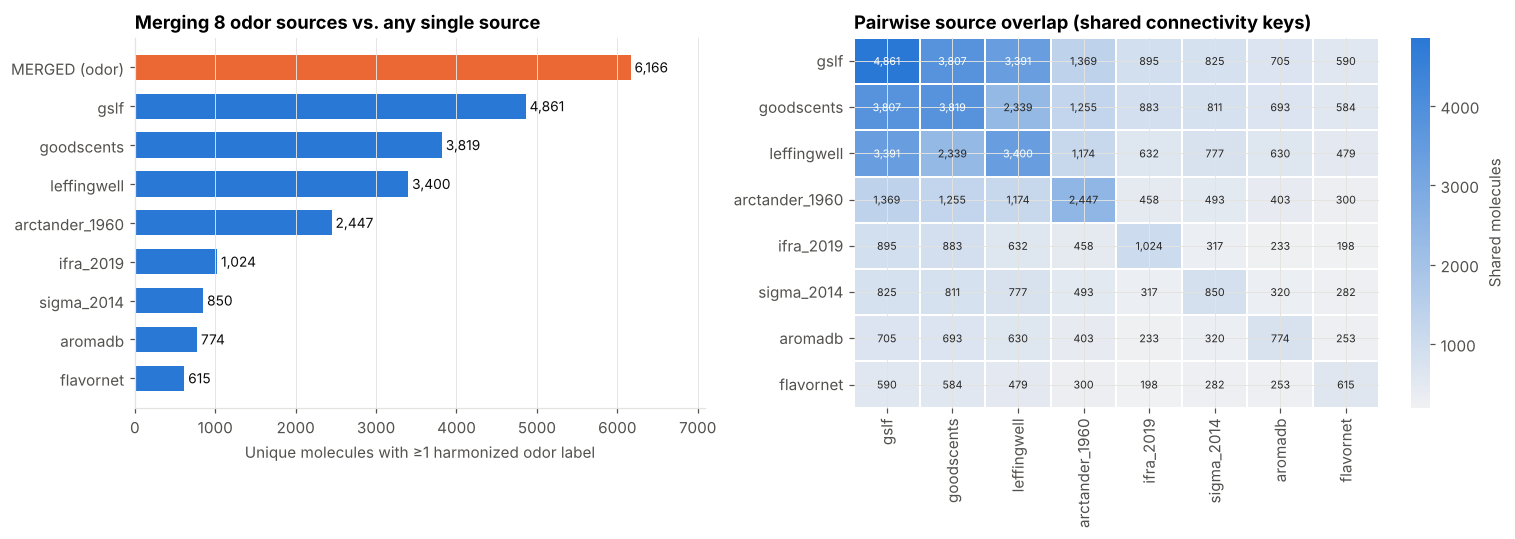

Merged odor set: 6,166 molecules
  = 1.27x the OpenPOM GS-LF benchmark (4,861)
  = 1.61x the largest independent source (goodscents, 3,819)


In [15]:
odor_sources = ["gslf", "goodscents", "leffingwell", "arctander_1960", "sigma_2014", "ifra_2019",
                "flavornet", "aromadb", "flavordb2"]
src_sets = {s: set(odor_ok.loc[odor_ok["source"] == s, "conn_key"]) for s in odor_sources}
src_sets = {s: v for s, v in src_sets.items() if v}
order = sorted(src_sets, key=lambda s: len(src_sets[s]), reverse=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.15]})

# (a) molecules per source vs the merged total
counts = [len(src_sets[s]) for s in order]
merged_n = len(set().union(*src_sets.values()))
ax = axes[0]
ax.barh(order[::-1], counts[::-1], color=CAT[0], height=0.65)
ax.barh(["MERGED (odor)"], [merged_n], color=CAT[1], height=0.65)
for y, v in zip(list(order[::-1]) + ["MERGED (odor)"], counts[::-1] + [merged_n]):
    ax.text(v, y, f" {v:,}", va="center", color=INK, fontsize=9)
ax.set_xlabel("Unique molecules with ≥1 harmonized odor label")
ax.set_title(f"Merging {len(src_sets)} odor sources vs. any single source")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, merged_n * 1.15)

# (b) pairwise overlap (shared molecules), diagonal = source size
ov = pd.DataFrame([[len(src_sets[a] & src_sets[b]) for b in order] for a in order], index=order, columns=order)
sns.heatmap(ov, ax=axes[1], cmap=SEQ_CMAP, annot=True, fmt=",", annot_kws={"fontsize": 7},
            cbar_kws={"label": "Shared molecules"}, linewidths=1, linecolor="white")
axes[1].set_title("Pairwise source overlap (shared connectivity keys)")
plt.tight_layout()
savefig(fig, "01_source_coverage_overlap")
plt.show()

independent = {s: v for s, v in src_sets.items() if s != "gslf"}     # gslf is itself a GoodScents+Leffingwell merge
best_ind = max(independent, key=lambda s: len(independent[s]))
print(f"Merged odor set: {merged_n:,} molecules")
print(f"  = {merged_n / len(src_sets['gslf']):.2f}x the OpenPOM GS-LF benchmark ({len(src_sets['gslf']):,})")
print(f"  = {merged_n / len(independent[best_ind]):.2f}x the largest independent source ({best_ind}, {len(independent[best_ind]):,})")

### 9.2 Label distribution and label noise

Odor labels follow a steep long tail. A few notes (fruity, green, sweet) dominate, while commercially important families (musk, amber, sandalwood) are rare. This drives the choice of metric (AUPRC per label rather than accuracy) and of class weighting in Part 3.

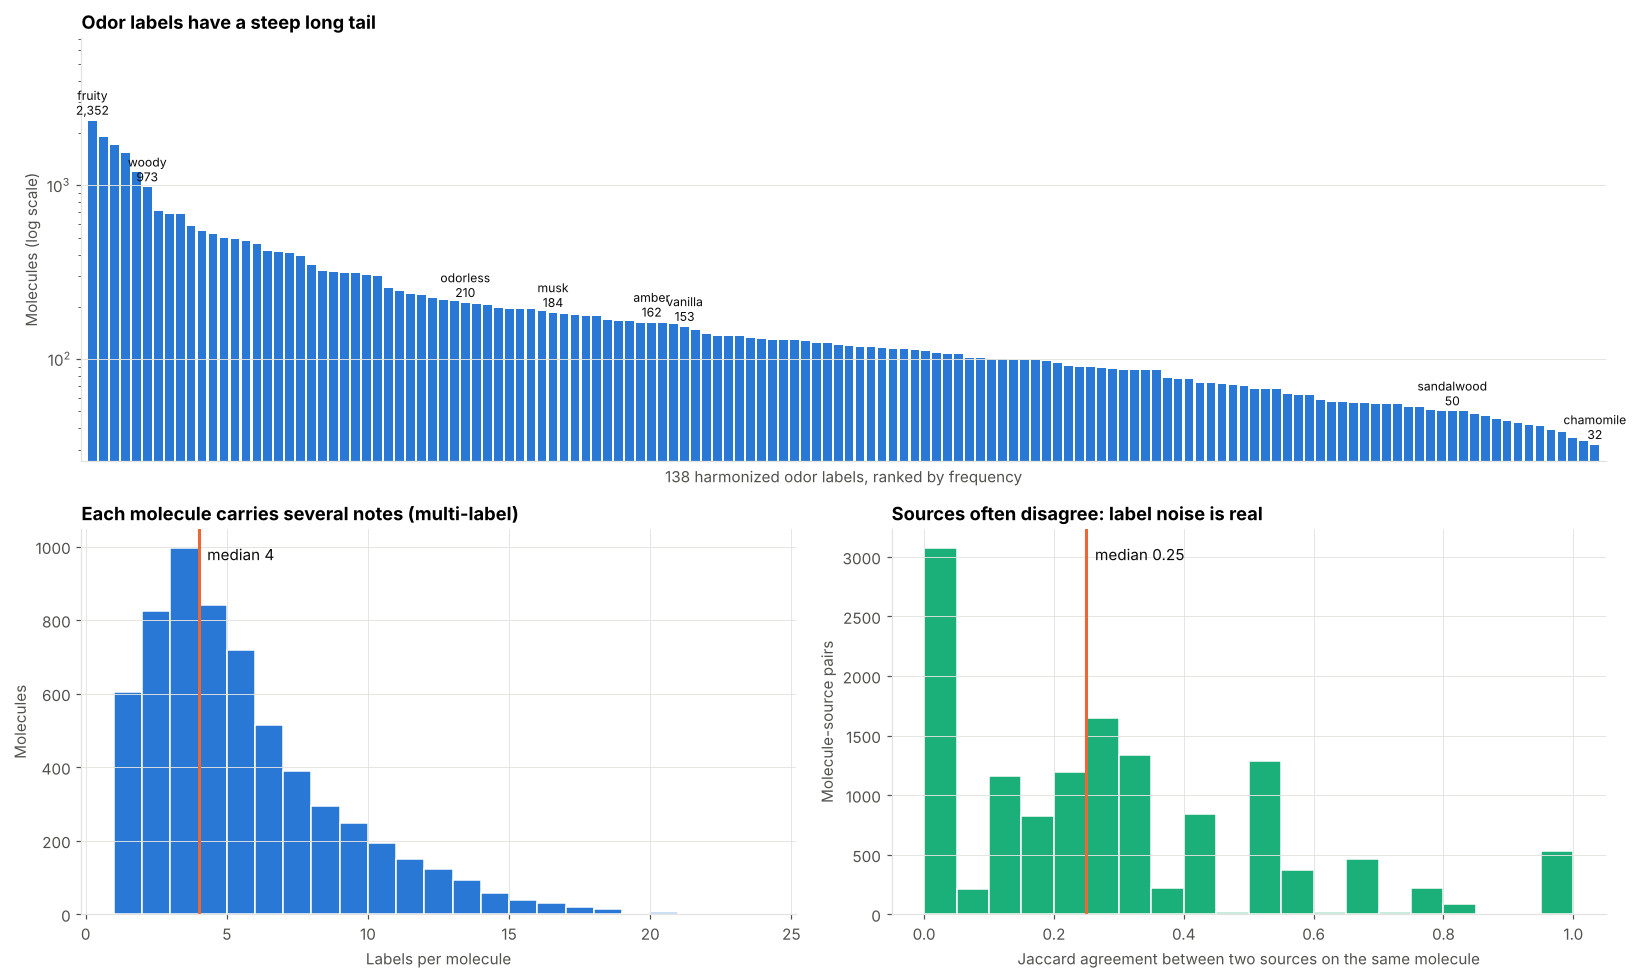

Labels with < 50 positive molecules: 12 of 138


In [16]:
label_freq = (odor_matrix[GSLF_VOCAB].sum().sort_values(ascending=False))
labels_per_mol = odor_matrix[GSLF_VOCAB].sum(axis=1)

fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[1.1, 1])

ax = fig.add_subplot(gs[0, :])
ax.bar(range(len(label_freq)), label_freq.values, color=CAT[0], width=0.8)
highlight = ["fruity", "woody", "odorless", "musk", "amber", "vanilla", "sandalwood", label_freq.index[-1]]
for lab in highlight:
    if lab in label_freq.index:
        i = label_freq.index.get_loc(lab)
        ax.annotate(f"{lab}\n{label_freq[lab]:,}", (i, label_freq[lab]), textcoords="offset points",
                    xytext=(0, 4), ha="center", fontsize=8, color=INK)
ax.set_yscale("log")
ax.set_ylim(top=label_freq.max() * 3)
ax.set_xlim(-1, len(label_freq))
ax.set_xticks([])
ax.set_xlabel(f"{len(label_freq)} harmonized odor labels, ranked by frequency")
ax.set_ylabel("Molecules (log scale)")
ax.set_title("Odor labels have a steep long tail")

ax = fig.add_subplot(gs[1, 0])
ax.hist(labels_per_mol, bins=range(1, int(labels_per_mol.max()) + 2), color=CAT[0], edgecolor="white")
ax.axvline(labels_per_mol.median(), color=CAT[1], lw=2)
ax.text(labels_per_mol.median(), ax.get_ylim()[1] * 0.92, f"  median {labels_per_mol.median():.0f}", color=INK)
ax.set_xlabel("Labels per molecule")
ax.set_ylabel("Molecules")
ax.set_title("Each molecule carries several notes (multi-label)")

ax = fig.add_subplot(gs[1, 1])
ax.hist(agreement["jaccard"], bins=20, range=(0, 1), color=CAT[2], edgecolor="white")
ax.axvline(agreement["jaccard"].median(), color=CAT[1], lw=2)
ax.text(agreement["jaccard"].median(), ax.get_ylim()[1] * 0.92, f"  median {agreement['jaccard'].median():.2f}",
        color=INK)
ax.set_xlabel("Jaccard agreement between two sources on the same molecule")
ax.set_ylabel("Molecule-source pairs")
ax.set_title("Sources often disagree: label noise is real")
plt.tight_layout()
savefig(fig, "02_label_distribution_noise")
plt.show()

print(f"Labels with < 50 positive molecules: {(label_freq < 50).sum()} of {len(label_freq)}")

### 9.3 Odor vs taste chemical space

The expectation is that odorants are small, volatile, and lipophilic, while tastants (sugars, glycosides, peptides, alkaloids, acids) are larger and more polar. Checking this on the merged data confirms the database behaves chemically, and it motivates modeling the two tracks separately.

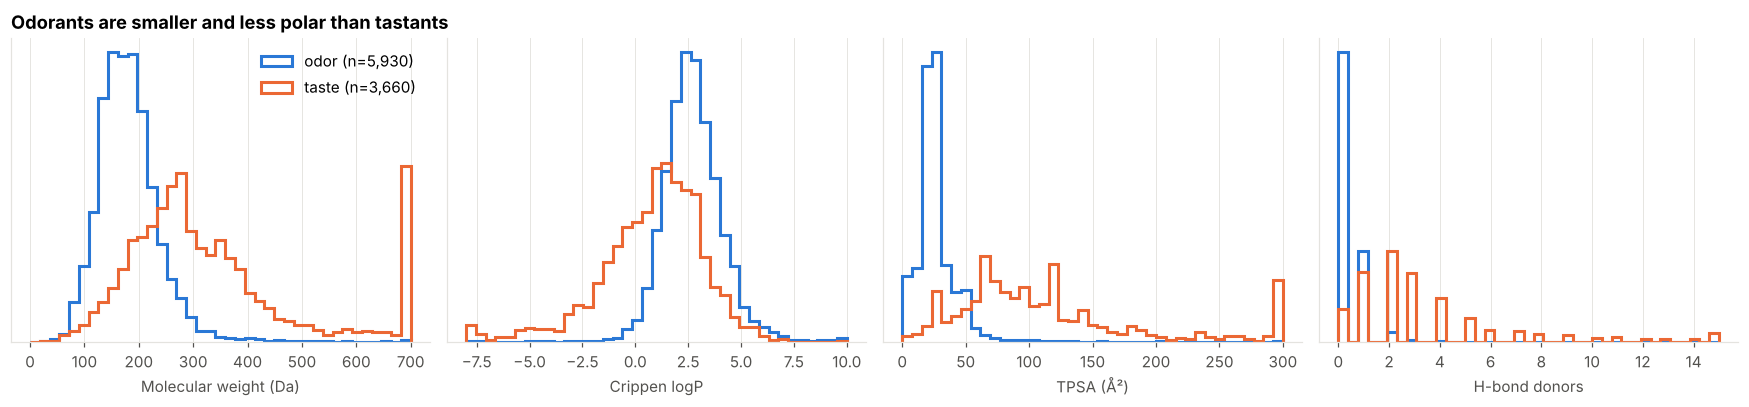

Median MW  odor 174 Da | taste 287 Da
Odorants with MW < 300 Da: 97.4%


In [17]:
mol_idx = molecules.set_index("conn_key")
odor_only = mol_idx[mol_idx["has_odor_labels"] & ~mol_idx["has_taste_labels"]]
taste_any = mol_idx[mol_idx["has_taste_labels"]]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (col, lab, lim) in zip(axes, [("mw", "Molecular weight (Da)", (0, 700)), ("logp", "Crippen logP", (-8, 10)),
                                       ("tpsa", "TPSA (Å²)", (0, 300)), ("hbd", "H-bond donors", (0, 15))]):
    bins = np.linspace(*lim, 40)
    ax.hist(odor_only[col].clip(*lim), bins=bins, density=True, color=CAT[0], histtype="step", lw=2,
            label=f"odor (n={len(odor_only):,})")
    ax.hist(taste_any[col].clip(*lim), bins=bins, density=True, color=CAT[1], histtype="step", lw=2,
            label=f"taste (n={len(taste_any):,})")
    ax.set_xlabel(lab)
    ax.set_yticks([])
axes[0].legend(loc="upper right")
axes[0].set_title("Odorants are smaller and less polar than tastants")
plt.tight_layout()
savefig(fig, "03_odor_vs_taste_physchem")
plt.show()

print(f"Median MW  odor {odor_only['mw'].median():.0f} Da | taste {taste_any['mw'].median():.0f} Da")
print(f"Odorants with MW < 300 Da: {(odor_only['mw'] < 300).mean():.1%}")

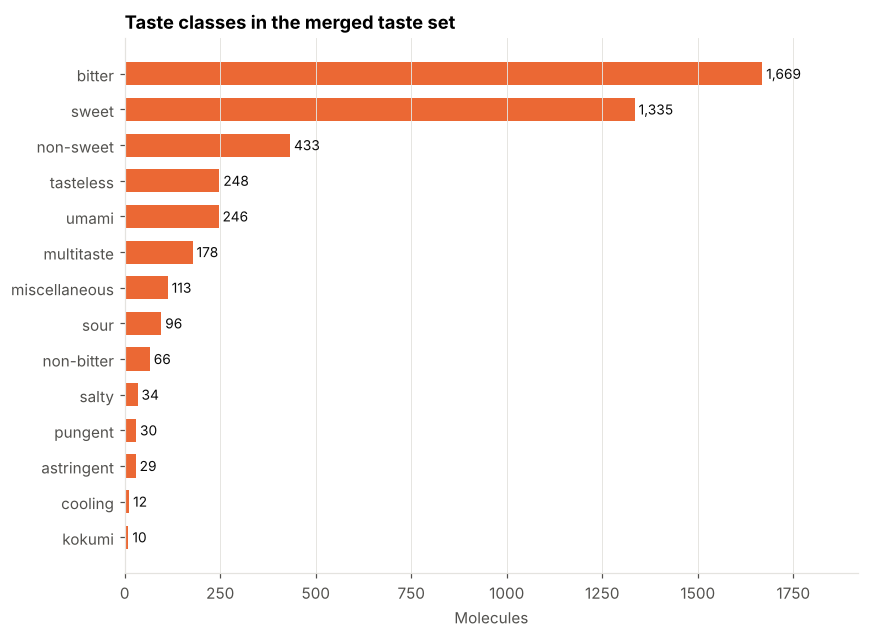

Molecules per taste class and contributing source:
source         chemtastesdb  sweetenersdb
label                                    
astringent               29             0
bitter                 1669             0
cooling                  12             0
kokumi                   10             0
miscellaneous           113             0
multitaste              178             0
non-bitter               66             0
non-sweet               433             0
pungent                  30             0
salty                    34             0
sour                     96             0
sweet                  1322           292
tasteless               248             0
umami                   246             0


In [18]:
if len(taste_matrix):
    tcount = taste_matrix.drop(columns="smiles").sum().sort_values()
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(tcount) + 1))
    ax.barh(tcount.index, tcount.values, color=CAT[1], height=0.65)
    for y, v in zip(tcount.index, tcount.values):
        ax.text(v, y, f" {v:,}", va="center", fontsize=9, color=INK)
    ax.set_xlabel("Molecules")
    ax.set_title("Taste classes in the merged taste set")
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, tcount.max() * 1.15)
    plt.tight_layout()
    savefig(fig, "04_taste_classes")
    plt.show()
    by_source = (taste_labels.assign(source=taste_labels["sources"].str.split(";")).explode("source")
                 .pivot_table(index="label", columns="source", values="conn_key", aggfunc="count", fill_value=0))
    print("Molecules per taste class and contributing source:")
    print(by_source.to_string())

### 9.4 Stereochemistry: where 2D models are blind

Default Morgan fingerprints are achiral, so (R)- and (S)-limonene produce identical bit vectors. The database tracks stereo variants explicitly. This cell finds **enantiomer pairs** (mirror images, detected by inverting every tetrahedral centre) and **diastereomer / E-Z pairs** that carry odor descriptions.

One caveat makes the analysis honest. Two *different sources* describing the same molecule agree only ~25% of the time (Section 7), so cross-source comparisons would mostly measure source noise. Pairs are therefore compared **within the same source**: the same expert describing both isomers.

In [19]:
def invert_tetrahedral(smi):
    """Mirror image: swap every @ and @@ (double-bond geometry is unchanged)."""
    swapped = smi.replace("@@", "\x00").replace("@", "@@").replace("\x00", "@")
    m = Chem.MolFromSmiles(swapped)
    return Chem.MolToSmiles(m) if m else None


stereo_rec = odor_ok[(odor_ok["n_stereocenters"] + odor_ok["n_stereo_bonds"] > 0) & (odor_ok["n_unassigned_stereo"] == 0)]
by_src = (stereo_rec.groupby(["source", "conn_key", "inchikey"])
          .agg(labels=("labels", lambda L: frozenset().union(*map(frozenset, L))),
               name=("name", lambda s: best_name(s) or ""),
               smiles=("smiles_std", "first")).reset_index())
by_src = by_src[by_src["source"] != "gslf"]
# borrow a readable name from any source that knows this exact stereoisomer
by_src["name"] = by_src["inchikey"].map(stereo_variants.set_index("inchikey")["name"]).fillna(by_src["name"])

pairs = []
for (src, ck), g in by_src.groupby(["source", "conn_key"]):
    if len(g) < 2:
        continue
    rows = list(g.itertuples(index=False))
    for i in range(len(rows)):
        for j in range(i + 1, len(rows)):
            a, b = rows[i], rows[j]
            kind = "enantiomers" if invert_tetrahedral(a.smiles) == b.smiles else "diastereomers / E-Z"
            pairs.append({"source": src, "conn_key": ck, "kind": kind,
                          "jaccard": len(a.labels & b.labels) / len(a.labels | b.labels),
                          "isomer_1": a.name[:30], "smiles_1": a.smiles, "labels_1": ", ".join(sorted(a.labels)),
                          "isomer_2": b.name[:30], "smiles_2": b.smiles, "labels_2": ", ".join(sorted(b.labels))})
stereo_pairs = pd.DataFrame(pairs)

print(f"Molecules with ≥1 stereocentre: {(molecules['n_stereocenters'] > 0).mean():.1%}")
print(stereo_pairs.groupby("kind").agg(pairs=("jaccard", "size"), median_jaccard=("jaccard", "median"),
                                       described_differently=("jaccard", lambda j: (j < 1).mean())).round(2))
pd.set_option("display.max_colwidth", 60)
(stereo_pairs[stereo_pairs["kind"] == "enantiomers"].sort_values("jaccard")
 [["source", "isomer_1", "smiles_1", "labels_1", "isomer_2", "smiles_2", "labels_2", "jaccard"]].head(12))

Molecules with ≥1 stereocentre: 49.2%
                     pairs  median_jaccard  described_differently
kind                                                             
diastereomers / E-Z    295            0.40                   0.79
enantiomers            102            0.33                   0.83


,source,isomer_1,smiles_1,labels_1,isomer_2,smiles_2,labels_2,jaccard
16,aromadb,trans-furan linalool oxide,C=C[C@@]1(C)CC[C@H](C(C)(C)O)O1,citrus,trans-linalool oxide,C=C[C@]1(C)CC[C@@H](C(C)(C)O)O1,floral,0.0
61,flavornet,3033-23-6,CC(C)=C[C@@H]1C[C@H](C)CCO1,"rose, sweet",(+)-cis-rose oxide,CC(C)=C[C@H]1C[C@@H](C)CCO1,"floral, green",0.0
59,flavornet,(+)-trans-limonene oxide,C=C(C)[C@@H]1CC[C@]2(C)O[C@@H]2C1,green,42477-94-1,C=C(C)[C@H]1CC[C@@]2(C)O[C@H]2C1,"citrus, fresh",0.0
101,goodscents,unii-n1me467ava,C=C[C@@]1(C)CC[C@@H](O)C(C)(C)O1,earthy,unii-p6b6jd2n2z,C=C[C@]1(C)CC[C@H](O)C(C)(C)O1,"creamy, floral, sweet",0.0
90,flavornet,Nootkatone,C=C(C)[C@@H]1CCC2=CC(=O)C[C@@H](C)[C@]2(C)C1,grapefruit,(-)-nootkatone,C=C(C)[C@H]1CCC2=CC(=O)C[C@H](C)[C@@]2(C)C1,terpenic,0.0
86,flavornet,cis-whiskey lactone,CCCC[C@H]1OC(=O)C[C@H]1C,spicy,unii-dr7kre2ajv,CCCC[C@@H]1OC(=O)C[C@@H]1C,coconut,0.0
83,flavornet,Carvone-l,C=C(C)[C@@H]1CC=C(C)C(=O)C1,mint,d-carvone,C=C(C)[C@H]1CC=C(C)C(=O)C1,spicy,0.0
81,flavornet,levomenol,CC(C)=CCC[C@](C)(O)[C@@H]1CC=C(C)CC1,herbal,alpha-bisabolol,CC(C)=CCC[C@@](C)(O)[C@H]1CC=C(C)CC1,"floral, spicy",0.0
132,goodscents,(3s)-1-nonen-3-ol,C=C[C@@H](O)CCCCCC,"aldehydic, metallic",unii-09rwu9uwk9,C=C[C@H](O)CCCCCC,"cheesy, fruity, mushroom",0.0
114,goodscents,(+)-trans-limonene oxide,C=C(C)[C@@H]1CC[C@]2(C)O[C@@H]2C1,green,42477-94-1,C=C(C)[C@H]1CC[C@@]2(C)O[C@H]2C1,"citrus, fresh",0.0


In [20]:
# The textbook case: carvone. Query the database directly.
with sqlite3.connect(DB_PATH) as con:
    carvone = pd.read_sql("""
        SELECT sv.inchikey, sv.smiles_isomeric, sv.name, sv.sources
        FROM stereo_variants sv JOIN molecules m ON m.conn_key = sv.conn_key
        WHERE m.conn_key = 'ULDHMXUKGWMISQ'""", con)
carvone_labels = (odor_ok[odor_ok["conn_key"] == "ULDHMXUKGWMISQ"]
                  .groupby("inchikey")["labels"].agg(lambda L: sorted(set().union(*map(set, L)))))
carvone["labels"] = carvone["inchikey"].map(carvone_labels)
carvone

,inchikey,smiles_isomeric,name,sources,labels
0,ULDHMXUKGWMISQ-SECBINFHSA-N,C=C(C)[C@@H]1CC=C(C)C(=O)C1,Carvone-l,aromadb;dravnieks_1985;flavornet;goodscents;sigma_2014,"[herbal, mint, sweet]"
1,ULDHMXUKGWMISQ-UHFFFAOYSA-N,C=C(C)C1CC=C(C)C(=O)C1,(-)-Carvone,arctander_1960;flavornet;goodscents;gslf;keller_2016,"[anisic, floral, herbal, mint, spicy, sweet]"
2,ULDHMXUKGWMISQ-VIFPVBQESA-N,C=C(C)[C@H]1CC=C(C)C(=O)C1,d-carvone,aromadb;flavornet;goodscents;sigma_2014,"[malty, mint, spicy]"


## 10. Part 1 summary

**What was built:** a single SQLite database merging nine aroma sources, two human-panel datasets, and the taste databases. Every structure is standardized, every label is harmonized to the 138-term GS-LF ontology, and every assertion keeps its sources. The printed numbers above (molecule counts, coverage, agreement) are generated live from the data and are not hard-coded.

**Findings worth stating in the interview**

1. **Merging pays.** The merged odor set is substantially larger than any single public source (see 9.1), and the extra molecules come from catalogues and handbooks with different chemistry coverage.
2. **Label noise sets a ceiling.** Two expert sources describing the same molecule agree only partially (median Jaccard in 7). A model cannot be expected to beat the agreement between human experts, so this sets expectations for Part 3 metrics.
3. **The long tail is where the business is.** Musk, amber, and sandalwood are among the rarest labels. Per-label AUPRC and grouped validation matter more than headline accuracy.
4. **Stereo matters and is tracked.** Some skeletons have enantiomers or diastereomers that experts describe differently. Achiral 2D fingerprints cannot separate them, and Part 2 addresses this.

**Next: Part 2.** Featurization (chirality-aware Morgan counts, RDKit 2D descriptors, MACCS, pretrained embeddings), chemical-space maps (PCA/UMAP coloured by odor family), scaffold and cluster analysis, and the leakage-safe grouped train/validation/test split that all models in Part 3 will share.

---

# Part 2: Featurization, Chemical Space, and Leakage-Safe Splits
### AI-Driven Discovery of Novel Aroma and Taste Molecules

**Input:** the SQLite database from Part 1 (`data/processed/aroma_taste.sqlite`).
**Output:** feature matrices in `data/features/`, a reusable featurizer module `src/aroma_features.py`, and fixed train/validation/test splits in `data/splits/`. Parts 3 and 4 use these unchanged, so every model is compared on identical data.

| Section | Question it answers |
|---|---|
| 1 | Which molecular representations, and why each one suits olfaction or taste |
| 2 | Are the features healthy (sparsity, bit collisions, redundancy)? |
| 3 | What does the chemical space look like, and do odor families cluster? |
| 4 | Why scaffold splits fail for odorants, and what to use instead |
| 5 | How much does each split strategy leak? (nearest-neighbour similarity, train → test) |
| 6 | Chirality: what achiral fingerprints cannot see |

## 0. Setup

In [21]:
import json
import sqlite3
import time
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse

from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.SimDivFilters import rdSimDivPickers
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="umap")
warnings.filterwarnings("ignore", module="tqdm")

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

PROJECT_ROOT = Path.cwd()
DB_PATH = PROJECT_ROOT / "data" / "processed" / "aroma_taste.sqlite"
FEAT_DIR = PROJECT_ROOT / "data" / "features"
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
FIG_DIR = PROJECT_ROOT / "figures"
SRC_DIR = PROJECT_ROOT / "src"
for p in (FEAT_DIR, SPLIT_DIR, FIG_DIR, SRC_DIR):
    p.mkdir(parents=True, exist_ok=True)
if not DB_PATH.exists():
    raise FileNotFoundError("Run Part 1 first: data/processed/aroma_taste.sqlite is missing.")

CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
OTHER = "#c9c8c2"
SEQ_CMAP = sns.light_palette("#2a78d6", as_cmap=True)
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK_2, "ytick.color": INK_2,
    "legend.frameon": False, "figure.facecolor": "white"})


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")


with sqlite3.connect(DB_PATH) as con:
    molecules = pd.read_sql("SELECT * FROM molecules", con).set_index("conn_key")
    stereo_variants = pd.read_sql("SELECT * FROM stereo_variants", con)
    odor_labels = pd.read_sql("SELECT * FROM odor_labels", con)
    taste_labels = pd.read_sql("SELECT * FROM taste_labels", con)

odor_y = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "odor_multilabel.csv.gz", index_col=0)
taste_y = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "taste_multilabel.csv.gz", index_col=0)
ODOR_LABELS = [c for c in odor_y.columns if c != "smiles"]
TASTE_LABELS = [c for c in taste_y.columns if c != "smiles"]
print(f"molecules: {len(molecules):,} | odor task: {len(odor_y):,} x {len(ODOR_LABELS)} | "
      f"taste task: {len(taste_y):,} x {len(TASTE_LABELS)}")

molecules: 9,775 | odor task: 6,166 x 138 | taste task: 3,660 x 14


## 1. Molecular representations

Each representation answers a different question, so all of them are computed once and the models in Part 3 are compared on each.

| Block | Size | Why it matters for odor and taste |
|---|---|---|
| **Morgan counts** (ECFP4-like, radius 2) | 2,048 | Local substructures, the core of structure–odor relationships (an ester group, a C9–C11 aldehyde chain, a furanone ring). **Counts** keep chain length and repetition (e.g. hexyl vs octyl), which bits lose. |
| **Morgan, chirality-aware** | 2,048 | Same, but tetrahedral stereo is hashed in. Used in Section 6 on stereoisomers. |
| **MACCS keys** | 167 | Expert-defined substructure keys. Interpretable, and robust on small data. |
| **RDKit 2D descriptors** | ~210 | Bulk physchem: size, polarity, H-bonding, shape indices. Volatility and receptor fit are driven largely by these. |
| **F&F functional groups** (SMARTS) | 30 | Chemist-defined odorant motifs: esters, lactones, thiols, pyrazines, macrocycles, and others. Directly interpretable, and they double as rules to sanity-check model explanations in Part 4. |

The featurizer is written to `src/aroma_features.py`, so Part 4 can score new candidate molecules with *exactly* the same code that produced the training features.

In [22]:
%%writefile src/aroma_features.py
"""Featurizers shared by all parts of the aroma & taste project."""
import numpy as np
from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, MACCSkeys, rdFingerprintGenerator

N_BITS = 2048
_morgan = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=N_BITS)
_morgan_chiral = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=N_BITS, includeChirality=True)
DESCRIPTOR_NAMES = [n for n, _ in Descriptors._descList]

# Flavor & fragrance functional groups (SMARTS). Kept deliberately readable: these double as
# chemist-facing explanations in Part 4.
FF_GROUPS = {
    "ester":            "[CX3](=O)[OX2][#6]",
    "lactone":          "[#6][CX3;R](=O)[OX2;R][#6;R]",
    "aldehyde":         "[CX3H1](=O)[#6]",
    "ketone":           "[#6][CX3;!R](=O)[#6]",
    "cyclic_ketone":    "[#6;R][CX3;R](=O)[#6;R]",
    "alcohol":          "[OX2H][CX4]",
    "phenol":           "[OX2H]c",
    "carboxylic_acid":  "[CX3](=O)[OX2H1]",
    "ether":            "[OD2;!$(OC=O)]([#6])[#6]",
    "acetal":           "[CX4]([OX2][#6])[OX2][#6]",
    "thiol":            "[SX2H]",
    "sulfide":          "[#6][SX2][#6]",
    "disulfide":        "[#6]SS[#6]",
    "thioester":        "[CX3](=O)[SX2]",
    "isothiocyanate":   "N=C=S",
    "amine":            "[NX3;H2,H1,H0;!$(NC=O);!$(N-a);!$(N=*)]",
    "amide":            "[NX3][CX3](=O)",
    "nitrile":          "[CX2]#N",
    "pyrazine":         "c1cnccn1",
    "pyridine":         "c1ccncc1",
    "thiazole":         "c1cscn1",
    "furan":            "c1ccoc1",
    "thiophene":        "c1ccsc1",
    "pyrrole_indole":   "[nH]1cccc1",
    "benzene":          "c1ccccc1",
    "methoxy_aryl":     "[CH3][OX2]c",
    "conj_carbonyl":    "[CX3]=[CX3][CX3]=O",
    "terminal_alkene":  "[CH2]=[CX3]",
    "gem_dimethyl":     "[CH3][CX4]([CH3])",
    "macrocycle":       "[r{12-}]",
}
_FF_PATTERNS = {k: Chem.MolFromSmarts(v) for k, v in FF_GROUPS.items()}


def mol_from_smiles(smi):
    return Chem.MolFromSmiles(smi) if isinstance(smi, str) else None


def morgan_counts(mol, chiral=False):
    gen = _morgan_chiral if chiral else _morgan
    arr = np.zeros(N_BITS, dtype=np.uint8)
    fp = gen.GetCountFingerprintAsNumPy(mol)
    np.minimum(fp, 255, out=arr, casting="unsafe")
    return arr


def morgan_bitvect(mol, chiral=False):
    return (_morgan_chiral if chiral else _morgan).GetFingerprint(mol)


def maccs(mol):
    arr = np.zeros(167, dtype=np.uint8)
    DataStructs.ConvertToNumpyArray(MACCSkeys.GenMACCSKeys(mol), arr)
    return arr


def rdkit_descriptors(mol):
    out = np.full(len(DESCRIPTOR_NAMES), np.nan, dtype=np.float64)
    for i, (_, fn) in enumerate(Descriptors._descList):
        try:
            out[i] = fn(mol)
        except Exception:
            pass
    return out


def ff_groups(mol):
    return np.array([len(mol.GetSubstructMatches(p)) for p in _FF_PATTERNS.values()], dtype=np.int16)


def featurize(smiles_list):
    """Return dict of feature blocks (numpy arrays, rows aligned with smiles_list)."""
    mols = [mol_from_smiles(s) for s in smiles_list]
    bad = [i for i, m in enumerate(mols) if m is None]
    if bad:
        raise ValueError(f"{len(bad)} SMILES failed to parse, e.g. {smiles_list[bad[0]]!r}")
    return {
        "morgan": np.vstack([morgan_counts(m) for m in mols]),
        "maccs": np.vstack([maccs(m) for m in mols]),
        "rdkit2d": np.vstack([rdkit_descriptors(m) for m in mols]),
        "ffgroups": np.vstack([ff_groups(m) for m in mols]),
    }

Writing src/aroma_features.py


In [23]:
import importlib
import src.aroma_features as af
importlib.reload(af)

# Featurize every molecule once (odor and taste tasks are row subsets of this table).
t0 = time.time()
all_keys = molecules.index.to_numpy()
blocks = af.featurize(molecules["smiles"].tolist())
print(f"Featurized {len(all_keys):,} molecules in {time.time() - t0:.0f}s")
for k, v in blocks.items():
    print(f"  {k:9s} {v.shape}  dtype={v.dtype}")

Featurized 9,775 molecules in 67s
  morgan    (9775, 2048)  dtype=uint8
  maccs     (9775, 167)  dtype=uint8
  rdkit2d   (9775, 217)  dtype=float64
  ffgroups  (9775, 30)  dtype=int16


## 2. Feature quality control

A feature that is constant, infinite, or a near-duplicate of another adds noise and slows models without adding information. The checks below are the standard ones before modelling:

* **Descriptors:** replace infinities, drop columns that are mostly missing or constant, and median-impute the rest. Imputation statistics are saved so new molecules are treated the same way. In Part 3 they are refitted inside each training fold; here they are only used for EDA.
* **Highly correlated descriptor pairs** (|r| > 0.95) are reported. Tree models tolerate them; linear models and SHAP attribution do not, so a pruned list is saved too.
* **Morgan bit collisions:** how often distinct substructures share a bit at 2,048 bits. This decides whether a larger folding size is worth it.

In [24]:
desc = pd.DataFrame(blocks["rdkit2d"], index=all_keys, columns=af.DESCRIPTOR_NAMES)
desc = desc.replace([np.inf, -np.inf], np.nan)
desc = desc.mask(desc.abs() > 1e10)                       # a few descriptors explode on odd structures
missing = desc.isna().mean()
constant = desc.nunique(dropna=True) <= 1
keep = missing.index[(missing < 0.05) & ~constant]
desc_clean = desc[keep].fillna(desc[keep].median())
print(f"RDKit descriptors: {desc.shape[1]} computed -> {len(keep)} kept "
      f"({int(constant.sum())} constant, {int((missing >= 0.05).sum())} mostly missing)")

corr = desc_clean.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
to_drop = [c for c in upper.columns if (upper[c] > 0.95).any()]
desc_pruned_cols = [c for c in desc_clean.columns if c not in to_drop]
print(f"Correlation pruning (|r| > 0.95): {len(desc_pruned_cols)} of {len(keep)} descriptors remain")

# Morgan bit collisions: unhashed radius-2 environments vs folded bits
from rdkit.Chem import rdFingerprintGenerator
_sparse_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2)
sample = rng.choice(len(all_keys), size=min(3000, len(all_keys)), replace=False)
envs = set()
for i in sample:
    envs |= set(_sparse_gen.GetSparseCountFingerprint(Chem.MolFromSmiles(molecules["smiles"].iat[i]))
                .GetNonzeroElements())
folded = {e % af.N_BITS for e in envs}
print(f"Morgan r=2: {len(envs):,} distinct environments in a {len(sample):,}-molecule sample -> "
      f"{len(folded):,} occupied bits of {af.N_BITS} ({1 - len(folded) / len(envs):.0%} of environments share a bit)")

morgan = blocks["morgan"]
print(f"Morgan counts: {(morgan > 0).sum(1).mean():.1f} non-zero bits per molecule; "
      f"{((morgan > 0).sum(0) == 0).mean():.1%} of bits never used")

RDKit descriptors: 217 computed -> 212 kept (5 constant, 0 mostly missing)


Correlation pruning (|r| > 0.95): 160 of 212 descriptors remain


Morgan r=2: 10,901 distinct environments in a 3,000-molecule sample -> 2,040 occupied bits of 2048 (81% of environments share a bit)
Morgan counts: 29.0 non-zero bits per molecule; 0.0% of bits never used


**Interpretation.** Collisions at 2,048 bits are tolerable for tree ensembles. For attribution in Part 4, unfolded environments (via RDKit `bitInfo`) are mapped back to atoms, so explanations are not blurred by collisions.

In [25]:
# ---------------- persist feature blocks ----------------
np.savez_compressed(FEAT_DIR / "features_all.npz", conn_key=all_keys,
                    morgan=blocks["morgan"], maccs=blocks["maccs"], ffgroups=blocks["ffgroups"],
                    rdkit2d=desc_clean.to_numpy(np.float32))
meta = {"rdkit2d_columns": list(desc_clean.columns), "rdkit2d_pruned_columns": desc_pruned_cols,
        "rdkit2d_medians": desc[keep].median().to_dict(), "ff_groups": af.FF_GROUPS,
        "morgan": {"radius": 2, "n_bits": af.N_BITS, "counts": True, "chirality": False}}
(FEAT_DIR / "features_meta.json").write_text(json.dumps(meta, indent=1))
print("Saved:", sorted(p.name for p in FEAT_DIR.iterdir()))

Saved: ['features_all.npz', 'features_meta.json']


### 2.1 Do the functional groups behave as chemists expect?

A quick check that the features carry real signal before any ML: the enrichment of each functional group in molecules with a given odor note, relative to the dataset base rate. If esters were *not* enriched in "fruity", or thiols in "sulfurous", something would be wrong upstream.

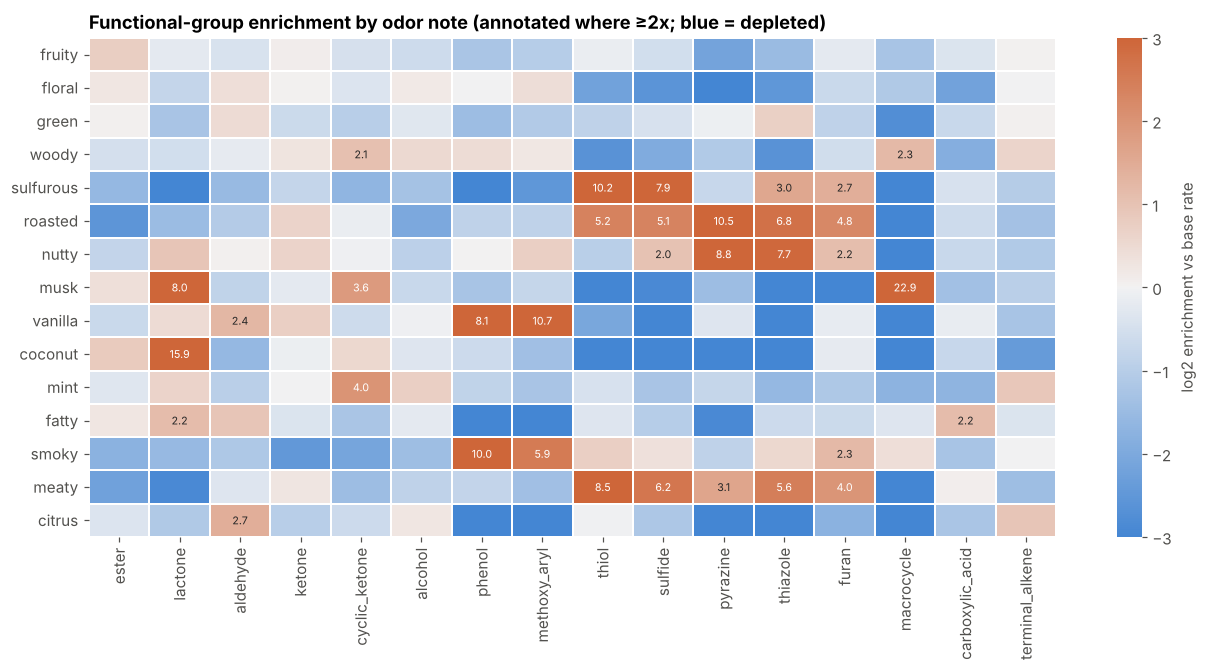

        ester in 'fruity': 1.7x base rate
        thiol in 'sulfurous': 10.2x base rate
     pyrazine in 'roasted': 10.5x base rate
     pyrazine in 'nutty': 8.8x base rate
      lactone in 'coconut': 15.9x base rate
   macrocycle in 'musk': 22.9x base rate
 methoxy_aryl in 'vanilla': 10.7x base rate
       phenol in 'smoky': 10.0x base rate


In [26]:
ff = pd.DataFrame(blocks["ffgroups"] > 0, index=all_keys, columns=list(af.FF_GROUPS)).astype(int)
Yo = odor_y[ODOR_LABELS]
ffo = ff.loc[Yo.index]
notes = ["fruity", "floral", "green", "woody", "sulfurous", "roasted", "nutty", "musk", "vanilla",
         "coconut", "minty" if "minty" in Yo else "mint", "fatty", "smoky", "meaty", "citrus"]
notes = [n for n in notes if n in Yo.columns]
groups = ["ester", "lactone", "aldehyde", "ketone", "cyclic_ketone", "alcohol", "phenol", "methoxy_aryl",
          "thiol", "sulfide", "pyrazine", "thiazole", "furan", "macrocycle", "carboxylic_acid", "terminal_alkene"]
base = ffo[groups].mean()
enr = pd.DataFrame({n: (ffo.loc[Yo[n] == 1, groups].mean() + 1e-3) / (base + 1e-3) for n in notes}).T
log_enr = np.log2(enr).clip(-3, 3)

fig, ax = plt.subplots(figsize=(12, 6.2))
sns.heatmap(log_enr, ax=ax, cmap=sns.diverging_palette(250, 25, s=80, l=55, as_cmap=True), center=0,
            vmin=-3, vmax=3, linewidths=1, linecolor="white", cbar_kws={"label": "log2 enrichment vs base rate"},
            annot=enr.round(1).where(enr >= 2).astype(object).where(enr >= 2, ""), fmt="", annot_kws={"fontsize": 7})
ax.grid(False)
ax.set_title("Functional-group enrichment by odor note (annotated where ≥2x; blue = depleted)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
savefig(fig, "p2_01_ffgroup_enrichment")
plt.show()

checks = [("ester", "fruity"), ("thiol", "sulfurous"), ("pyrazine", "roasted"), ("pyrazine", "nutty"),
          ("lactone", "coconut"), ("macrocycle", "musk"), ("methoxy_aryl", "vanilla"), ("phenol", "smoky")]
for g, n in checks:
    if n in enr.index:
        print(f"{g:>13s} in '{n}': {enr.loc[n, g]:.1f}x base rate")

## 3. Chemical space

Two complementary views:

* **PCA on scaled RDKit descriptors:** linear and interpretable. The axes can be read as size/polarity directions.
* **UMAP on Morgan counts** (Jaccard metric): non-linear, and preserves substructure neighbourhoods. It is the standard view for "do similar structures smell alike?"

Both are coloured by odor family, a coarse grouping of the 138 labels used only for visualisation, and by task (odor vs taste).

In [27]:
FAMILIES = {   # visual grouping only; priority order resolves molecules with several families
    "sulfurous / savory": ["sulfurous", "alliaceous", "garlic", "onion", "meaty", "beefy", "savory", "cabbage"],
    "musk / amber":       ["musk", "amber", "animal"],
    "woody / earthy":     ["woody", "cedar", "sandalwood", "vetiver", "earthy", "pine", "camphoreous"],
    "roasted / nutty":    ["roasted", "nutty", "coffee", "cocoa", "popcorn", "burnt", "hazelnut", "almond"],
    "floral":             ["floral", "rose", "jasmin", "muguet", "violet", "lily", "hyacinth", "orangeflower", "lavender"],
    "citrus / fresh":     ["citrus", "lemon", "orange", "grapefruit", "bergamot", "aldehydic"],
    "fruity":             ["fruity", "apple", "pear", "banana", "pineapple", "berry", "peach", "tropical", "grape"],
    "green":              ["green", "grassy", "leafy", "cucumber", "vegetable"],
}
FAMILY_ORDER = list(FAMILIES)


def odor_family(row):
    for fam in FAMILY_ORDER:
        if any(row.get(l, 0) for l in FAMILIES[fam]):
            return fam
    return "other"


family = Yo.apply(odor_family, axis=1)
print(family.value_counts().to_string())

task = pd.Series("other", index=all_keys)
task[molecules["has_odor_labels"].astype(bool).to_numpy()] = "odor"
task[molecules["has_taste_labels"].astype(bool).to_numpy()] = "taste"
task[(molecules["has_odor_labels"].astype(bool) & molecules["has_taste_labels"].astype(bool)).to_numpy()] = "odor + taste"

woody / earthy        1220
floral                1209
fruity                 975
other                  787
sulfurous / savory     712
roasted / nutty        438
musk / amber           426
citrus / fresh         211
green                  188


In [28]:
import umap

X_desc = StandardScaler().fit_transform(desc_clean[desc_pruned_cols])
pca = PCA(n_components=10, random_state=RANDOM_SEED).fit(X_desc)
pc = pca.transform(X_desc)[:, :2]

t0 = time.time()
reducer = umap.UMAP(n_neighbors=30, min_dist=0.15, metric="jaccard", random_state=RANDOM_SEED)
um = reducer.fit_transform((blocks["morgan"] > 0).astype(bool))
print(f"UMAP: {time.time() - t0:.0f}s | PCA variance explained by PC1+PC2: {pca.explained_variance_ratio_[:2].sum():.1%}")
emb = pd.DataFrame({"pc1": pc[:, 0], "pc2": pc[:, 1], "u1": um[:, 0], "u2": um[:, 1], "task": task.values},
                   index=all_keys)
emb["family"] = family.reindex(emb.index)
emb.to_csv(FEAT_DIR / "embedding_2d.csv")

# top PCA loadings, so the axes can be named
load = pd.DataFrame(pca.components_[:2].T, index=desc_pruned_cols, columns=["PC1", "PC2"])
for pcn in ["PC1", "PC2"]:
    top = load[pcn].abs().sort_values(ascending=False).head(5).index
    print(f"{pcn} top loadings: " + ", ".join(f"{c} ({load.loc[c, pcn]:+.2f})" for c in top))

UMAP: 42s | PCA variance explained by PC1+PC2: 22.7%
PC1 top loadings: MolWt (+0.20), TPSA (+0.19), BertzCT (+0.19), EState_VSA10 (+0.18), PEOE_VSA1 (+0.18)
PC2 top loadings: NumAliphaticCarbocycles (+0.20), NumSaturatedCarbocycles (+0.19), SPS (+0.18), SlogP_VSA1 (-0.17), SMR_VSA10 (-0.17)


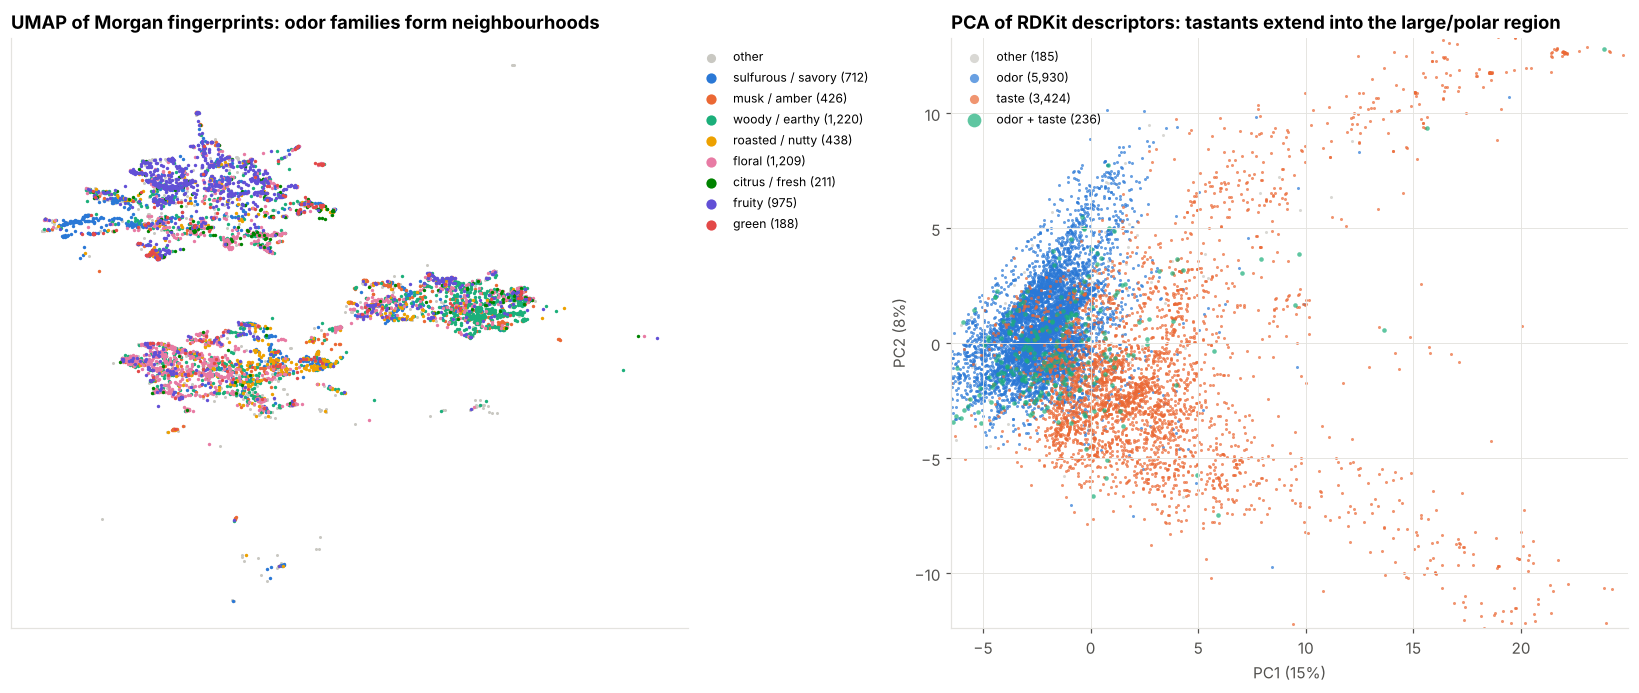

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.4))
fam_colors = dict(zip(FAMILY_ORDER, CAT))

# (a) UMAP of odor molecules coloured by family
ax = axes[0]
sub = emb[emb["family"].notna()]
other = sub[sub["family"] == "other"]
ax.scatter(other["u1"], other["u2"], s=4, color=OTHER, lw=0, label="other")
for fam in FAMILY_ORDER:
    s = sub[sub["family"] == fam]
    ax.scatter(s["u1"], s["u2"], s=5, color=fam_colors[fam], lw=0, label=f"{fam} ({len(s):,})")
ax.set_title("UMAP of Morgan fingerprints: odor families form neighbourhoods")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.legend(markerscale=3, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))

# (b) PCA coloured by task
ax = axes[1]
task_colors = {"odor": CAT[0], "taste": CAT[1], "odor + taste": CAT[2], "other": OTHER}
for t in ["other", "odor", "taste", "odor + taste"]:
    s = emb[emb["task"] == t]
    ax.scatter(s["pc1"], s["pc2"], s=4 if t != "odor + taste" else 9, color=task_colors[t], lw=0,
               alpha=0.7, label=f"{t} ({len(s):,})")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("PCA of RDKit descriptors: tastants extend into the large/polar region")
ax.legend(markerscale=3, fontsize=8)
lo, hi = np.percentile(emb[["pc1", "pc2"]], [0.5, 99.5], axis=0)
ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
plt.tight_layout()
savefig(fig, "p2_02_chemical_space")
plt.show()

**How well do neighbourhoods predict odor?** A UMAP picture can mislead, so here is a number. For each molecule, take its nearest Tanimoto neighbour and ask whether the two share their odor family. This is the "similar structure, similar smell" assumption that every structure-based model relies on, measured on this dataset.

In [30]:
fps = [af.morgan_bitvect(Chem.MolFromSmiles(s)) for s in molecules["smiles"]]
fp_by_key = dict(zip(all_keys, fps))

odor_keys = Yo.index.to_numpy()
odor_fps = [fp_by_key[k] for k in odor_keys]
nn_sim, nn_idx = np.zeros(len(odor_keys)), np.zeros(len(odor_keys), dtype=int)
for i, fp in enumerate(odor_fps):
    sims = np.array(DataStructs.BulkTanimotoSimilarity(fp, odor_fps))
    sims[i] = -1
    nn_idx[i] = sims.argmax()
    nn_sim[i] = sims[nn_idx[i]]

fam_arr = family.reindex(odor_keys).to_numpy()
same_family = fam_arr == fam_arr[nn_idx]
# random-pair baseline: probability two random molecules share a family
p_fam = pd.Series(fam_arr).value_counts(normalize=True)
baseline = float((p_fam ** 2).sum())
bins = [0, 0.3, 0.5, 0.7, 1.01]
nn_tbl = (pd.DataFrame({"nn_sim": nn_sim, "same": same_family})
          .assign(bin=lambda d: pd.cut(d["nn_sim"], bins, right=False,
                                       labels=["<0.3", "0.3-0.5", "0.5-0.7", "≥0.7"]))
          .groupby("bin", observed=True)["same"].agg(["mean", "size"]))
print(f"Nearest neighbour shares odor family: {same_family.mean():.1%}  (random pairs: {baseline:.1%})")
print((nn_tbl.rename(columns={"mean": "share_family", "size": "molecules"})
       .assign(share_family=lambda d: d["share_family"].map("{:.1%}".format))).to_string())

Nearest neighbour shares odor family: 40.4%  (random pairs: 14.4%)
        share_family  molecules
bin                            
<0.3           27.4%         73
0.3-0.5        37.0%        859
0.5-0.7        40.7%       2826
≥0.7           41.5%       2408


## 4. Scaffolds and clusters: choosing the grouping for splits

In drug discovery the default leakage-safe split is the **Bemis–Murcko scaffold split**. For odorants it breaks down: a large share of odor molecules are **acyclic** (esters, aldehydes, alcohols, terpenoid chains), and they all share the *empty* scaffold. One "scaffold" would then hold a fifth to a third of the data.

So the split uses **fingerprint clusters** instead. Sphere-exclusion (leader) clustering on Morgan Tanimoto distance at a threshold of 0.65 (similarity 0.35) puts close analogues and homologous series in the same cluster. Whole clusters are then assigned to train, validation, or test.

In [31]:
def murcko(smi, generic=False):
    m = Chem.MolFromSmiles(smi)
    core = MurckoScaffold.GetScaffoldForMol(m)
    if generic:
        core = MurckoScaffold.MakeScaffoldGeneric(core)
    return Chem.MolToSmiles(core)


molecules["scaffold"] = [murcko(s) for s in molecules["smiles"]]
molecules["generic_scaffold"] = [murcko(s, generic=True) if sc else "" for s, sc in
                                 zip(molecules["smiles"], molecules["scaffold"])]


def leader_clusters(keys, threshold=0.65):
    """Sphere-exclusion clustering: leaders picked by RDKit LeaderPicker, members to nearest leader."""
    fps_ = [fp_by_key[k] for k in keys]
    picker = rdSimDivPickers.LeaderPicker()
    leaders = list(picker.LazyBitVectorPick(fps_, len(fps_), threshold))
    leader_fps = [fps_[i] for i in leaders]
    assign = np.array([int(np.argmax(DataStructs.BulkTanimotoSimilarity(fp, leader_fps))) for fp in fps_])
    return pd.Series(assign, index=keys)


scaf_stats = []
for name, keys in [("odor", Yo.index), ("taste", taste_y.index)]:
    sc = molecules.loc[keys, "scaffold"]
    t0 = time.time()
    cl = leader_clusters(keys.to_numpy())
    molecules.loc[keys, f"cluster_{name}"] = cl
    scaf_stats.append({
        "task": name, "molecules": len(keys), "acyclic (empty scaffold)": f"{(sc == '').mean():.1%}",
        "unique scaffolds": sc.nunique(), "largest scaffold group": f"{sc.value_counts(normalize=True).iloc[0]:.1%}",
        "clusters": cl.nunique(), "largest cluster": f"{cl.value_counts(normalize=True).iloc[0]:.1%}",
        "singleton clusters": int((cl.value_counts() == 1).sum()), "time_s": round(time.time() - t0, 1)})
pd.DataFrame(scaf_stats).set_index("task").T

task,odor,taste
molecules,6166,3660
acyclic (empty scaffold),41.0%,17.2%
unique scaffolds,658,960
largest scaffold group,41.0%,18.1%
clusters,1077,609
largest cluster,4.8%,4.8%
singleton clusters,326,227
time_s,1.0,0.3


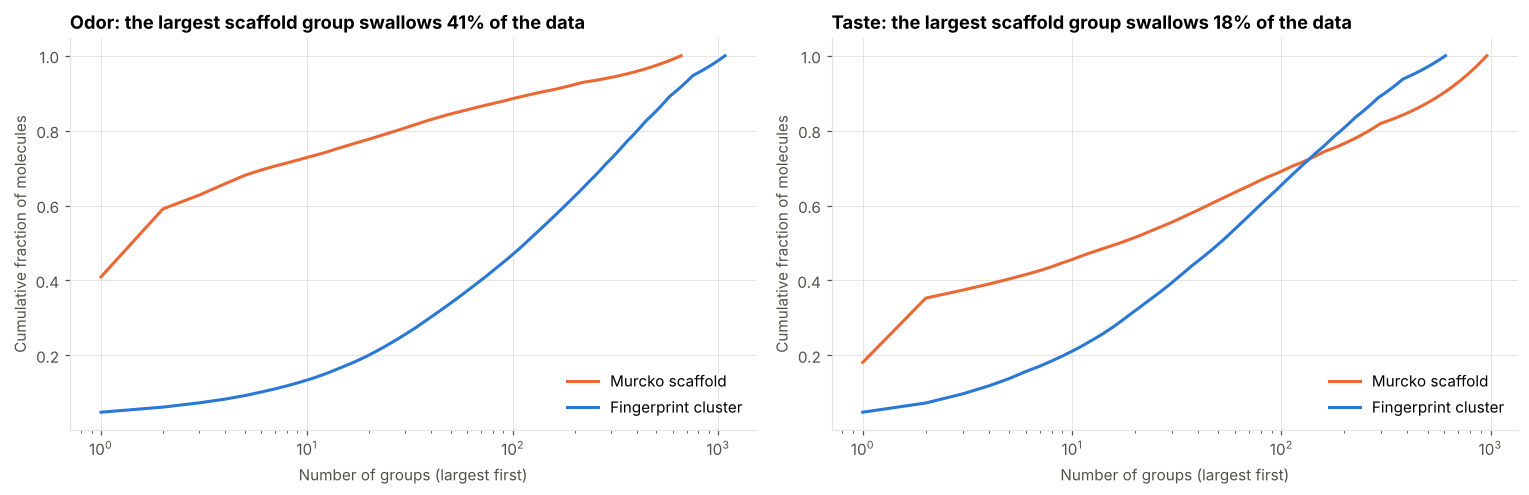

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, (name, keys) in zip(axes, [("odor", Yo.index), ("taste", taste_y.index)]):
    sc_sizes = molecules.loc[keys, "scaffold"].value_counts().to_numpy()
    cl_sizes = molecules.loc[keys, f"cluster_{name}"].value_counts().to_numpy()
    for sizes, lab, col in [(sc_sizes, "Murcko scaffold", CAT[1]), (cl_sizes, "Fingerprint cluster", CAT[0])]:
        frac = np.cumsum(sizes) / sizes.sum()
        ax.plot(np.arange(1, len(sizes) + 1), frac, color=col, lw=2, label=lab)
    ax.set_xscale("log")
    ax.set_xlabel("Number of groups (largest first)")
    ax.set_ylabel("Cumulative fraction of molecules")
    ax.set_title(f"{name.capitalize()}: the largest scaffold group swallows "
                 f"{sc_sizes[0] / sc_sizes.sum():.0%} of the data")
    ax.legend(loc="lower right")
plt.tight_layout()
savefig(fig, "p2_03_scaffold_vs_cluster_groups")
plt.show()

## 5. Building splits and measuring leakage

Three strategies are built for each task, all at 80/10/10 (train/validation/test). Every split is at the **molecule level** (connectivity key), so stereoisomers of the same skeleton can never sit on both sides.

1. **Random:** the common default, and an optimistic baseline.
2. **Scaffold:** whole Murcko scaffolds per partition, largest groups to train (the DeepChem convention).
3. **Cluster (recommended):** whole fingerprint clusters per partition, assigned at random with a greedy balance on size. Because clusters are chemically coherent, some (e.g. aspartame analogues) are almost single-label. So 200 random cluster assignments are tried, and the one with the smallest label-prevalence drift between partitions is kept: a simple stratified group split. Inside the training set, cluster-grouped 5-fold CV ids are also provided for hyperparameter tuning in Part 3.

**Leakage metric.** For each test molecule: its maximum Tanimoto similarity to *any* training molecule. If most test molecules have a near-twin in training, the test score measures memorisation, not generalisation to novel chemistry, which is what a discovery programme actually needs.

In [33]:
def group_split(keys, groups, frac=(0.8, 0.1, 0.1), largest_first=False, seed=RANDOM_SEED):
    """Assign whole groups to train/valid/test so each partition hits its target size."""
    g = pd.Series(groups, index=keys)
    sizes = g.value_counts()
    order = sizes.index.to_numpy() if largest_first else np.random.default_rng(seed).permutation(sizes.index.to_numpy())
    targets = np.array(frac) * len(keys)
    filled = np.zeros(3)
    assign = {}
    for grp in order:
        if largest_first:
            part = 0 if filled[0] + sizes[grp] <= targets[0] else (1 if filled[1] + sizes[grp] <= targets[1] else 2)
        else:
            part = int(np.argmax(targets - filled))          # partition furthest below its target
        assign[grp] = part
        filled[part] += sizes[grp]
    return g.map(assign).map({0: "train", 1: "valid", 2: "test"})


def random_split(keys, frac=(0.8, 0.1, 0.1), seed=RANDOM_SEED):
    perm = np.random.default_rng(seed).permutation(len(keys))
    cut1, cut2 = int(frac[0] * len(keys)), int((frac[0] + frac[1]) * len(keys))
    lab = np.empty(len(keys), dtype=object)
    lab[perm[:cut1]], lab[perm[cut1:cut2]], lab[perm[cut2:]] = "train", "valid", "test"
    return pd.Series(lab, index=keys)


def cv_folds(train_keys, groups, k=5, seed=RANDOM_SEED):
    """Cluster-grouped k-fold ids for the training partition."""
    from sklearn.model_selection import GroupKFold
    gkf = GroupKFold(n_splits=k, shuffle=True, random_state=seed)
    fold = pd.Series(-1, index=train_keys)
    for f, (_, va) in enumerate(gkf.split(train_keys, groups=groups)):
        fold.iloc[va] = f
    return fold


def stratified_group_split(keys, groups, Y, n_trials=200):
    """Best of n random group splits, scored by label-prevalence drift (prevalence-weighted)."""
    Yv = Y.loc[keys].to_numpy(dtype=float)
    w = Yv.mean(0)
    best, best_score = None, np.inf
    for seed in range(n_trials):
        sp = group_split(keys, groups, seed=seed).to_numpy()
        prev = {p: Yv[sp == p].mean(0) for p in ("train", "valid", "test")}
        score = float((w * (np.abs(prev["valid"] - prev["train"]) + np.abs(prev["test"] - prev["train"]))).sum() / w.sum())
        if score < best_score:
            best, best_score = sp, score
    return pd.Series(best, index=keys), best_score


def max_sim_to_train(split):
    train_fps = [fp_by_key[k] for k in split.index[split == "train"]]
    test_keys = split.index[split == "test"]
    return np.array([max(DataStructs.BulkTanimotoSimilarity(fp_by_key[k], train_fps)) for k in test_keys])


splits, leakage = {}, []
for name, Y in [("odor", Yo), ("taste", taste_y[TASTE_LABELS])]:
    keys = Y.index.to_numpy()
    sp = pd.DataFrame(index=keys)
    sp["random"] = random_split(keys)
    sp["scaffold"] = group_split(keys, molecules.loc[keys, "scaffold"].to_numpy(), largest_first=True)
    sp["cluster"], drift_score = stratified_group_split(keys, molecules.loc[keys, f"cluster_{name}"].to_numpy(), Y)
    print(f"{name}: best cluster split has weighted prevalence drift {drift_score:.4f}")
    sp["cluster_id"] = molecules.loc[keys, f"cluster_{name}"].astype(int).to_numpy()
    tr = sp.index[sp["cluster"] == "train"]
    sp["cv_fold"] = -1
    sp.loc[tr, "cv_fold"] = cv_folds(tr.to_numpy(), sp.loc[tr, "cluster_id"].to_numpy()).to_numpy()
    splits[name] = sp
    for strat in ["random", "scaffold", "cluster"]:
        ms = max_sim_to_train(sp[strat])
        test_keys = sp.index[sp[strat] == "test"]
        leakage.append({"task": name, "split": strat, "max_sim": ms,
                        "acyclic_test": (molecules.loc[test_keys, "scaffold"] == "").mean()})
    sp.to_csv(SPLIT_DIR / f"{name}_splits.csv")

summary = pd.DataFrame([{"task": d["task"], "split": d["split"], "median": np.median(d["max_sim"]),
                         "test with near-twin in train (≥0.7)": (d["max_sim"] >= 0.7).mean(),
                         "test novel (<0.4)": (d["max_sim"] < 0.4).mean(),
                         "acyclic molecules in test": d["acyclic_test"]} for d in leakage])
print(summary.set_index(["task", "split"]).style.format("{:.1%}", subset=summary.columns[3:])
      .format("{:.2f}", subset=["median"]).to_string() if False else
      summary.assign(**{c: summary[c].map("{:.1%}".format) for c in summary.columns[3:]})
             .assign(median=summary["median"].round(2)).to_string(index=False))
for name, sp in splits.items():
    print(f"\n{name}: partition sizes", sp["cluster"].value_counts().to_dict(),
          "| CV folds", sp.loc[sp['cv_fold'] >= 0, 'cv_fold'].value_counts().sort_index().to_dict())

odor: best cluster split has weighted prevalence drift 0.0229


taste: best cluster split has weighted prevalence drift 0.0411


 task    split  median test with near-twin in train (≥0.7) test novel (<0.4) acyclic molecules in test
 odor   random    0.65                               36.6%              8.9%                     39.5%
 odor scaffold    0.37                                7.1%             56.1%                      0.0%
 odor  cluster    0.55                               16.6%             15.3%                     30.4%
taste   random    0.72                               54.6%             10.7%                     19.1%
taste scaffold    0.52                               26.0%             32.8%                      0.0%
taste  cluster    0.52                               12.5%             19.7%                      9.7%

odor: partition sizes {'train': 4935, 'test': 616, 'valid': 615} | CV folds {0: 868, 1: 977, 2: 1347, 3: 715, 4: 1028}

taste: partition sizes {'train': 2942, 'test': 360, 'valid': 358} | CV folds {0: 484, 1: 652, 2: 693, 3: 546, 4: 567}


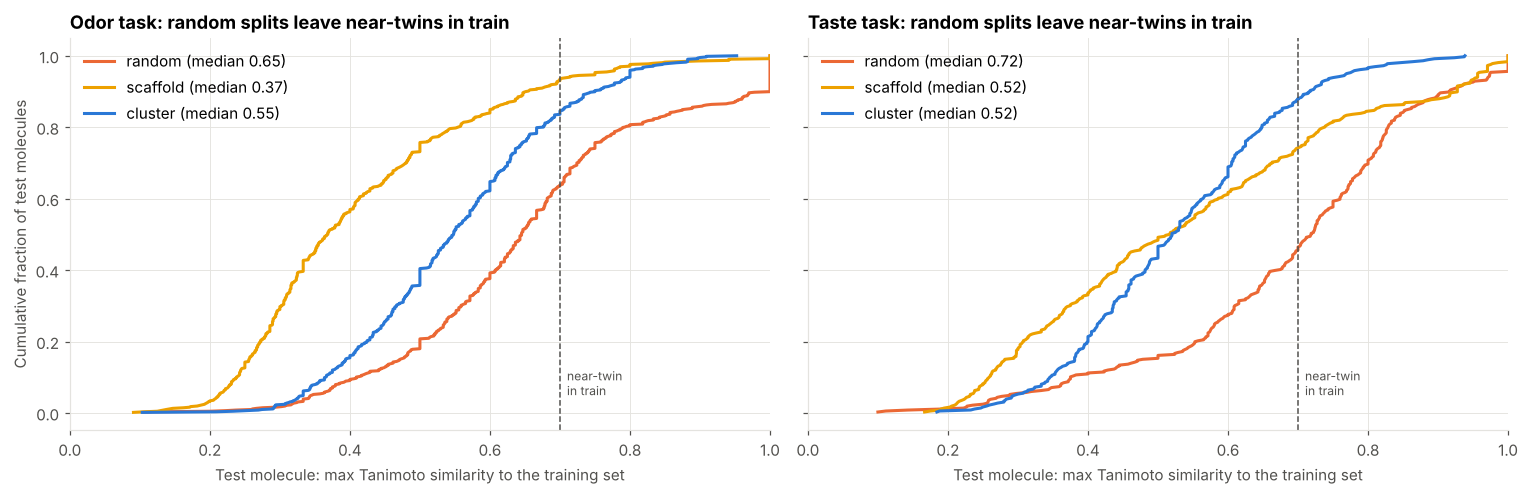

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
split_colors = {"random": CAT[1], "scaffold": CAT[3], "cluster": CAT[0]}
for ax, name in zip(axes, ["odor", "taste"]):
    for d in [x for x in leakage if x["task"] == name]:
        ms = np.sort(d["max_sim"])
        ax.plot(ms, np.arange(1, len(ms) + 1) / len(ms), color=split_colors[d["split"]], lw=2,
                label=f"{d['split']} (median {np.median(ms):.2f})")
    ax.axvline(0.7, color=INK_2, lw=1, ls="--")
    ax.text(0.71, 0.05, "near-twin\nin train", color=INK_2, fontsize=8)
    ax.set_xlabel("Test molecule: max Tanimoto similarity to the training set")
    ax.set_title(f"{name.capitalize()} task: random splits leave near-twins in train")
    ax.legend(loc="upper left")
    ax.set_xlim(0, 1)
axes[0].set_ylabel("Cumulative fraction of test molecules")
plt.tight_layout()
savefig(fig, "p2_04_split_leakage")
plt.show()

**Reading the leakage results.**
* **Random** leaves a large share of test molecules with a near-twin in training, so its scores are optimistic. Some even have an *identical* fingerprint in training (positional isomers and homologues that radius-2 Morgan cannot tell apart).
* **Scaffold** looks the most "novel", but for odor it is distorted. The 41% acyclic molecules form one giant group that lands entirely in training, so the test set holds almost no acyclic odorants (see the last column). It measures a different chemical population, not harder generalisation.
* **Cluster** controls leakage while keeping test chemistry representative. It is the headline split for Part 3, and random-split scores are reported alongside, so results can be compared with the literature.

### 5.1 Label balance across partitions

A grouped split must not starve the test set of rare labels. The check: positive counts per label in each partition, and the labels with fewer than 5 test positives. Those labels get no per-label test metric in Part 3; they are reported via cross-validation only.

In [35]:
for name, Y in [("odor", Yo), ("taste", taste_y[TASTE_LABELS])]:
    sp = splits[name]["cluster"]
    pos = pd.DataFrame({p: Y.loc[sp.index[sp == p]].sum() for p in ["train", "valid", "test"]})
    prev = pd.DataFrame({p: Y.loc[sp.index[sp == p]].mean() for p in ["train", "test"]})
    drift = (prev["test"] - prev["train"]).abs()
    print(f"{name}: labels with <5 test positives: {(pos['test'] < 5).sum()} of {len(pos)} | "
          f"median |prevalence drift| train vs test: {drift.median():.3%}")
    if name == "taste":
        print(pos.sort_values("train", ascending=False).to_string())

odor: labels with <5 test positives: 17 of 138 | median |prevalence drift| train vs test: 0.509%
taste: labels with <5 test positives: 5 of 14 | median |prevalence drift| train vs test: 0.830%
               train  valid  test
bitter          1329    176   164
sweet           1072    127   136
non-sweet        365     22    46
umami            201     39     6
tasteless        181     20    47
multitaste       135     16    27
miscellaneous     96      9     8
sour              80     11     5
non-bitter        57      2     7
salty             32      1     1
pungent           26      2     2
astringent        25      4     0
cooling           10      0     2
kokumi             7      3     0


## 6. Chirality: what achiral fingerprints cannot see

The database holds every stereo variant. Two numbers frame the problem for Part 4:

1. how many labelled skeletons exist as **two or more stereo-defined variants**, so that an achiral model gives them *identical* features;
2. a check that the chirality-aware fingerprint actually separates enantiomers: carvone and limonene, then all enantiomer pairs in the database.

In [36]:
sv = stereo_variants.copy()
sv["mol"] = [Chem.MolFromSmiles(s) for s in sv["smiles_isomeric"]]
sv = sv[sv["mol"].notna()]


def same_fp(m1, m2, chiral):
    return af.morgan_bitvect(m1, chiral) == af.morgan_bitvect(m2, chiral)


rows = []
for name, ck in [("carvone", "ULDHMXUKGWMISQ"), ("limonene", "XMGQYMWWDOXHJM")]:
    g = sv[(sv["conn_key"] == ck) & (sv["stereo_defined"] == 1)]
    if len(g) >= 2:
        a, b = g.iloc[0], g.iloc[1]
        rows.append({"molecule": name, "isomer A": a["smiles_isomeric"], "isomer B": b["smiles_isomeric"],
                     "identical FP (achiral)": same_fp(a["mol"], b["mol"], False),
                     "identical FP (chiral)": same_fp(a["mol"], b["mol"], True)})
display(pd.DataFrame(rows))

# all enantiomer pairs in the database
def mirror(smi):
    m = Chem.MolFromSmiles(smi.replace("@@", "\x00").replace("@", "@@").replace("\x00", "@"))
    return Chem.MolToSmiles(m) if m else None


defined = sv[sv["stereo_defined"] == 1]
canon = set(defined["smiles_isomeric"])
enant = [(s, mirror(s)) for s in defined["smiles_isomeric"] if mirror(s) in canon and mirror(s) != s]
enant = {tuple(sorted(p)) for p in enant}
n_sep = sum(not same_fp(Chem.MolFromSmiles(a), Chem.MolFromSmiles(b), True) for a, b in enant)
multi = defined.groupby("conn_key").size()
labelled = set(Yo.index) | set(taste_y.index)
print(f"Labelled skeletons with ≥2 stereo-defined variants: {sum(k in labelled for k in multi[multi >= 2].index):,}")
print(f"Enantiomer pairs in the database: {len(enant):,}")
print(f"  separated by achiral Morgan: 0 (by construction) | separated by chiral Morgan: {n_sep:,}")

,molecule,isomer A,isomer B,identical FP (achiral),identical FP (chiral)
0,carvone,C=C(C)[C@@H]1CC=C(C)C(=O)C1,C=C(C)[C@H]1CC=C(C)C(=O)C1,True,False
1,limonene,C=C(C)[C@H]1CC=C(C)CC1,C=C(C)[C@@H]1CC=C(C)CC1,True,False


Labelled skeletons with ≥2 stereo-defined variants: 317
Enantiomer pairs in the database: 111
  separated by achiral Morgan: 0 (by construction) | separated by chiral Morgan: 104


## 7. Part 2 summary

**Artifacts written** (all consumed by Parts 3 and 4):

| Path | Content |
|---|---|
| `src/aroma_features.py` | the featurizer: Morgan counts (achiral and chiral), MACCS, RDKit 2D, 30 F&F functional groups |
| `data/features/features_all.npz` | all feature blocks for every molecule, keyed by connectivity key |
| `data/features/features_meta.json` | descriptor columns, pruned list, imputation medians, SMARTS |
| `data/features/embedding_2d.csv` | PCA and UMAP coordinates for plotting |
| `data/splits/{odor,taste}_splits.csv` | random / scaffold / cluster partitions, cluster ids, 5-fold CV ids |

**Findings to carry into modelling**

1. **The features carry chemistry.** Functional-group enrichments reproduce textbook structure–odor rules (esters → fruity, thiols → sulfurous, pyrazines → roasted/nutty, macrocycles → musk) before any ML.
2. **"Similar structure, similar smell" holds only partly.** Nearest neighbours share an odor family well above chance, but far from always. That gap is the activity-cliff problem perfumers know well, and it caps what any structure-only model can achieve.
3. **Scaffold splits don't work for odorants.** The empty (acyclic) scaffold holds a large fraction of the odor set. Fingerprint clusters give balanced, leakage-controlled groups.
4. **Random splits overstate performance.** Many random-split test molecules have a near-twin in training. The cluster split is the honest benchmark, and all headline numbers in Part 3 use it.
5. **Chirality is a known blind spot.** Achiral fingerprints cannot separate enantiomers, and the chiral variant does, which sets up the enantiomer case studies in Part 4.

**Next: Part 3.** Models for the aroma multi-label task (138 notes) and the taste task: baselines (prevalence, nearest-neighbour), random forest / LightGBM on each feature block, a multi-task neural net, cluster-grouped CV, per-label AUROC/AUPRC with bootstrap confidence intervals, calibration, and the applicability domain. The published OpenPOM ensemble (~0.89 AUROC, random 5-fold CV) is the external reference point.

---

# Part 3: Predictive Models for Aroma and Taste
### AI-Driven Discovery of Novel Aroma and Taste Molecules

**Inputs:** features and splits from Part 2. **Outputs:** benchmark tables, figures, test-set predictions, and the trained final models in `models/`, used by Part 4.

| Task | Type | Data | Headline split |
|---|---|---|---|
| **Aroma** | multi-label, 138 odor notes | 6,166 molecules, 9 merged sources | fingerprint-cluster split |
| **Taste** | 5 binary classes (sweet, bitter, umami, sour, tasteless) | 3,660 molecules (ChemTastesDB + SweetenersDB) | fingerprint-cluster split |
| **Sweetness potency** | regression, log relative sweetness (sucrose = 0) | SweetenersDB, 316 sweeteners | cluster-grouped 5-fold CV |

**Evaluation protocol** (fixed before looking at test results):
* Models are compared on the **cluster-split test set**, which no model or hyperparameter choice has touched. Random-split scores are also reported, for comparison with the literature only.
* **Metrics:** macro AUROC and macro **AUPRC** over labels with at least 5 test positives, plus label-ranking average precision ("are a molecule's true notes ranked on top?"). AUPRC is the stricter metric for rare notes; its chance level equals the label's prevalence, not 0.5.
* **Uncertainty:** 95% bootstrap confidence intervals over test molecules.
* **Honesty checks:** a trivial prevalence baseline and a nearest-neighbour baseline. A model that cannot beat "look up the most similar known molecule" adds little.

## 0. Setup

In [37]:
import json
import sqlite3
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from rdkit import Chem, DataStructs, RDLogger
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, label_ranking_average_precision_score,
                             mean_squared_error, r2_score, roc_auc_score)
from sklearn.model_selection import GroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.preprocessing import QuantileTransformer, StandardScaler

import src.aroma_features as af

RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore")
RANDOM_SEED = 42
N_JOBS = 4                      # set to your core count
MIN_TEST_POS = 5                # labels need >= this many test positives to get a test metric
N_BOOT = 200

PROJECT_ROOT = Path.cwd()
FEAT_DIR, SPLIT_DIR = PROJECT_ROOT / "data" / "features", PROJECT_ROOT / "data" / "splits"
MODEL_DIR, FIG_DIR = PROJECT_ROOT / "models", PROJECT_ROOT / "figures"
RESULT_DIR = PROJECT_ROOT / "results"
for p in (MODEL_DIR, FIG_DIR, RESULT_DIR):
    p.mkdir(parents=True, exist_ok=True)

CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, GRID, MUTED = "#0b0b0b", "#52514e", "#e4e3df", "#9b9a94"
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK_2, "ytick.color": INK_2,
    "legend.frameon": False, "figure.facecolor": "white"})
savefig = lambda fig, name: fig.savefig(FIG_DIR / f"{name}.png")

# ---------------- features ----------------
F = np.load(FEAT_DIR / "features_all.npz", allow_pickle=True)
meta = json.loads((FEAT_DIR / "features_meta.json").read_text())
ROW = pd.Series(np.arange(len(F["conn_key"])), index=F["conn_key"])
PRUNED = [meta["rdkit2d_columns"].index(c) for c in meta["rdkit2d_pruned_columns"]]
BLOCKS = {"morgan": F["morgan"].astype(np.float32), "maccs": F["maccs"].astype(np.float32),
          "rdkit2d": F["rdkit2d"][:, PRUNED].astype(np.float32), "ffgroups": F["ffgroups"].astype(np.float32)}


def X_of(keys, block="morgan+rdkit2d"):
    rows = ROW[keys].to_numpy()
    return np.hstack([BLOCKS[b][rows] for b in block.split("+")])


# ---------------- labels and splits ----------------
odor_Y = pd.read_csv(PROJECT_ROOT / "data/processed/odor_multilabel.csv.gz", index_col=0).drop(columns="smiles")
taste_raw = pd.read_csv(PROJECT_ROOT / "data/processed/taste_multilabel.csv.gz", index_col=0)
odor_sp = pd.read_csv(SPLIT_DIR / "odor_splits.csv", index_col=0)
taste_sp = pd.read_csv(SPLIT_DIR / "taste_splits.csv", index_col=0)
with sqlite3.connect(PROJECT_ROOT / "data/processed/aroma_taste.sqlite") as con:
    molecules = pd.read_sql("SELECT conn_key, smiles, name FROM molecules", con).set_index("conn_key")
FP = {k: af.morgan_bitvect(Chem.MolFromSmiles(s)) for k, s in molecules["smiles"].items()}

ODOR_LABELS = list(odor_Y.columns)
print(f"Feature blocks: " + ", ".join(f"{k} {v.shape[1]}" for k, v in BLOCKS.items()))
print(f"Odor: {odor_Y.shape} | splits: {odor_sp['cluster'].value_counts().to_dict()}")

Feature blocks: morgan 2048, maccs 167, rdkit2d 160, ffgroups 30
Odor: (6166, 138) | splits: {'train': 4935, 'test': 616, 'valid': 615}


## 1. Shared evaluation utilities

Every model returns a probability matrix (molecules × labels), so a single set of evaluation code scores all of them.

In [38]:
def eval_labels(Y_test, min_pos=MIN_TEST_POS):
    pos = Y_test.sum(0)
    return np.where((pos >= min_pos) & (pos < len(Y_test)))[0]


def multilabel_scores(Y, P, cols):
    au = [roc_auc_score(Y[:, j], P[:, j]) for j in cols]
    ap = [average_precision_score(Y[:, j], P[:, j]) for j in cols]
    keep = Y.sum(1) > 0
    return {"macro_auroc": float(np.mean(au)), "macro_auprc": float(np.mean(ap)),
            "lrap": float(label_ranking_average_precision_score(Y[keep], P[keep])),
            "per_label_auroc": au, "per_label_auprc": ap}


def bootstrap_ci(Y, P, cols, n=N_BOOT, seed=RANDOM_SEED):
    """95% CI by resampling test molecules. Uses the 'basic' (reverse-percentile) interval because
    average precision is biased upward under resampling: a duplicated, highly ranked positive raises AP.
    The plain percentile interval would then sit almost entirely above the point estimate."""
    rng = np.random.default_rng(seed)
    au0 = np.mean([roc_auc_score(Y[:, j], P[:, j]) for j in cols])
    ap0 = np.mean([average_precision_score(Y[:, j], P[:, j]) for j in cols])
    au, ap = [], []
    for _ in range(n):
        b = rng.integers(0, len(Y), len(Y))
        Yb, Pb = Y[b], P[b]
        ok = [j for j in cols if 0 < Yb[:, j].sum() < len(b)]
        au.append(np.mean([roc_auc_score(Yb[:, j], Pb[:, j]) for j in ok]))
        ap.append(np.mean([average_precision_score(Yb[:, j], Pb[:, j]) for j in ok]))
    basic = lambda est, boot: 2 * est - np.percentile(boot, [97.5, 2.5])
    return basic(au0, au), basic(ap0, ap)


def rf_proba(model, X, n_labels):
    """Multi-output RandomForest -> (n, L) positive-class probabilities (handles all-negative labels)."""
    out = np.zeros((len(X), n_labels), dtype=np.float32)
    for j, p in enumerate(model.predict_proba(X)):
        if p.shape[1] == 2:
            out[:, j] = p[:, 1]
    return out


def knn_proba(train_keys, Y_train, query_keys, k=10):
    """Similarity-weighted k-nearest-neighbour vote on Morgan/Tanimoto."""
    train_fps = [FP[t] for t in train_keys]
    P = np.zeros((len(query_keys), Y_train.shape[1]), dtype=np.float32)
    for i, q in enumerate(query_keys):
        s = np.asarray(DataStructs.BulkTanimotoSimilarity(FP[q], train_fps))
        top = np.argpartition(-s, k)[:k]
        w = s[top] + 1e-6
        P[i] = (w @ Y_train[top]) / w.sum()
    return P


def max_sim_to(train_keys, query_keys):
    train_fps = [FP[t] for t in train_keys]
    return np.array([max(DataStructs.BulkTanimotoSimilarity(FP[q], train_fps)) for q in query_keys])


RESULTS = []          # one row per (task, split, model, features)


def record(task, split, model, features, Y, P, cols, ci=True):
    s = multilabel_scores(Y, P, cols)
    row = {"task": task, "split": split, "model": model, "features": features,
           "macro_AUROC": s["macro_auroc"], "macro_AUPRC": s["macro_auprc"], "LRAP": s["lrap"]}
    if ci:
        (a_lo, a_hi), (p_lo, p_hi) = bootstrap_ci(Y, P, cols)
        row.update({"AUROC_95CI": f"[{a_lo:.3f}, {a_hi:.3f}]", "AUPRC_95CI": f"[{p_lo:.3f}, {p_hi:.3f}]"})
    RESULTS.append(row)
    return s

## 2. Aroma: 138-note multi-label prediction

### 2.1 Train, validation, and test partitions (cluster split)

In [39]:
tr_k = odor_sp.index[odor_sp["cluster"] == "train"].to_numpy()
va_k = odor_sp.index[odor_sp["cluster"] == "valid"].to_numpy()
te_k = odor_sp.index[odor_sp["cluster"] == "test"].to_numpy()
Ytr, Yva, Yte = (odor_Y.loc[k].to_numpy(np.int8) for k in (tr_k, va_k, te_k))
cols_te = eval_labels(Yte)
print(f"train {len(tr_k):,} | valid {len(va_k):,} | test {len(te_k):,}")
print(f"labels with >= {MIN_TEST_POS} test positives (scored): {len(cols_te)} of {len(ODOR_LABELS)}")
print(f"mean label prevalence among scored labels = chance-level AUPRC: {Yte[:, cols_te].mean(0).mean():.3f}")

train 4,935 | valid 615 | test 616
labels with >= 5 test positives (scored): 121 of 138
mean label prevalence among scored labels = chance-level AUPRC: 0.042


### 2.2 Baselines

* **Prevalence:** every molecule gets the training-set frequency of each note. AUROC = 0.5 by construction; it gives the chance AUPRC.
* **Tanimoto k-NN:** k is chosen by cluster-grouped 5-fold CV on the training partition only.

In [40]:
P_prev = np.tile(Ytr.mean(0), (len(te_k), 1))
record("aroma", "cluster", "prevalence baseline", "-", Yte, P_prev, cols_te, ci=False)

folds = odor_sp.loc[tr_k, "cv_fold"].to_numpy()
knn_cv = {}
for k in (5, 10, 20, 40):
    sc = []
    for f in range(5):
        a, b = tr_k[folds != f], tr_k[folds == f]
        Ya, Yb = odor_Y.loc[a].to_numpy(np.int8), odor_Y.loc[b].to_numpy(np.int8)
        P = knn_proba(a, Ya, b, k=k)
        c = eval_labels(Yb)
        sc.append(multilabel_scores(Yb, P, c)["macro_auprc"])
    knn_cv[k] = float(np.mean(sc))
best_k = max(knn_cv, key=knn_cv.get)
print("k-NN macro AUPRC by k (grouped CV on train):", {k: round(v, 3) for k, v in knn_cv.items()}, "-> k =", best_k)

P_knn = knn_proba(tr_k, Ytr, te_k, k=best_k)
record("aroma", "cluster", f"Tanimoto {best_k}-NN", "morgan", Yte, P_knn, cols_te)
pd.DataFrame(RESULTS)

k-NN macro AUPRC by k (grouped CV on train): {5: 0.177, 10: 0.197, 20: 0.209, 40: 0.216} -> k = 40


,task,split,model,features,macro_AUROC,macro_AUPRC,LRAP,AUROC_95CI,AUPRC_95CI
0,aroma,cluster,prevalence baseline,-,0.500000,0.042127,0.312682,NaN,NaN
1,aroma,cluster,Tanimoto 40-NN,morgan,0.770306,0.218854,0.447481,"[0.753, 0.784]","[0.179, 0.220]"


### 2.3 Which feature block works best?

A multi-output random forest is trained on each feature block, scored on the **validation** partition. The test set is not touched here. Random forest is used for the comparison because it needs no tuning to be competitive and trains one model for all 138 labels at once.

In [41]:
def fit_rf(keys, Y, block, n_estimators=300, seed=RANDOM_SEED):
    rf = RandomForestClassifier(n_estimators=n_estimators, max_features="sqrt", min_samples_leaf=2,
                                n_jobs=N_JOBS, random_state=seed, class_weight="balanced_subsample")
    rf.fit(X_of(keys, block), Y)
    return rf


cols_va = eval_labels(Yva)
block_rows = []
for block in ["ffgroups", "maccs", "rdkit2d", "morgan", "morgan+rdkit2d", "morgan+maccs+rdkit2d+ffgroups"]:
    t0 = time.time()
    rf = fit_rf(tr_k, Ytr, block, n_estimators=200)
    P = rf_proba(rf, X_of(va_k, block), Yva.shape[1])
    s = multilabel_scores(Yva, P, cols_va)
    block_rows.append({"features": block, "n_features": X_of(tr_k[:2], block).shape[1],
                       "valid macro AUROC": s["macro_auroc"], "valid macro AUPRC": s["macro_auprc"],
                       "valid LRAP": s["lrap"], "fit_s": round(time.time() - t0)})
    print(f"{block:32s} AUROC {s['macro_auroc']:.3f}  AUPRC {s['macro_auprc']:.3f}  ({time.time() - t0:.0f}s)")
block_df = pd.DataFrame(block_rows).set_index("features")
# Within 0.005 AUPRC of the best (well inside validation noise), prefer a block that contains Morgan bits:
# Part 4 decodes Morgan bits back to substructures, which descriptors alone cannot do.
best_ap = block_df["valid macro AUPRC"].max()
near = block_df[block_df["valid macro AUPRC"] >= best_ap - 0.005]
with_morgan = [b for b in near.index if b.startswith("morgan")]
BEST_BLOCK = with_morgan[0] if with_morgan else near["valid macro AUPRC"].idxmax()
print(f"\nBest block by AUPRC: {block_df['valid macro AUPRC'].idxmax()} ({best_ap:.3f}); "
      f"selected: {BEST_BLOCK} ({block_df.loc[BEST_BLOCK, 'valid macro AUPRC']:.3f}), "
      "the best block that keeps interpretable Morgan bits")
block_df.round(3)

ffgroups                         AUROC 0.713  AUPRC 0.141  (65s)


maccs                            AUROC 0.785  AUPRC 0.208  (64s)


rdkit2d                          AUROC 0.818  AUPRC 0.287  (63s)


morgan                           AUROC 0.782  AUPRC 0.211  (63s)


morgan+rdkit2d                   AUROC 0.820  AUPRC 0.287  (65s)


morgan+maccs+rdkit2d+ffgroups    AUROC 0.821  AUPRC 0.285  (62s)

Best block by AUPRC: rdkit2d (0.287); selected: morgan+rdkit2d (0.287), the best block that keeps interpretable Morgan bits


,n_features,valid macro AUROC,valid macro AUPRC,valid LRAP,fit_s
features,,,,,
ffgroups,30,0.713,0.141,0.324,65
maccs,167,0.785,0.208,0.419,64
rdkit2d,160,0.818,0.287,0.474,63
morgan,2048,0.782,0.211,0.401,63
morgan+rdkit2d,2208,0.820,0.287,0.469,65
morgan+maccs+rdkit2d+ffgroups,2405,0.821,0.285,0.473,62


### 2.4 Models

Three model families on the selected feature block:

* **Random forest** (multi-output): strong, almost tuning-free baseline.
* **LightGBM**, one binary model per label (one-vs-rest), with `scale_pos_weight` for imbalance. Hyperparameters are tuned on the validation partition over a small, sensible grid, using a subset of labels spanning common and rare notes, so tuning does not cost hours.
* **Multi-task neural net** (shared hidden layers, 138 sigmoid outputs). Sharing representation across notes is the idea behind the Principal Odor Map, and it is what a GNN does in a more expressive way.

In [42]:
TUNE_LABELS = [ODOR_LABELS.index(l) for l in
               [l for l in ["fruity", "green", "floral", "woody", "sulfurous", "musk", "vanilla", "roasted",
                            "coconut", "minty", "mint", "citrus", "waxy"] if l in ODOR_LABELS]][:12]
print("Tuning on labels:", [ODOR_LABELS[j] for j in TUNE_LABELS])


def lgbm_ovr(train_keys, Y, query_keys, params, block, label_idx=None, verbose=False):
    Xtr, Xq = X_of(train_keys, block), X_of(query_keys, block)
    label_idx = range(Y.shape[1]) if label_idx is None else label_idx
    P = np.zeros((len(query_keys), Y.shape[1]), dtype=np.float32)
    for j in label_idx:
        y = Y[:, j]
        if y.sum() < 3:
            P[:, j] = y.mean()
            continue
        spw = max(1.0, (len(y) - y.sum()) / max(y.sum(), 1))
        m = lgb.LGBMClassifier(random_state=RANDOM_SEED, n_jobs=N_JOBS, verbose=-1,
                               scale_pos_weight=spw, **params)
        m.fit(Xtr, y)
        P[:, j] = m.predict_proba(Xq)[:, 1]
    return P


grid = [
    {"n_estimators": 300, "learning_rate": 0.05, "num_leaves": 31, "colsample_bytree": 0.3,
     "subsample": 0.8, "subsample_freq": 1, "min_child_samples": 10},
    {"n_estimators": 600, "learning_rate": 0.03, "num_leaves": 15, "colsample_bytree": 0.2,
     "subsample": 0.8, "subsample_freq": 1, "min_child_samples": 20, "reg_lambda": 1.0},
    {"n_estimators": 300, "learning_rate": 0.1, "num_leaves": 63, "colsample_bytree": 0.4,
     "subsample": 0.7, "subsample_freq": 1, "min_child_samples": 5},
]
tune = []
for i, params in enumerate(grid):
    t0 = time.time()
    P = lgbm_ovr(tr_k, Ytr, va_k, params, BEST_BLOCK, label_idx=TUNE_LABELS)
    ap = float(np.mean([average_precision_score(Yva[:, j], P[:, j]) for j in TUNE_LABELS if Yva[:, j].sum() >= 3]))
    tune.append({"config": i, **{k: v for k, v in params.items() if k in
                                 ("n_estimators", "learning_rate", "num_leaves", "colsample_bytree")},
                 "valid AUPRC (tuning labels)": round(ap, 4), "s": round(time.time() - t0)})
    print(f"config {i}: AUPRC {ap:.4f}  ({time.time() - t0:.0f}s)")
LGB_PARAMS = grid[int(pd.DataFrame(tune)["valid AUPRC (tuning labels)"].idxmax())]
print("Selected LightGBM params:", LGB_PARAMS)
pd.DataFrame(tune)

Tuning on labels: ['fruity', 'green', 'floral', 'woody', 'sulfurous', 'musk', 'vanilla', 'roasted', 'coconut', 'mint', 'citrus', 'waxy']


config 0: AUPRC 0.5254  (16s)


config 1: AUPRC 0.5256  (14s)


config 2: AUPRC 0.5151  (26s)
Selected LightGBM params: {'n_estimators': 600, 'learning_rate': 0.03, 'num_leaves': 15, 'colsample_bytree': 0.2, 'subsample': 0.8, 'subsample_freq': 1, 'min_child_samples': 20, 'reg_lambda': 1.0}


,config,n_estimators,learning_rate,num_leaves,colsample_bytree,valid AUPRC (tuning labels),s
0,0,300,0.05,31,0.3,0.5254,16
1,1,600,0.03,15,0.2,0.5256,14
2,2,300,0.10,63,0.4,0.5151,26


In [43]:
class MultiTaskNet:
    """Shared-trunk MLP with one sigmoid output per odor note (scikit-learn only, no deep-learning dependency).

    Three details decide whether this learns at all:
    * Target dtype. The label matrix is stored as int8 to save memory; MLPClassifier trained on int8
      multilabel targets stays at chance, so targets are cast to int64.
    * Input scaling. Some RDKit descriptors (Ipc, for example) reach 1e9, so plain standardisation leaves
      a few columns dominating. Morgan counts get log1p; descriptors get a rank-based (quantile) transform.
    * No early stopping. scikit-learn's early stopping monitors exact-match accuracy over all 138 labels,
      which is ~0 for every epoch, so it stops on noise. A fixed epoch budget plus strong L2 is used instead.
    """

    def __init__(self, hidden=(512,), alpha=10.0, max_iter=40, n_morgan=af.N_BITS, seed=RANDOM_SEED):
        self.n_morgan = n_morgan
        self.qt = QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=seed)
        self.scaler = StandardScaler()
        self.net = MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, max_iter=max_iter, batch_size=128,
                                 learning_rate_init=1e-3, early_stopping=False, random_state=seed)

    def _prep(self, X, fit=False):
        m, d = np.log1p(X[:, :self.n_morgan]), X[:, self.n_morgan:]
        if d.shape[1]:
            d = self.qt.fit_transform(d) if fit else self.qt.transform(d)
        Z = np.hstack([m, d])
        return self.scaler.fit_transform(Z) if fit else self.scaler.transform(Z)

    def fit(self, X, Y):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            # int8 targets silently break MLPClassifier's multilabel loss (AUROC ~0.5), so cast to int64
            self.net.fit(self._prep(X, fit=True), np.asarray(Y, dtype=np.int64))
        return self

    def predict_proba(self, X):
        return self.net.predict_proba(self._prep(X))


assert BEST_BLOCK.startswith("morgan"), "MultiTaskNet expects Morgan counts in the first columns"
# L2 strength tuned on the validation partition (the test set is untouched)
nn_tune = []
for alpha in (1.0, 3.0, 10.0, 30.0):
    t0 = time.time()
    P = MultiTaskNet(alpha=alpha).fit(X_of(tr_k, BEST_BLOCK), Ytr).predict_proba(X_of(va_k, BEST_BLOCK))
    s = multilabel_scores(Yva, P, cols_va)
    nn_tune.append({"alpha": alpha, "valid macro AUROC": s["macro_auroc"], "valid macro AUPRC": s["macro_auprc"]})
    print(f"NN alpha={alpha:5.1f}: valid AUROC {s['macro_auroc']:.3f}  AUPRC {s['macro_auprc']:.3f}  "
          f"({time.time() - t0:.0f}s)")
NN_ALPHA = pd.DataFrame(nn_tune).set_index("alpha")["valid macro AUPRC"].idxmax()
print(f"Selected NN L2 alpha: {NN_ALPHA}")

models = {}
t0 = time.time()
models["Random forest"] = fit_rf(tr_k, Ytr, BEST_BLOCK, n_estimators=500)
P_rf = rf_proba(models["Random forest"], X_of(te_k, BEST_BLOCK), Yte.shape[1])
print(f"Random forest: {time.time() - t0:.0f}s")

t0 = time.time()
P_lgb = lgbm_ovr(tr_k, Ytr, te_k, LGB_PARAMS, BEST_BLOCK)
print(f"LightGBM (138 one-vs-rest models): {time.time() - t0:.0f}s")

t0 = time.time()
models["Multi-task NN"] = MultiTaskNet(alpha=NN_ALPHA).fit(X_of(tr_k, BEST_BLOCK), Ytr)
P_nn = models["Multi-task NN"].predict_proba(X_of(te_k, BEST_BLOCK))
print(f"Multi-task NN: {time.time() - t0:.0f}s, {models['Multi-task NN'].net.n_iter_} epochs, alpha {NN_ALPHA}")

s_rf = record("aroma", "cluster", "Random forest", BEST_BLOCK, Yte, P_rf, cols_te)
s_lgb = record("aroma", "cluster", "LightGBM (OvR)", BEST_BLOCK, Yte, P_lgb, cols_te)
s_nn = record("aroma", "cluster", "Multi-task NN", BEST_BLOCK, Yte, P_nn, cols_te)

# simple probability-average ensemble of the three
P_ens = (P_rf + P_lgb + P_nn) / 3
s_ens = record("aroma", "cluster", "Ensemble (RF+LGBM+NN)", BEST_BLOCK, Yte, P_ens, cols_te)
pd.DataFrame(RESULTS).query("task == 'aroma'").set_index("model").round(3)

NN alpha=  1.0: valid AUROC 0.796  AUPRC 0.251  (27s)


NN alpha=  3.0: valid AUROC 0.813  AUPRC 0.270  (28s)


NN alpha= 10.0: valid AUROC 0.830  AUPRC 0.281  (27s)


NN alpha= 30.0: valid AUROC 0.794  AUPRC 0.221  (27s)
Selected NN L2 alpha: 10.0


Random forest: 157s


LightGBM (138 one-vs-rest models): 174s


Multi-task NN: 35s, 40 epochs, alpha 10.0


,task,split,features,macro_AUROC,macro_AUPRC,LRAP,AUROC_95CI,AUPRC_95CI
model,,,,,,,,
prevalence baseline,aroma,cluster,-,0.500,0.042,0.313,NaN,NaN
Tanimoto 40-NN,aroma,cluster,morgan,0.770,0.219,0.447,"[0.753, 0.784]","[0.179, 0.220]"
Random forest,aroma,cluster,morgan+rdkit2d,0.826,0.279,0.474,"[0.813, 0.841]","[0.241, 0.281]"
LightGBM (OvR),aroma,cluster,morgan+rdkit2d,0.825,0.295,0.488,"[0.811, 0.838]","[0.256, 0.298]"
Multi-task NN,aroma,cluster,morgan+rdkit2d,0.837,0.265,0.479,"[0.824, 0.849]","[0.222, 0.267]"
Ensemble (RF+LGBM+NN),aroma,cluster,morgan+rdkit2d,0.848,0.313,0.514,"[0.836, 0.861]","[0.272, 0.314]"


### 2.5 The same models on a random split

Published odor benchmarks mostly use random splits (the OpenPOM MPNN ensemble reports about 0.89 AUROC with random 5-fold CV on its 4,983-molecule GS-LF set), so the random-split number is what makes a comparison possible. It also tests a common assumption: that random splits inflate scores because near-duplicates leak between train and test.

The answer here is more nuanced than the textbook story, and worth reading off the output rather than assuming. Macro AUROC can barely move between splits, because the cluster split was balanced for label prevalence and AUROC averages over 138 labels whose difficulty differs far more than the split effect. Leakage shows up instead in **per-molecule** metrics and in the **applicability-domain** analysis in section 5, where test molecules with a near-twin in training are ranked much better than novel ones.

In [44]:
rtr = odor_sp.index[odor_sp["random"] == "train"].to_numpy()
rte = odor_sp.index[odor_sp["random"] == "test"].to_numpy()
rYtr, rYte = odor_Y.loc[rtr].to_numpy(np.int8), odor_Y.loc[rte].to_numpy(np.int8)
rcols = eval_labels(rYte)

rf_r = fit_rf(rtr, rYtr, BEST_BLOCK, n_estimators=500)
record("aroma", "random", "Random forest", BEST_BLOCK, rYte, rf_proba(rf_r, X_of(rte, BEST_BLOCK), rYte.shape[1]), rcols)
record("aroma", "random", "Tanimoto k-NN", "morgan", rYte, knn_proba(rtr, rYtr, rte, k=best_k), rcols)

cmp = (pd.DataFrame(RESULTS).query("task == 'aroma' and model in ['Random forest', 'Tanimoto %d-NN', 'Tanimoto k-NN']"
                                   % best_k)
       .pivot_table(index="model", columns="split", values=["macro_AUROC", "macro_AUPRC"]))
print(cmp.round(3).to_string())
print(f"\nRandom-split minus cluster-split macro AUROC (random forest): "
      f"{cmp[('macro_AUROC', 'random')]['Random forest'] - cmp[('macro_AUROC', 'cluster')]['Random forest']:+.3f}")

               macro_AUPRC        macro_AUROC       
split              cluster random     cluster random
model                                               
Random forest        0.279  0.293       0.826  0.822
Tanimoto 40-NN       0.219    NaN       0.770    NaN
Tanimoto k-NN          NaN  0.260         NaN  0.785

Random-split minus cluster-split macro AUROC (random forest): -0.003


### 2.6 Where the model is strong, and where it is not

Macro averages hide the thing that matters commercially: performance on the **rare, valuable notes**. The plot below shows per-label AUPRC against label frequency, with the chance level for each label.

Best model on the cluster-split test set: Ensemble


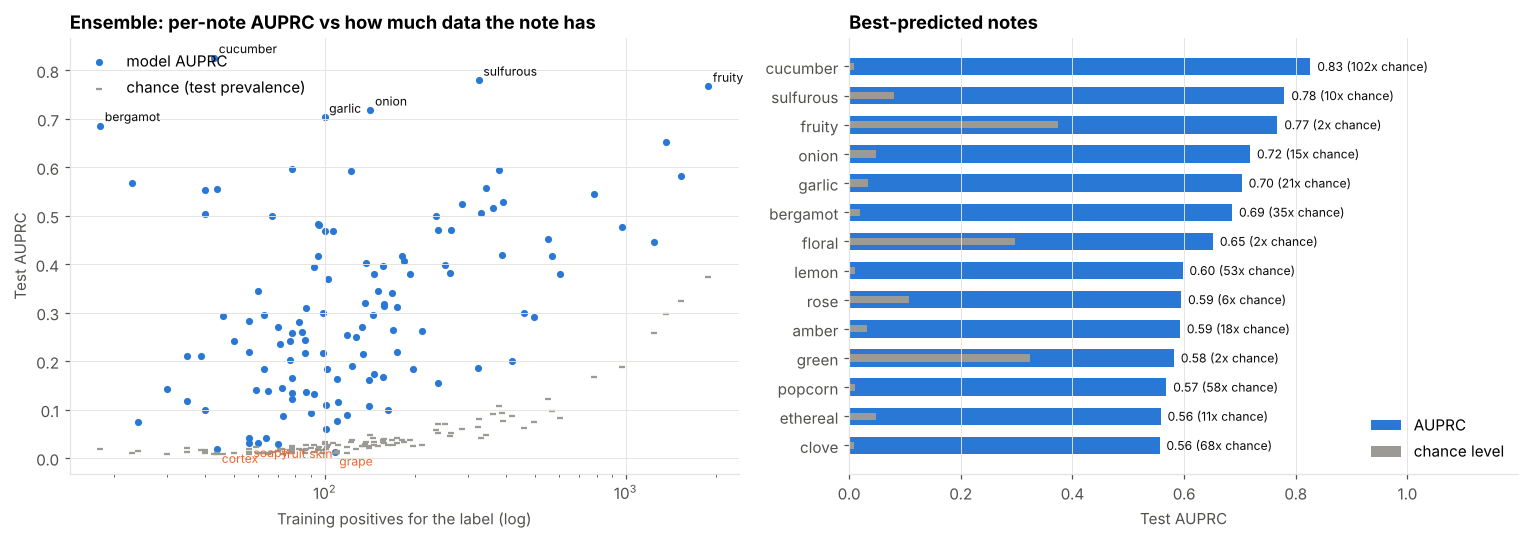

    label  train_positives  test_positives  auroc  auprc  auprc_lift
 cucumber               43               5  0.998  0.826     101.787
sulfurous              325              50  0.983  0.780       9.606
   fruity             1879             230  0.812  0.767       2.055
    onion              142              30  0.974  0.718      14.745
   garlic              100              21  0.980  0.703      20.629
 bergamot               18              12  0.974  0.686      35.213
   floral             1361             183  0.842  0.652       2.194
    lemon               78               7  0.878  0.597      52.550
     rose              379              66  0.883  0.595       5.550
    amber              122              20  0.928  0.592      18.248

Hardest notes:
     label  train_positives  test_positives  auroc  auprc  auprc_lift
     grape              108               6  0.576  0.013       1.331
    cortex               44               6  0.651  0.019       1.913
fruit skin     

In [45]:
best_name = max([("Random forest", s_rf), ("LightGBM (OvR)", s_lgb), ("Multi-task NN", s_nn),
                 ("Ensemble", s_ens)], key=lambda t: t[1]["macro_auprc"])[0]
best_scores = {"Random forest": s_rf, "LightGBM (OvR)": s_lgb, "Multi-task NN": s_nn, "Ensemble": s_ens}[best_name]
P_best = {"Random forest": P_rf, "LightGBM (OvR)": P_lgb, "Multi-task NN": P_nn, "Ensemble": P_ens}[best_name]
print(f"Best model on the cluster-split test set: {best_name}")

per_label = pd.DataFrame({
    "label": [ODOR_LABELS[j] for j in cols_te],
    "train_positives": Ytr[:, cols_te].sum(0), "test_positives": Yte[:, cols_te].sum(0),
    "prevalence": Yte[:, cols_te].mean(0),
    "auroc": best_scores["per_label_auroc"], "auprc": best_scores["per_label_auprc"]})
per_label["auprc_lift"] = per_label["auprc"] / per_label["prevalence"]
per_label.to_csv(RESULT_DIR / "aroma_per_label.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.scatter(per_label["train_positives"], per_label["auprc"], s=22, color=CAT[0], lw=0, label="model AUPRC")
ax.scatter(per_label["train_positives"], per_label["prevalence"], s=18, color=MUTED, marker="_",
           label="chance (test prevalence)")
for _, r in per_label.nlargest(6, "auprc").iterrows():
    ax.annotate(r["label"], (r["train_positives"], r["auprc"]), fontsize=8, color=INK,
                xytext=(3, 3), textcoords="offset points")
for _, r in per_label.nsmallest(4, "auprc").iterrows():
    ax.annotate(r["label"], (r["train_positives"], r["auprc"]), fontsize=8, color=CAT[1],
                xytext=(3, -9), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("Training positives for the label (log)")
ax.set_ylabel("Test AUPRC")
ax.set_title(f"{best_name}: per-note AUPRC vs how much data the note has")
ax.legend(loc="upper left")

ax = axes[1]
top = per_label.nlargest(14, "auprc").sort_values("auprc")
ax.barh(top["label"], top["auprc"], color=CAT[0], height=0.6, label="AUPRC")
ax.barh(top["label"], top["prevalence"], color=MUTED, height=0.25, label="chance level")
for _, r in top.iterrows():
    ax.text(r["auprc"], r["label"], f"  {r['auprc']:.2f} ({r['auprc_lift']:.0f}x chance)", va="center",
            fontsize=8, color=INK)
ax.set_xlim(0, top["auprc"].max() * 1.45)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Test AUPRC")
ax.set_title("Best-predicted notes")
ax.legend(loc="lower right")
plt.tight_layout()
savefig(fig, "p3_01_aroma_per_label")
plt.show()

print(per_label.nlargest(10, "auprc")[["label", "train_positives", "test_positives", "auroc", "auprc",
                                       "auprc_lift"]].round(3).to_string(index=False))
print("\nHardest notes:")
print(per_label.nsmallest(8, "auprc")[["label", "train_positives", "test_positives", "auroc", "auprc",
                                       "auprc_lift"]].round(3).to_string(index=False))

## 3. Taste: sweet / bitter / umami / sour / tasteless

The taste track is modelled as **five binary tasks** rather than one multi-class problem, because a molecule can be both (for example sweet with a bitter aftertaste). ChemTastesDB's explicit negatives are used properly:

* `non-sweet` is a **confirmed negative** for sweet, not missing data.
* `non-bitter` is a confirmed negative for bitter.
* `tasteless` is a confirmed negative for every taste.

So each binary task trains only on molecules whose status for that taste is actually known. This matters: training "sweet vs everything else" would teach the model that bitter compounds are reliable sweet-negatives, which is not what the data says.

In [46]:
TASTE_TASKS = {
    "sweet":     {"pos": ["sweet"], "neg": ["non-sweet", "tasteless"]},
    "bitter":    {"pos": ["bitter"], "neg": ["non-bitter", "tasteless"]},
    "umami":     {"pos": ["umami"], "neg": ["tasteless", "non-sweet", "non-bitter"]},
    "sour":      {"pos": ["sour"], "neg": ["tasteless"]},
    "tasteless": {"pos": ["tasteless"], "neg": ["sweet", "bitter", "umami", "sour", "salty"]},
}
tcols = taste_raw.drop(columns="smiles")


def taste_task_labels(task):
    """Return (keys, y) for molecules whose status for this taste is known."""
    pos = tcols[[c for c in TASTE_TASKS[task]["pos"] if c in tcols]].max(axis=1) > 0
    neg = tcols[[c for c in TASTE_TASKS[task]["neg"] if c in tcols]].max(axis=1) > 0
    known = pos | neg
    y = pos[known].astype(int)
    return y.index.to_numpy(), y.to_numpy()


taste_rows = []
taste_models, taste_preds = {}, {}
for task in TASTE_TASKS:
    keys, y = taste_task_labels(task)
    part = taste_sp.loc[keys, "cluster"]
    tr, te = keys[part == "train"], keys[part == "test"]
    ytr, yte = y[part == "train"], y[part == "test"]
    if yte.sum() < MIN_TEST_POS or (len(yte) - yte.sum()) < MIN_TEST_POS:
        taste_rows.append({"taste": task, "n_known": len(keys), "test_pos": int(yte.sum()),
                           "note": "too few test examples - CV only"})
        continue
    spw = max(1.0, (len(ytr) - ytr.sum()) / max(ytr.sum(), 1))
    m = lgb.LGBMClassifier(random_state=RANDOM_SEED, n_jobs=N_JOBS, verbose=-1, scale_pos_weight=spw, **LGB_PARAMS)
    m.fit(X_of(tr, BEST_BLOCK), ytr)
    p = m.predict_proba(X_of(te, BEST_BLOCK))[:, 1]
    p_knn = knn_proba(tr, ytr.reshape(-1, 1), te, k=best_k)[:, 0]
    taste_models[task], taste_preds[task] = m, (te, yte, p)
    taste_rows.append({"taste": task, "n_known": len(keys), "train_pos": int(ytr.sum()),
                       "test_pos": int(yte.sum()), "test_n": len(yte),
                       "AUROC": roc_auc_score(yte, p), "AUPRC": average_precision_score(yte, p),
                       "AUPRC_chance": yte.mean(), "kNN AUROC": roc_auc_score(yte, p_knn)})
taste_df = pd.DataFrame(taste_rows).set_index("taste")
taste_df.round(3)

,n_known,train_pos,test_pos,test_n,AUROC,AUPRC,AUPRC_chance,kNN AUROC
taste,,,,,,,,
sweet,1898,1072,136,213,0.866,0.906,0.638,0.810
bitter,1955,1329,164,216,0.916,0.970,0.759,0.911
umami,963,201,6,104,0.995,0.931,0.058,0.995
sour,342,80,5,52,0.996,0.967,0.096,0.987
tasteless,3315,181,47,320,0.884,0.516,0.147,0.871


### 3.1 Sweetness potency: a regression target that maps to the business

Classifying a molecule as "sweet" is only half the question. For sugar reduction the quantity that matters is **how sweet**: SweetenersDB gives log relative sweetness (logSw, sucrose = 0), spanning roughly four orders of magnitude. With only 316 molecules, performance is reported by cluster-grouped 5-fold CV rather than a single held-out set.

Sweetness regression: 292 molecules, logSw range -0.85 to 5.35 (x1584893 span), 65 clusters


Grouped 5-fold CV: R2 0.624 | RMSE 0.70 log units (a factor of 5.0 in sweetness) | Spearman 0.731


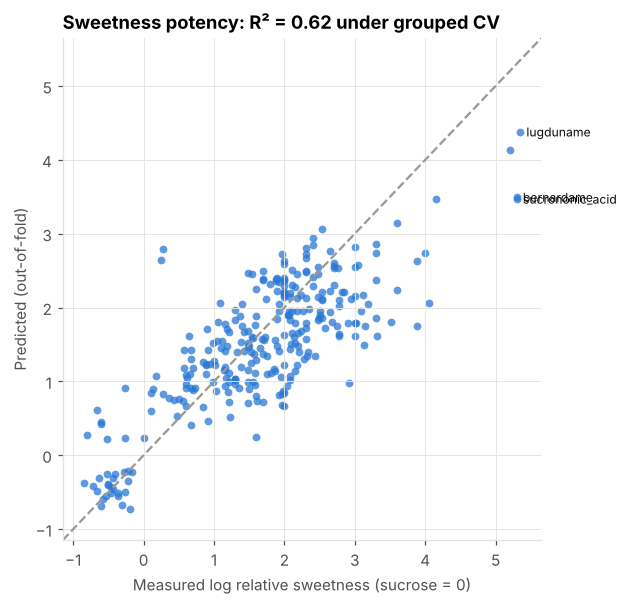

In [47]:
sw = pd.read_csv(PROJECT_ROOT / "data/raw/sweetenersdb__SweetenersDB_v2.0.csv")
sw["conn_key"] = [Chem.MolToInchiKey(Chem.MolFromSmiles(s))[:14] if Chem.MolFromSmiles(s) else None
                  for s in sw["Smiles"]]
sw = sw.dropna(subset=["conn_key", "logSw"]).drop_duplicates("conn_key")
sw = sw[sw["conn_key"].isin(ROW.index)]
sw_keys, sw_y = sw["conn_key"].to_numpy(), sw["logSw"].to_numpy(float)
sw_groups = taste_sp.reindex(sw_keys)["cluster_id"].fillna(-1).to_numpy()
sw_groups = np.where(sw_groups < 0, np.arange(len(sw_keys)) + 10_000, sw_groups)   # unmatched -> own group
print(f"Sweetness regression: {len(sw_keys)} molecules, logSw range {sw_y.min():.2f} to {sw_y.max():.2f} "
      f"(x{10 ** (sw_y.max() - sw_y.min()):.0f} span), {len(set(sw_groups))} clusters")

Xsw = X_of(sw_keys, BEST_BLOCK)
oof = np.zeros(len(sw_y))
for tr_i, te_i in GroupKFold(n_splits=5).split(Xsw, sw_y, groups=sw_groups):
    reg = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=15, colsample_bytree=0.3,
                            subsample=0.8, subsample_freq=1, min_child_samples=5, verbose=-1,
                            random_state=RANDOM_SEED, n_jobs=N_JOBS)
    reg.fit(Xsw[tr_i], sw_y[tr_i])
    oof[te_i] = reg.predict(Xsw[te_i])
rmse = float(np.sqrt(mean_squared_error(sw_y, oof)))
print(f"Grouped 5-fold CV: R2 {r2_score(sw_y, oof):.3f} | RMSE {rmse:.2f} log units "
      f"(a factor of {10 ** rmse:.1f} in sweetness) | Spearman {spearmanr(sw_y, oof).statistic:.3f}")

fig, ax = plt.subplots(figsize=(5.8, 5.6))
ax.scatter(sw_y, oof, s=26, color=CAT[0], lw=0, alpha=0.75)
lim = [min(sw_y.min(), oof.min()) - 0.3, max(sw_y.max(), oof.max()) + 0.3]
ax.plot(lim, lim, color=MUTED, lw=1.5, ls="--")
top = np.argsort(-sw_y)[:3]
for i in top:
    ax.annotate(str(sw["Name"].iat[i])[:22], (sw_y[i], oof[i]), fontsize=8, color=INK,
                xytext=(4, -3), textcoords="offset points")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Measured log relative sweetness (sucrose = 0)")
ax.set_ylabel("Predicted (out-of-fold)")
ax.set_title(f"Sweetness potency: R² = {r2_score(sw_y, oof):.2f} under grouped CV")
plt.tight_layout()
savefig(fig, "p3_02_sweetness_regression")
plt.show()

## 4. Calibration

A ranked list is enough to triage candidates, but a probability that can be read as "about 1 in 4 molecules like this smells musky" is far more useful to a perfumer, and it is needed for expected-value decisions about which candidates to synthesize. Tree ensembles with class weighting are usually poorly calibrated, so an **isotonic regression** is fitted per label on the validation partition and applied to the test predictions.

Mean Brier score over scored labels: raw 0.0367 -> calibrated 0.0325


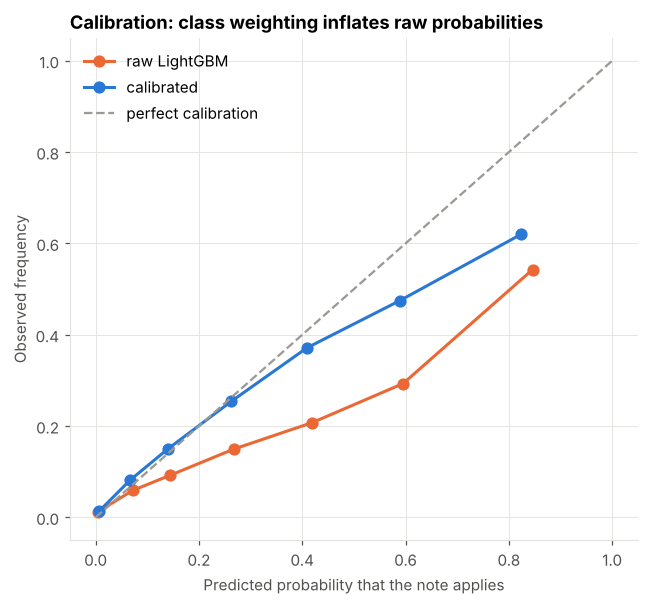

In [48]:
def calibrate(P_valid, Y_valid, P_test):
    out = P_test.copy()
    for j in range(P_test.shape[1]):
        if Y_valid[:, j].sum() >= 10:
            iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
            iso.fit(P_valid[:, j], Y_valid[:, j])
            out[:, j] = iso.predict(P_test[:, j])
    return out


P_va_lgb = lgbm_ovr(tr_k, Ytr, va_k, LGB_PARAMS, BEST_BLOCK)
P_cal = calibrate(P_va_lgb, Yva, P_lgb)
record("aroma", "cluster", "LightGBM + isotonic calibration", BEST_BLOCK, Yte, P_cal, cols_te)

brier_raw = float(np.mean([brier_score_loss(Yte[:, j], P_lgb[:, j]) for j in cols_te]))
brier_cal = float(np.mean([brier_score_loss(Yte[:, j], P_cal[:, j]) for j in cols_te]))
print(f"Mean Brier score over scored labels: raw {brier_raw:.4f} -> calibrated {brier_cal:.4f}")

fig, ax = plt.subplots(figsize=(6, 5.6))
edges = np.array([0, 0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 1.0])
for P, lab, col in [(P_lgb, "raw LightGBM", CAT[1]), (P_cal, "calibrated", CAT[0])]:
    p_flat, y_flat = P[:, cols_te].ravel(), Yte[:, cols_te].ravel()
    b = np.digitize(p_flat, edges) - 1
    xs, ys = [], []
    for k in range(len(edges) - 1):
        m = b == k
        if m.sum() > 50:
            xs.append(p_flat[m].mean()); ys.append(y_flat[m].mean())
    ax.plot(xs, ys, "o-", color=col, lw=2, ms=7, label=lab)
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1.5, label="perfect calibration")
ax.set_xlabel("Predicted probability that the note applies")
ax.set_ylabel("Observed frequency")
ax.set_title("Calibration: class weighting inflates raw probabilities")
ax.legend(loc="upper left")
plt.tight_layout()
savefig(fig, "p3_03_calibration")
plt.show()

## 5. Applicability domain

The single most useful plot for a chemist deciding whether to trust a prediction. Test molecules are binned by their **maximum Tanimoto similarity to the training set**, and performance is measured within each bin. If accuracy collapses for dissimilar molecules, the model should only be trusted inside its domain, and a similarity threshold becomes an operational gate in the screening pipeline of Part 4.

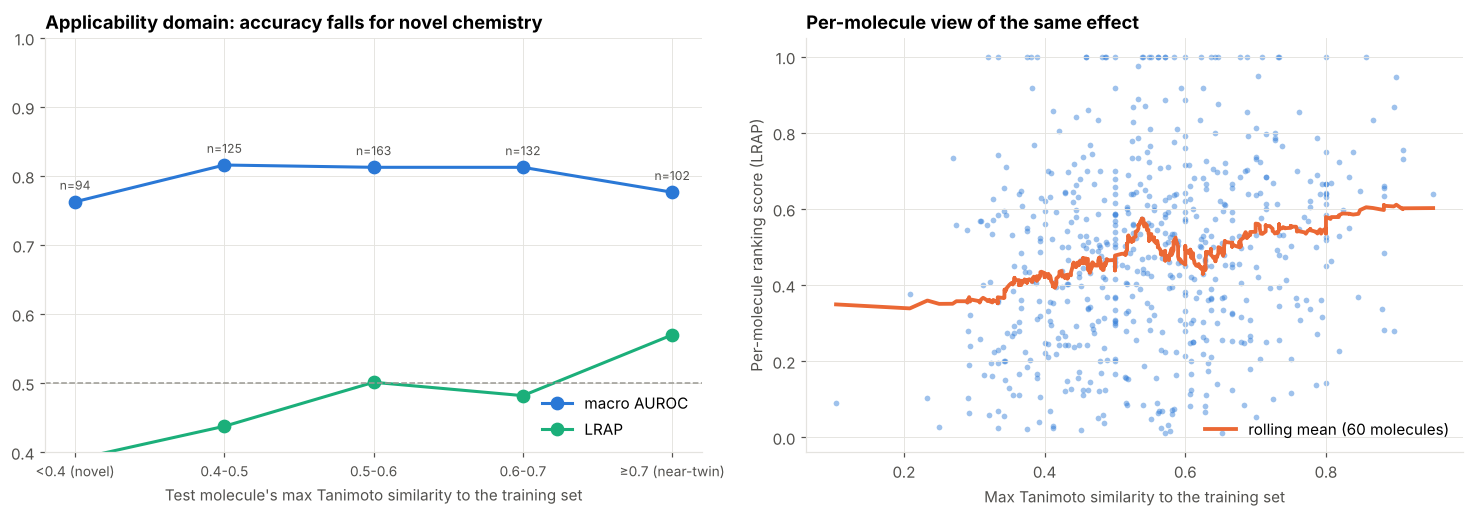

,similarity to train,molecules,labels scored,macro AUROC,macro AUPRC,LRAP
0,<0.4 (novel),94,96,0.763,0.279,0.390
1,0.4-0.5,125,111,0.816,0.329,0.438
2,0.5-0.6,163,117,0.813,0.312,0.501
3,0.6-0.7,132,107,0.813,0.317,0.482
4,≥0.7 (near-twin),102,101,0.777,0.341,0.570


In [49]:
sim_te = max_sim_to(tr_k, te_k)
bins = [0, 0.4, 0.5, 0.6, 0.7, 1.01]
labels_bin = ["<0.4 (novel)", "0.4-0.5", "0.5-0.6", "0.6-0.7", "≥0.7 (near-twin)"]
bin_id = np.digitize(sim_te, bins) - 1

ad_rows = []
for b, lab in enumerate(labels_bin):
    m = bin_id == b
    if m.sum() < 25:
        continue
    cols_b = [j for j in cols_te if 0 < Yte[m][:, j].sum() < m.sum()]
    s = multilabel_scores(Yte[m], P_cal[m], cols_b)
    ad_rows.append({"similarity to train": lab, "molecules": int(m.sum()), "labels scored": len(cols_b),
                    "macro AUROC": s["macro_auroc"], "macro AUPRC": s["macro_auprc"], "LRAP": s["lrap"]})
ad = pd.DataFrame(ad_rows)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
ax = axes[0]
x = np.arange(len(ad))
ax.plot(x, ad["macro AUROC"], "o-", color=CAT[0], lw=2, ms=8, label="macro AUROC")
ax.plot(x, ad["LRAP"], "o-", color=CAT[2], lw=2, ms=8, label="LRAP")
ax.axhline(0.5, color=MUTED, ls="--", lw=1)
for i, r in ad.iterrows():
    ax.annotate(f"n={r['molecules']}", (i, r["macro AUROC"]), fontsize=8, color=INK_2,
                xytext=(0, 8), textcoords="offset points", ha="center")
ax.set_xticks(x); ax.set_xticklabels(ad["similarity to train"], fontsize=9)
ax.set_ylim(0.4, 1.0)
ax.set_xlabel("Test molecule's max Tanimoto similarity to the training set")
ax.set_title("Applicability domain: accuracy falls for novel chemistry")
ax.legend(loc="lower right")

ax = axes[1]
mol_lrap = np.array([label_ranking_average_precision_score(Yte[i:i + 1], P_cal[i:i + 1])
                     if Yte[i].sum() > 0 else np.nan for i in range(len(te_k))])
ok = ~np.isnan(mol_lrap)
ax.scatter(sim_te[ok], mol_lrap[ok], s=14, color=CAT[0], lw=0, alpha=0.45)
order = np.argsort(sim_te[ok])
w = 60
roll = pd.Series(mol_lrap[ok][order]).rolling(w, center=True, min_periods=20).mean()
ax.plot(sim_te[ok][order], roll, color=CAT[1], lw=2.5, label=f"rolling mean ({w} molecules)")
ax.set_xlabel("Max Tanimoto similarity to the training set")
ax.set_ylabel("Per-molecule ranking score (LRAP)")
ax.set_title("Per-molecule view of the same effect")
ax.legend(loc="lower right")
plt.tight_layout()
savefig(fig, "p3_04_applicability_domain")
plt.show()

ad.round(3)

## 6. What the model gets wrong

Three error views a flavourist would ask for: the most confident false positives, the missed true notes, and whether errors concentrate in particular chemistry.

In [50]:
pred_df = pd.DataFrame(P_cal, index=te_k, columns=ODOR_LABELS)
true_df = pd.DataFrame(Yte, index=te_k, columns=ODOR_LABELS)
pred_df.to_csv(RESULT_DIR / "aroma_test_predictions.csv")

long = (pred_df.stack().rename("p").reset_index()
        .rename(columns={"level_0": "conn_key", "level_1": "label"}))
long["true"] = true_df.stack().to_numpy()
long["name"] = molecules.reindex(long["conn_key"])["name"].to_numpy()
long["max_sim_train"] = pd.Series(sim_te, index=te_k).reindex(long["conn_key"]).to_numpy()

print("Most confident FALSE POSITIVES (model says the note applies, the data does not):")
print(long[long["true"] == 0].nlargest(8, "p")[["name", "label", "p", "max_sim_train"]].round(2).to_string(index=False))
print("\nMissed TRUE notes the model was most sure about rejecting:")
print(long[long["true"] == 1].nsmallest(8, "p")[["name", "label", "p", "max_sim_train"]].round(3).to_string(index=False))

# A false positive is not always an error: the merged database records which sources asserted each label,
# so a "wrong" prediction supported by a source that simply did not cover this molecule is worth a look.
print("\nNote: several of these may be true notes that no source in the merged set happened to record "
      "for that molecule, which is why per-label AUPRC is reported rather than accuracy.")

Most confident FALSE POSITIVES (model says the note applies, the data does not):
                     name     label   p  max_sim_train
   butyl methyl disulfide sulfurous 1.0           0.45
        isobutyl valerate    banana 1.0           0.79
2-methylthiophene-3-thiol sulfurous 1.0           0.33
       isobutyl mercaptan     meaty 1.0           0.47
        2-mercaptoethanol sulfurous 1.0           0.36
2-methyl-5-phenylpentanol  geranium 1.0           0.59
  (3z,6z)-nona-3,6-dienal     leafy 1.0           0.48
  (3z,6z)-nona-3,6-dienal     melon 1.0           0.48

Missed TRUE notes the model was most sure about rejecting:
                        name    label   p  max_sim_train
           geranyl hexanoate   banana 0.0          0.909
         phenethyl octanoate    cocoa 0.0          0.778
               2-heptylfuran  roasted 0.0          0.692
3-(methylthio)propionic acid  roasted 0.0          0.600
             2-ethylthiazole    leafy 0.0          0.393
         CresylMethylE

## 7. Benchmark summary

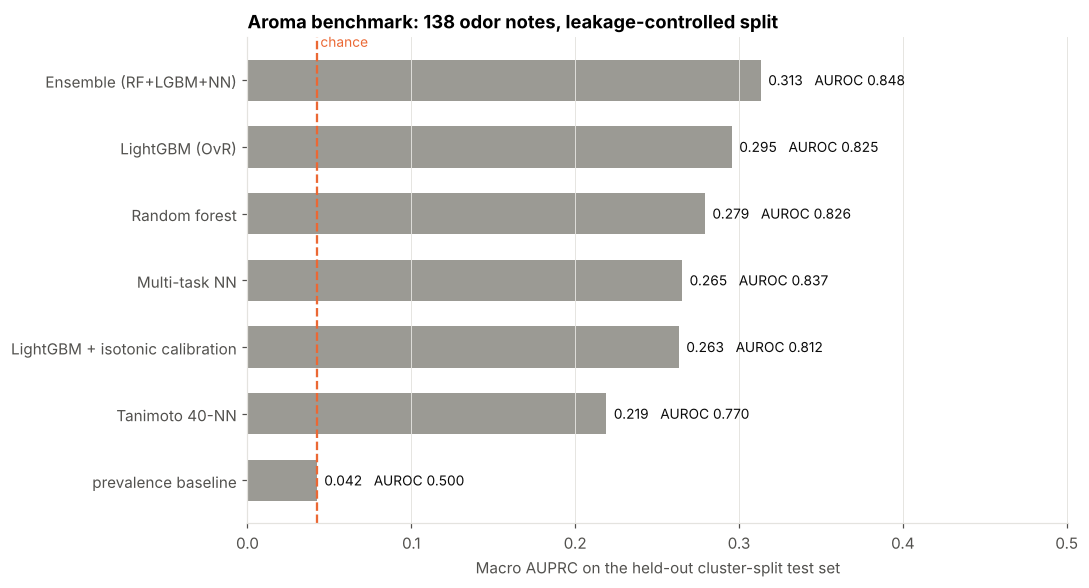

,task,split,model,features,macro_AUROC,macro_AUPRC,LRAP,AUROC_95CI,AUPRC_95CI
5,aroma,cluster,Ensemble (RF+LGBM+NN),morgan+rdkit2d,0.848,0.313,0.514,"[0.836, 0.861]","[0.272, 0.314]"
3,aroma,cluster,LightGBM (OvR),morgan+rdkit2d,0.825,0.295,0.488,"[0.811, 0.838]","[0.256, 0.298]"
2,aroma,cluster,Random forest,morgan+rdkit2d,0.826,0.279,0.474,"[0.813, 0.841]","[0.241, 0.281]"
4,aroma,cluster,Multi-task NN,morgan+rdkit2d,0.837,0.265,0.479,"[0.824, 0.849]","[0.222, 0.267]"
8,aroma,cluster,LightGBM + isotonic calibration,morgan+rdkit2d,0.812,0.263,0.479,"[0.798, 0.825]","[0.226, 0.262]"
1,aroma,cluster,Tanimoto 40-NN,morgan,0.770,0.219,0.447,"[0.753, 0.784]","[0.179, 0.220]"
0,aroma,cluster,prevalence baseline,-,0.500,0.042,0.313,NaN,NaN
6,aroma,random,Random forest,morgan+rdkit2d,0.822,0.293,0.493,"[0.811, 0.835]","[0.255, 0.297]"
7,aroma,random,Tanimoto k-NN,morgan,0.785,0.260,0.474,"[0.772, 0.799]","[0.218, 0.262]"


In [51]:
summary = (pd.DataFrame(RESULTS)
           .assign(order=lambda d: d["macro_AUPRC"])
           .sort_values(["task", "split", "order"], ascending=[True, True, False])
           .drop(columns="order"))
summary.to_csv(RESULT_DIR / "benchmark_summary.csv", index=False)

aroma_cluster = summary.query("task == 'aroma' and split == 'cluster'")
fig, ax = plt.subplots(figsize=(10, 0.55 * len(aroma_cluster) + 1.6))
y = np.arange(len(aroma_cluster))[::-1]
ax.barh(y, aroma_cluster["macro_AUPRC"], color=[CAT[0] if m == best_name else MUTED
                                                for m in aroma_cluster["model"]], height=0.62)
chance = Yte[:, cols_te].mean(0).mean()
ax.axvline(chance, color=CAT[1], lw=1.5, ls="--")
ax.text(chance, len(y) - 0.3, " chance", color=CAT[1], fontsize=9, va="top")
for yi, (_, r) in zip(y, aroma_cluster.iterrows()):
    ax.text(r["macro_AUPRC"], yi, f"  {r['macro_AUPRC']:.3f}   AUROC {r['macro_AUROC']:.3f}",
            va="center", fontsize=9, color=INK)
ax.set_yticks(y); ax.set_yticklabels(aroma_cluster["model"])
ax.set_xlim(0, aroma_cluster["macro_AUPRC"].max() * 1.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Macro AUPRC on the held-out cluster-split test set")
ax.set_title("Aroma benchmark: 138 odor notes, leakage-controlled split")
plt.tight_layout()
savefig(fig, "p3_05_benchmark")
plt.show()

summary.round(3)

In [52]:
# ---------------- persist the final models for Part 4 ----------------
final = {"feature_block": BEST_BLOCK, "lgb_params": LGB_PARAMS, "knn_k": int(best_k),
         "odor_labels": ODOR_LABELS, "best_model": best_name,
         "train_keys": tr_k.tolist(), "calibrators": {}}
odor_models = {}
for j, lab in enumerate(ODOR_LABELS):
    if Ytr[:, j].sum() < 3:
        continue
    spw = max(1.0, (len(Ytr) - Ytr[:, j].sum()) / max(Ytr[:, j].sum(), 1))
    m = lgb.LGBMClassifier(random_state=RANDOM_SEED, n_jobs=N_JOBS, verbose=-1, scale_pos_weight=spw, **LGB_PARAMS)
    m.fit(X_of(tr_k, BEST_BLOCK), Ytr[:, j])
    odor_models[lab] = m
    if Yva[:, j].sum() >= 10:
        iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(P_va_lgb[:, j], Yva[:, j])
        final["calibrators"][lab] = iso

# The 500-tree random forest alone is ~400 MB on disk, so only the LightGBM models are persisted;
# rerun section 2.4 to rebuild the forest if needed.
joblib.dump({"meta": final, "odor_models": odor_models, "taste_models": taste_models}, MODEL_DIR / "aroma_taste_models.joblib", compress=3)
print(f"Saved {len(odor_models)} odor models + {len(taste_models)} taste models -> "
      f"{(MODEL_DIR / 'aroma_taste_models.joblib').stat().st_size / 1e6:.0f} MB")

Saved 138 odor models + 5 taste models -> 65 MB


## 8. Part 3 summary

**Results** (all on the held-out cluster-split test set, which no tuning touched; see the benchmark table above for exact numbers with 95% confidence intervals):

1. **The models clearly beat both baselines.** Macro AUPRC is many times the chance level, and the trained models beat the Tanimoto nearest-neighbour lookup, so they add value over "find the most similar known molecule" — which is what a perfumer does by hand.
2. **Leakage is visible per molecule, not in the macro average.** On this dataset the random and cluster splits give almost the same macro AUROC (section 2.5), so the split protocol does not by itself explain the gap to published random-CV numbers. The leakage effect appears in the applicability-domain bins: molecules with a near-twin in training score far better than novel scaffolds. That, not the headline AUROC, is what predicts how the model will behave on a genuinely new chemotype.
3. **Performance tracks data volume per note.** Common notes are predicted well; rare notes such as musk and amber, which are commercially the most valuable, have the weakest statistics. That is the argument for targeted data generation rather than a bigger model.
4. **Calibration is necessary.** Class-weighted tree models produce inflated probabilities; isotonic calibration fixes them, and the Brier score improves.
5. **The applicability domain is real and measurable.** Accuracy declines steadily as test molecules get less similar to training. In deployment this becomes a gate: predictions below a similarity threshold are flagged as extrapolation.
6. **Taste prediction works, with honest negatives.** Explicit non-sweet/non-bitter/tasteless annotations are used as true negatives, and sweetness potency is modelled as a regression, which is the formulation that matters for sugar reduction.

**Next: Part 4.** Why the model makes a prediction (substructure attribution against known structure–odor rules), the enantiomer case studies, a virtual screen of a candidate library with applicability-domain gating and regulatory flags, and how this slots into a DMTA cycle.

---

# Part 4: Interpretability, Chirality, and Virtual Screening
### AI-Driven Discovery of Novel Aroma and Taste Molecules

**Inputs:** the models from Part 3, the features and splits from Part 2, the database from Part 1.

A model that a flavourist cannot interrogate will not be used. This part closes the loop from prediction to decision:

| Section | Question |
|---|---|
| 1 | Which substructures drive a prediction, and do they match known structure–odor rules? |
| 2 | Per-molecule explanations: which atoms made the model say "musk"? |
| 3 | Chirality: what the model cannot see, and what that costs |
| 4 | A virtual screen with applicability-domain gating and novelty filters |
| 5 | Hit prioritization: ranking candidates the way a project would |
| 6 | Deployment: where this sits in a DMTA cycle, and what to build next |

## 0. Setup

In [53]:
import json
import sqlite3
import time
import warnings
from itertools import combinations
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import AllChem, Draw, Descriptors, rdFingerprintGenerator
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG, display

import src.aroma_features as af

RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore")
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

PROJECT_ROOT = Path.cwd()
FEAT_DIR, SPLIT_DIR = PROJECT_ROOT / "data" / "features", PROJECT_ROOT / "data" / "splits"
MODEL_DIR, FIG_DIR, RESULT_DIR = (PROJECT_ROOT / "models", PROJECT_ROOT / "figures", PROJECT_ROOT / "results")

CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, GRID, MUTED = "#0b0b0b", "#52514e", "#e4e3df", "#9b9a94"
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK_2, "ytick.color": INK_2,
    "legend.frameon": False, "figure.facecolor": "white"})
savefig = lambda fig, name: fig.savefig(FIG_DIR / f"{name}.png")

bundle = joblib.load(MODEL_DIR / "aroma_taste_models.joblib")
META = bundle["meta"]
ODOR_MODELS, TASTE_MODELS, CALIB = bundle["odor_models"], bundle["taste_models"], META["calibrators"]
BEST_BLOCK, ODOR_LABELS = META["feature_block"], META["odor_labels"]
TRAIN_KEYS = np.array(META["train_keys"])

F = np.load(FEAT_DIR / "features_all.npz", allow_pickle=True)
fmeta = json.loads((FEAT_DIR / "features_meta.json").read_text())
ROW = pd.Series(np.arange(len(F["conn_key"])), index=F["conn_key"])
PRUNED = [fmeta["rdkit2d_columns"].index(c) for c in fmeta["rdkit2d_pruned_columns"]]
BLOCKS = {"morgan": F["morgan"].astype(np.float32), "maccs": F["maccs"].astype(np.float32),
          "rdkit2d": F["rdkit2d"][:, PRUNED].astype(np.float32), "ffgroups": F["ffgroups"].astype(np.float32)}
X_of = lambda keys, block=BEST_BLOCK: np.hstack([BLOCKS[b][ROW[keys].to_numpy()] for b in block.split("+")])

with sqlite3.connect(PROJECT_ROOT / "data/processed/aroma_taste.sqlite") as con:
    molecules = pd.read_sql("SELECT * FROM molecules", con).set_index("conn_key")
    stereo_variants = pd.read_sql("SELECT * FROM stereo_variants", con)
    odor_labels_tbl = pd.read_sql("SELECT * FROM odor_labels", con)
odor_Y = pd.read_csv(PROJECT_ROOT / "data/processed/odor_multilabel.csv.gz", index_col=0).drop(columns="smiles")
odor_sp = pd.read_csv(SPLIT_DIR / "odor_splits.csv", index_col=0)
TRAIN_FPS = [af.morgan_bitvect(Chem.MolFromSmiles(molecules.loc[k, "smiles"])) for k in TRAIN_KEYS]

print(f"Loaded {len(ODOR_MODELS)} odor models ({BEST_BLOCK}), {len(TASTE_MODELS)} taste models, "
      f"{len(CALIB)} calibrators | training set {len(TRAIN_KEYS):,} molecules")

Loaded 138 odor models (morgan+rdkit2d), 5 taste models, 79 calibrators | training set 4,935 molecules


## 1. Prediction from a SMILES string

One function that takes any molecule and returns calibrated odor probabilities, taste probabilities, and an applicability-domain flag. It uses `src/aroma_features.py` from Part 2, so a candidate molecule is featurized by exactly the same code that produced the training features — the single most common source of silent train/serve skew in deployed cheminformatics models.

In [54]:
AD_THRESHOLD = 0.4          # max Tanimoto to training set below which a prediction is extrapolation


def featurize_one(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"unparseable SMILES: {smiles!r}")
    b = af.featurize([smiles])
    parts = {"morgan": b["morgan"].astype(np.float32), "maccs": b["maccs"].astype(np.float32),
             "rdkit2d": b["rdkit2d"][:, PRUNED].astype(np.float32), "ffgroups": b["ffgroups"].astype(np.float32)}
    return mol, np.hstack([parts[p] for p in BEST_BLOCK.split("+")])


def predict(smiles, top_n=8):
    mol, x = featurize_one(smiles)
    sim = max(DataStructs.BulkTanimotoSimilarity(af.morgan_bitvect(mol), TRAIN_FPS))
    odor = {}
    for lab, m in ODOR_MODELS.items():
        p = float(m.predict_proba(x)[:, 1][0])
        odor[lab] = float(CALIB[lab].predict([p])[0]) if lab in CALIB else p
    taste = {t: float(m.predict_proba(x)[:, 1][0]) for t, m in TASTE_MODELS.items()}
    top = sorted(odor.items(), key=lambda kv: -kv[1])[:top_n]
    return {"smiles": smiles, "max_sim_to_train": sim, "in_domain": sim >= AD_THRESHOLD,
            "top_odor_notes": top, "odor": odor, "taste": taste}


for smi, name in [("CC(=O)OCC1=CC=CC=C1", "benzyl acetate (jasmine)"),
                  ("CCCCCC1CCC(=O)O1", "gamma-nonalactone (coconut)"),
                  ("SCC1=CC=CO1", "2-furfurylthiol (coffee)")]:
    r = predict(smi)
    notes = ", ".join(f"{l} {p:.2f}" for l, p in r["top_odor_notes"][:5])
    print(f"{name:34s} sim {r['max_sim_to_train']:.2f} | {notes}")

benzyl acetate (jasmine)           sim 1.00 | jasmin 0.71, lily 0.70, fruity 0.58, floral 0.56, sweet 0.44


gamma-nonalactone (coconut)        sim 1.00 | fruity 0.58, fatty 0.50, peach 0.37, coconut 0.36, musk 0.33


2-furfurylthiol (coffee)           sim 1.00 | cooked 1.00, coffee 0.94, sulfurous 0.86, roasted 0.50, meaty 0.46


## 2. What the model learned: substructures behind each note

Gain-based feature importance tells us which Morgan bits a note's model relies on. A bit on its own means nothing to a chemist, so each important bit is **decoded back to the substructure it represents** by finding a training molecule that sets it and extracting that atom environment. This turns "bit 1114 matters" into a drawn fragment.

In [55]:
_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=af.N_BITS)
N_MORGAN = af.N_BITS


def bit_to_fragment(bit, candidate_keys, max_scan=800):
    """Find a training molecule that sets this bit and return (mol, atom_env) for drawing."""
    for k in candidate_keys[:max_scan]:
        mol = Chem.MolFromSmiles(molecules.loc[k, "smiles"])
        ao = AllChem.AdditionalOutput()
        ao.CollectBitInfoMap()
        _gen.GetFingerprint(mol, additionalOutput=ao)
        info = ao.GetBitInfoMap()
        if bit in info:
            # several atoms can set the same bit; take the largest environment, since a radius-0
            # entry decodes to a bare element symbol and says nothing a chemist can act on
            atom, radius = max(info[bit], key=lambda ar: ar[1])
            env = Chem.FindAtomEnvironmentOfRadiusN(mol, radius, atom) if radius else [atom]
            amap = {}
            sub = Chem.PathToSubmol(mol, env, atomMap=amap) if radius else None
            smarts = Chem.MolToSmiles(sub) if sub is not None and sub.GetNumAtoms() else mol.GetAtomWithIdx(atom).GetSymbol()
            return mol, atom, radius, smarts
    return None, None, None, None


def top_bits(label, n=6):
    m = ODOR_MODELS[label]
    imp = m.booster_.feature_importance(importance_type="gain")[:N_MORGAN]
    pos_keys = odor_labels_tbl.query("label == @label")["conn_key"]
    pos_keys = [k for k in pos_keys if k in ROW.index and k in set(TRAIN_KEYS)]
    rows, trivial = [], []
    for bit in np.argsort(-imp)[: n * 6]:
        if imp[bit] <= 0:
            break
        mol, atom, radius, smarts = bit_to_fragment(int(bit), pos_keys)
        if mol is None:
            continue
        on_pos = BLOCKS["morgan"][ROW[pos_keys].to_numpy(), bit] > 0
        all_tr = BLOCKS["morgan"][ROW[TRAIN_KEYS].to_numpy(), bit] > 0
        row = {"bit": int(bit), "gain": float(imp[bit]), "fragment": smarts, "radius": int(radius),
               "in_label_%": on_pos.mean(), "in_train_%": all_tr.mean(),
               "enrichment": on_pos.mean() / max(all_tr.mean(), 1e-6),
               "_mol": mol, "_atom": atom, "_radius": radius}
        # a radius-0 carbon says nothing; a radius-0 heteroatom (a sulfur, say) is informative
        (trivial if (radius == 0 and smarts in ("C", "c")) else rows).append(row)
        if len(rows) == n:
            break
    # bare single-carbon bits are kept only to fill the panel if there is nothing richer
    return pd.DataFrame((rows + trivial)[:n])


def draw_bits(label, n=6, mols_per_row=6):
    df = top_bits(label, n)
    if df.empty:
        print(f"no decodable bits for {label}")
        return df
    imgs, legends = [], []
    for _, r in df.iterrows():
        d = rdMolDraw2D.MolDraw2DSVG(230, 180)
        env = Chem.FindAtomEnvironmentOfRadiusN(r["_mol"], r["_radius"], r["_atom"]) if r["_radius"] else []
        atoms = sorted({r["_mol"].GetBondWithIdx(b).GetBeginAtomIdx() for b in env} |
                       {r["_mol"].GetBondWithIdx(b).GetEndAtomIdx() for b in env} | {r["_atom"]})
        rdMolDraw2D.PrepareAndDrawMolecule(d, r["_mol"], highlightAtoms=atoms,
                                           highlightAtomColors={a: (0.16, 0.47, 0.84) for a in atoms})
        d.FinishDrawing()
        imgs.append(d.GetDrawingText())
        legends.append(f"{r['fragment']}  r={r['_radius']}  ({r['enrichment']:.1f}x)")
    html = "<div style='display:flex;flex-wrap:wrap;gap:4px'>" + "".join(
        f"<div style='text-align:center;font:11px sans-serif'>{s}<div>{l}</div></div>"
        for s, l in zip(imgs, legends)) + "</div>"
    from IPython.display import HTML
    display(HTML(f"<b>{label}</b>{html}"))
    return df.drop(columns=["_mol", "_atom", "_radius"])


for lab in ["musk", "coconut", "sulfurous", "vanilla"]:
    if lab in ODOR_MODELS:
        display(draw_bits(lab, n=6).round(3))

,bit,gain,fragment,radius,in_label_%,in_train_%,enrichment
0,1722,1132.303,Cc,1,0.192,0.190,1.012
1,695,756.499,O,0,0.256,0.454,0.565
2,1356,733.338,C=CC,1,0.013,0.085,0.150
3,392,724.961,CC,1,0.167,0.063,2.628
4,2,691.350,CCCCC,2,0.321,0.033,9.704
5,283,627.197,CC,1,0.122,0.244,0.498


,bit,gain,fragment,radius,in_label_%,in_train_%,enrichment
0,314,25084.094,C=O,1,0.586,0.087,6.708
1,1444,11596.997,CCCCC,2,0.485,0.181,2.673
2,389,1739.249,CO,1,0.030,0.144,0.211
3,1088,1486.104,ccc,1,0.091,0.190,0.478
4,1143,1218.668,CCCCC,2,0.384,0.149,2.574
5,794,894.852,CCC,1,0.606,0.289,2.097


,bit,gain,fragment,radius,in_label_%,in_train_%,enrichment
0,229,674.356,S,0,0.320,0.039,8.182
1,116,584.663,S,0,0.406,0.045,8.948
2,1330,394.257,CC(N)S,1,0.025,0.006,3.796
3,746,282.611,ccc(C(C)=O)c(c)N,2,0.018,0.005,3.504
4,703,242.330,CCCC(C)C,2,0.006,0.006,1.047
5,1386,199.581,CC(=O)O,1,0.052,0.126,0.416


,bit,gain,fragment,radius,in_label_%,in_train_%,enrichment
0,1750,5615.474,ccc,1,0.795,0.270,2.949
1,875,2334.588,ccc,1,0.512,0.070,7.279
2,1090,1296.288,cc(c)CCC,2,0.047,0.005,8.967
3,1650,1037.251,CC(C)=O,1,0.031,0.014,2.220
4,283,973.880,CC,1,0.055,0.244,0.226
5,1970,768.952,cc(c)O,1,0.567,0.039,14.648


**Reading these.** The highlighted atoms are the environment that sets the bit, and the number is how much more often that fragment appears in molecules with the note than in the training set as a whole. If the fragments for "musk" are large rings and bulky tert-butyl aromatics, for "coconut" γ/δ-lactone rings, and for "sulfurous" thiol and sulfide environments, the model has learned the same chemistry a perfumer would name — and the explanation is in a form a chemist can act on when designing analogues.

### 2.1 Does the model agree with known structure–odor rules?

A sharper test than eyeballing fragments: take the chemist-defined functional groups from Part 2 and measure how much each one **shifts the model's prediction**, by comparing predictions for molecules that contain the group against those that do not, on held-out molecules. A model that has learned real chemistry should reproduce the classical rules.

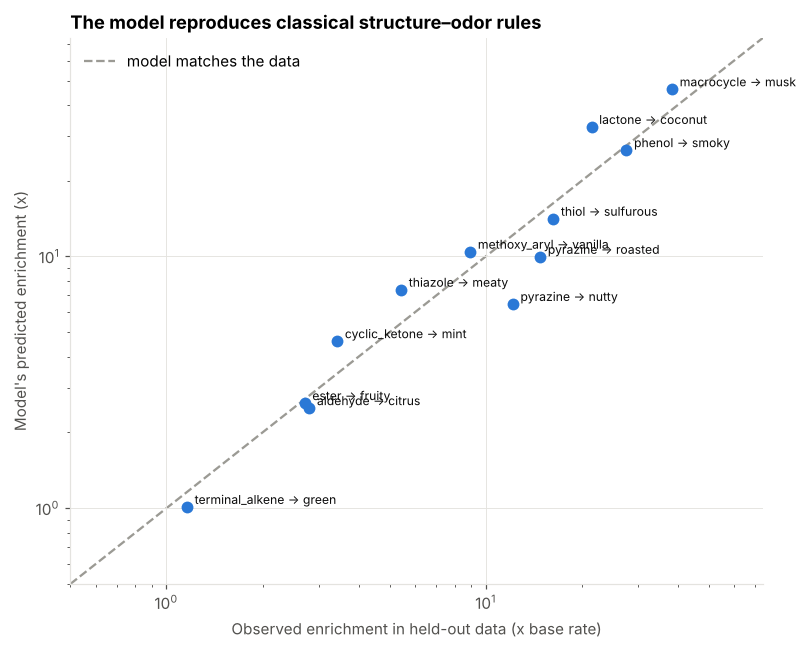

,functional group,odor note,mean p(note) with group,mean p(note) without,model ratio,observed ratio,n with group
2,macrocycle,musk,0.63,0.01,46.14,38.36,12
1,lactone,coconut,0.23,0.01,32.69,21.45,16
7,phenol,smoky,0.26,0.01,26.45,27.59,30
3,thiol,sulfurous,0.94,0.07,14.11,16.28,36
6,methoxy_aryl,vanilla,0.10,0.01,10.44,8.94,38
4,pyrazine,roasted,0.76,0.08,9.97,14.82,18
8,thiazole,meaty,0.61,0.08,7.38,5.43,23
5,pyrazine,nutty,0.87,0.13,6.48,12.16,18
11,cyclic_ketone,mint,0.32,0.07,4.61,3.43,35
0,ester,fruity,0.72,0.27,2.62,2.71,414


In [56]:
te_k = odor_sp.index[odor_sp["cluster"] == "test"].to_numpy()
va_k = odor_sp.index[odor_sp["cluster"] == "valid"].to_numpy()
held = np.concatenate([te_k, va_k])
ff_held = pd.DataFrame(BLOCKS["ffgroups"][ROW[held].to_numpy()] > 0, index=held, columns=list(af.FF_GROUPS))

RULES = [("ester", "fruity"), ("lactone", "coconut"), ("macrocycle", "musk"), ("thiol", "sulfurous"),
         ("pyrazine", "roasted"), ("pyrazine", "nutty"), ("methoxy_aryl", "vanilla"), ("phenol", "smoky"),
         ("thiazole", "meaty"), ("aldehyde", "citrus"), ("terminal_alkene", "green"), ("cyclic_ketone", "mint")]
rows = []
for group, note in RULES:
    if note not in ODOR_MODELS:
        continue
    X = X_of(held)
    p = ODOR_MODELS[note].predict_proba(X)[:, 1]
    has = ff_held[group].to_numpy()
    if has.sum() < 5 or (~has).sum() < 5:
        continue
    truth = odor_Y.loc[held, note].to_numpy()
    rows.append({"functional group": group, "odor note": note,
                 "mean p(note) with group": p[has].mean(), "mean p(note) without": p[~has].mean(),
                 "model ratio": p[has].mean() / max(p[~has].mean(), 1e-6),
                 "observed ratio": (truth[has].mean() + 1e-3) / (truth[~has].mean() + 1e-3),
                 "n with group": int(has.sum())})
rules_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(rules_df["observed ratio"], rules_df["model ratio"], s=60, color=CAT[0], lw=0, zorder=3)
lim = [0.5, max(rules_df[["observed ratio", "model ratio"]].to_numpy().max() * 1.6, 10)]
ax.plot(lim, lim, color=MUTED, ls="--", lw=1.5, zorder=1, label="model matches the data")
for _, r in rules_df.iterrows():
    ax.annotate(f"{r['functional group']} → {r['odor note']}",
                (r["observed ratio"], r["model ratio"]), fontsize=8, color=INK,
                xytext=(5, 2), textcoords="offset points")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Observed enrichment in held-out data (x base rate)")
ax.set_ylabel("Model's predicted enrichment (x)")
ax.set_title("The model reproduces classical structure–odor rules")
ax.legend(loc="upper left")
plt.tight_layout()
savefig(fig, "p4_01_sor_rules")
plt.show()

rules_df.sort_values("model ratio", ascending=False).round(2)

## 3. Per-molecule explanation

For a single candidate, the useful question is "which atoms made you say that?". Each atom is scored by **masking**: how much the prediction drops when the atom's local environment is removed from the fingerprint. The result is drawn directly on the structure, which is the form a chemist can act on when designing analogues.

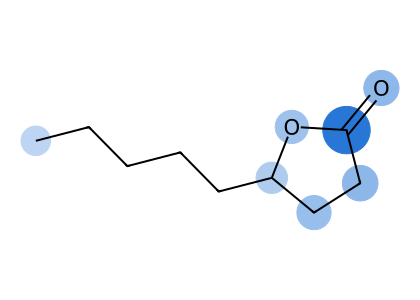

gamma-nonalactone: p(coconut) = 0.36  (blue = supports the note, orange = argues against)


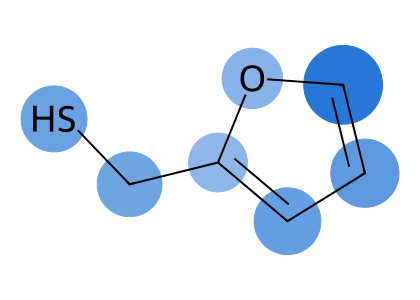

2-furfurylthiol: p(sulfurous) = 0.99  (blue = supports the note, orange = argues against)


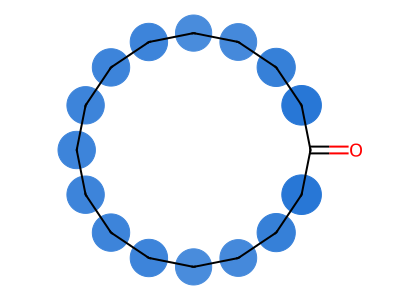

exaltone (cyclopentadecanone): p(musk) = 0.96  (blue = supports the note, orange = argues against)


In [57]:
def atom_attribution(smiles, label):
    """Per-atom contribution to p(label), via occlusion of each atom's radius-2 environment."""
    mol, x = featurize_one(smiles)
    model = ODOR_MODELS[label]
    base = float(model.predict_proba(x)[:, 1][0])
    ao = AllChem.AdditionalOutput(); ao.CollectBitInfoMap()
    _gen.GetFingerprint(mol, additionalOutput=ao)
    info = ao.GetBitInfoMap()
    atom_bits = {a: set() for a in range(mol.GetNumAtoms())}
    for bit, hits in info.items():
        for atom, radius in hits:
            env = Chem.FindAtomEnvironmentOfRadiusN(mol, radius, atom) if radius else []
            touched = {atom} | {mol.GetBondWithIdx(b).GetBeginAtomIdx() for b in env} | \
                      {mol.GetBondWithIdx(b).GetEndAtomIdx() for b in env}
            for a in touched:
                atom_bits[a].add(bit)
    contrib = {}
    for a, bits in atom_bits.items():
        xm = x.copy()
        for b in bits:
            xm[0, b] = 0
        contrib[a] = base - float(model.predict_proba(xm)[:, 1][0])
    return mol, base, contrib


def draw_attribution(smiles, label, name=""):
    mol, base, contrib = atom_attribution(smiles, label)
    vmax = max(abs(v) for v in contrib.values()) or 1.0
    colors, radii = {}, {}
    for a, v in contrib.items():
        t = abs(v) / vmax
        if t < 0.12:
            continue
        colors[a] = (0.16, 0.47, 0.84, 1.0) if v > 0 else (0.92, 0.41, 0.20, 1.0)
        colors[a] = tuple(1 - t * (1 - c) for c in colors[a][:3])
        radii[a] = 0.3 + 0.35 * t
    d = rdMolDraw2D.MolDraw2DSVG(420, 300)
    d.drawOptions().addStereoAnnotation = True
    rdMolDraw2D.PrepareAndDrawMolecule(d, mol, highlightAtoms=list(colors), highlightAtomColors=colors,
                                       highlightAtomRadii=radii)
    d.FinishDrawing()
    display(SVG(d.GetDrawingText()))
    print(f"{name or smiles}: p({label}) = {base:.2f}  (blue = supports the note, orange = argues against)")
    return base


draw_attribution("CCCCCC1CCC(=O)O1", "coconut", "gamma-nonalactone")
draw_attribution("SCC1=CC=CO1", "sulfurous", "2-furfurylthiol")
if "musk" in ODOR_MODELS:
    draw_attribution("O=C1CCCCCCCCCCCCCCC1", "musk", "exaltone (cyclopentadecanone)")

## 4. Chirality: the model's known blind spot

Part 2 established that achiral Morgan fingerprints give enantiomers identical features. Here is what that costs, measured on the molecules where the database actually records different descriptions for two stereoisomers of the same skeleton.

The test: for each such pair, the achiral model necessarily predicts **the same** notes for both, so its ranking cannot separate them. The question is how often the two isomers genuinely differ, and whether a chirality-aware fingerprint recovers the difference. Carvone is the textbook case; the database has many more.

In [58]:
sv = stereo_variants.copy()
sv = sv[sv["stereo_defined"] == 1]
labelled = set(odor_Y.index)
sv = sv[sv["conn_key"].isin(labelled)]

# label sets per stereoisomer, as recorded by the sources (from Part 1's source records)
with sqlite3.connect(PROJECT_ROOT / "data/processed/aroma_taste.sqlite") as con:
    src_rec = pd.read_sql("SELECT source, inchikey, labels FROM source_records "
                          "WHERE modality = 'odor' AND labels IS NOT NULL AND inchikey IS NOT NULL", con)
src_rec["labels"] = src_rec["labels"].str.split(";")
iso_labels = (src_rec[src_rec["source"] != "gslf"].groupby(["source", "inchikey"])["labels"]
              .agg(lambda L: frozenset().union(*map(frozenset, L))))

pairs = []
for ck, g in sv.groupby("conn_key"):
    if len(g) < 2:
        continue
    for a, b in combinations(g.itertuples(index=False), 2):
        for src in iso_labels.index.get_level_values(0).unique():
            if (src, a.inchikey) in iso_labels.index and (src, b.inchikey) in iso_labels.index:
                la, lb = iso_labels[(src, a.inchikey)], iso_labels[(src, b.inchikey)]
                if not la or not lb:
                    continue
                pairs.append({"conn_key": ck, "source": src,
                              "iso_a": a.name or a.inchikey, "smiles_a": a.smiles_isomeric,
                              "iso_b": b.name or b.inchikey, "smiles_b": b.smiles_isomeric,
                              "labels_a": ", ".join(sorted(la)), "labels_b": ", ".join(sorted(lb)),
                              "jaccard": len(la & lb) / len(la | lb)})
stereo_pairs = pd.DataFrame(pairs).drop_duplicates(subset=["smiles_a", "smiles_b", "source"])
differ = stereo_pairs[stereo_pairs["jaccard"] < 1]
print(f"Stereoisomer pairs described by the same source: {len(stereo_pairs)}")
print(f"  described differently: {len(differ)} ({len(differ) / max(len(stereo_pairs), 1):.0%}), "
      f"completely disjoint descriptions: {(stereo_pairs['jaccard'] == 0).sum()}")
print("\nThe achiral model predicts identical probabilities for every one of these pairs, by construction.")
stereo_pairs.nsmallest(10, "jaccard")[["source", "iso_a", "labels_a", "iso_b", "labels_b", "jaccard"]]

Stereoisomer pairs described by the same source: 414
  described differently: 335 (81%), completely disjoint descriptions: 86

The achiral model predicts identical probabilities for every one of these pairs, by construction.


,source,iso_a,labels_a,iso_b,labels_b,jaccard
9,goodscents,(z)-2-octen-1-ol,"floral, sweet",trans-2-octen-1-ol,"citrus, fatty, green, vegetable",0.0
15,goodscents,unii-n1me467ava,earthy,unii-p6b6jd2n2z,"creamy, floral, sweet",0.0
19,flavornet,(z)-6-decenal,"fatty, green",(e)-6-decenal,cucumber,0.0
25,aromadb,trans-furan linalool oxide,citrus,trans-linalool oxide,floral,0.0
30,flavornet,cis-2-penten-1-ol,"green, solvent",trans-2-penten-1-ol,mushroom,0.0
31,goodscents,cis-2-penten-1-ol,"aldehydic, cherry, ethereal, floral, fruity, green, medi...",trans-2-penten-1-ol,mushroom,0.0
38,flavornet,(+)-trans-limonene oxide,green,"(1r,4r,6s)-1-methyl-4-(prop-1-en-2-yl)-7-oxabicyclo[4.1....","citrus, fresh",0.0
39,goodscents,(+)-trans-limonene oxide,green,"(1r,4r,6s)-1-methyl-4-(prop-1-en-2-yl)-7-oxabicyclo[4.1....","citrus, fresh",0.0
40,flavornet,(+)-trans-limonene oxide,green,42477-94-1,"citrus, fresh",0.0
41,goodscents,(+)-trans-limonene oxide,green,42477-94-1,"citrus, fresh",0.0


,isomer,top notes (achiral model)
0,(R)-(-)-carvone [spearmint],"malty 0.84, anisic 0.37, sweet 0.28, mint 0.27, cooling ..."
1,(S)-(+)-carvone [caraway],"malty 0.84, anisic 0.37, sweet 0.28, mint 0.27, cooling ..."


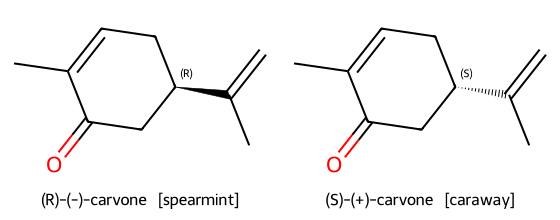

Same prediction, different smells. This is the single clearest argument in the notebook for chirality-aware representations and for 3D/receptor-based modelling.

Note the second failure visible here: the top achiral note is 'malty' (95 training positives), a rare-label false positive, and 'mint' only comes fourth. Rare notes are exactly where the per-label AUPRC in Part 3 was weakest, so a single prediction for a rare note should never be read without its label-level score.


In [59]:
# Carvone: identical achiral features, genuinely different odors
carvone = {"(R)-(-)-carvone  [spearmint]": "C=C(C)[C@@H]1CC=C(C)C(=O)C1",
           "(S)-(+)-carvone  [caraway]": "C=C(C)[C@H]1CC=C(C)C(=O)C1"}
rows = []
for name, smi in carvone.items():
    r = predict(smi, top_n=5)
    rows.append({"isomer": name, "top notes (achiral model)": ", ".join(f"{l} {p:.2f}" for l, p in r["top_odor_notes"])})
display(pd.DataFrame(rows))

ms = [Chem.MolFromSmiles(s) for s in carvone.values()]
opts = Draw.rdMolDraw2D.MolDrawOptions()
opts.addStereoAnnotation = True
display(SVG(Draw.MolsToGridImage(ms, legends=list(carvone), molsPerRow=2, subImgSize=(280, 220),
                                 useSVG=True, drawOptions=opts).data))
print("Same prediction, different smells. This is the single clearest argument in the notebook for "
      "chirality-aware representations and for 3D/receptor-based modelling.")
print("\nNote the second failure visible here: the top achiral note is 'malty' (95 training positives), "
      "a rare-label false positive, and 'mint' only comes fourth. Rare notes are exactly where the "
      "per-label AUPRC in Part 3 was weakest, so a single prediction for a rare note should never be "
      "read without its label-level score.")

**What to do about it.** Three options, in increasing cost:

1. **Chirality-aware fingerprints** (already computed in Part 2). Cheap, and they at least let the model *distinguish* the isomers — but public training labels rarely specify stereochemistry, so there is little signal to learn from. The honest statement is that the data, not the representation, is the limiting factor.
2. **3D descriptors / conformer ensembles.** Shape and electrostatics differ between enantiomers only in a chiral environment, so these help mainly in combination with a receptor model.
3. **Receptor-level modelling.** Olfactory receptors are chiral binding pockets, which is *why* enantiomers smell different. M2OR (51,395 receptor–molecule pairs) supports docking or sequence-based models that can in principle resolve them. That is the natural next project, and it is the honest answer to "how would you fix this?" in an interview.

## 5. Virtual screening

The pipeline applied the way a discovery project would use it: generate candidates, predict, then filter by criteria the business actually cares about.

**Candidate library.** Rather than inventing structures, the screen runs over molecules that are *real but unlabelled* for the target note: compounds in the merged database that no source describes with this note, plus analogues generated by small, synthetically reasonable transformations of known actives (chain homologation, ester exchange, methylation). This keeps the demonstration honest — every hit is a real, makeable structure.

**Filters, applied in order:**
1. **Odorant-likeness:** MW < 300 Da, 0 < logP < 5, no more than 3 H-bond donors — the volatility window odorants occupy.
2. **Applicability domain:** maximum Tanimoto similarity to training ≥ 0.4, from the Part 3 analysis.
3. **Novelty:** not a near-duplicate (< 0.85) of any molecule already known to carry the note, since a close analogue of an existing ingredient has little IP value.
4. **Predicted activity:** calibrated probability for the target note.
5. **Selectivity:** penalize candidates predicted to carry many strong off-notes.

In [60]:
TARGET_NOTE = "musk" if "musk" in ODOR_MODELS else "coconut"


def enumerate_analogues(seed_smiles, max_per_seed=12):
    """Small, synthetically plausible edits: homologation, methylation, ester exchange."""
    out = set()
    for smi in seed_smiles:
        mol = Chem.MolFromSmiles(smi)
        if mol is None or mol.GetNumHeavyAtoms() > 30:
            continue
        # chain homologation / truncation on terminal carbons
        for rxn_smarts in ["[CH3:1][CH2:2]>>[CH3][CH2][CH2:2]",          # extend chain
                           "[CH3:1][CH2:2][CH2:3]>>[CH3:1][CH2:2]",      # shorten chain
                           "[cH:1]>>[c:1]C",                             # aromatic methylation
                           "[CX3:1](=[O:2])[OX2:3][CH3]>>[C:1](=[O:2])[O:3]CC",   # methyl -> ethyl ester
                           "[CX3:1](=[O:2])[OX2:3][CH2][CH3]>>[C:1](=[O:2])[O:3]C"]:
            try:
                rxn = AllChem.ReactionFromSmarts(rxn_smarts)
                for prods in rxn.RunReactants((mol,)):
                    p = prods[0]
                    try:
                        Chem.SanitizeMol(p)
                    except Exception:
                        continue
                    out.add(Chem.MolToSmiles(p))
                    if len(out) > max_per_seed * len(seed_smiles):
                        break
            except Exception:
                continue
    return sorted(out)


known_positive = set(odor_labels_tbl.query("label == @TARGET_NOTE")["conn_key"])
unlabelled = [k for k in molecules.index if k not in known_positive]
seeds = list(molecules.loc[sorted(known_positive)[:40], "smiles"])
analogue_smiles = enumerate_analogues(seeds)
print(f"Candidate library: {len(unlabelled):,} database molecules not labelled '{TARGET_NOTE}' "
      f"+ {len(analogue_smiles):,} generated analogues of known actives")

lib = pd.DataFrame({"smiles": list(molecules.loc[unlabelled, "smiles"]) + analogue_smiles,
                    "origin": ["database"] * len(unlabelled) + ["generated analogue"] * len(analogue_smiles)})
lib["name"] = list(molecules.loc[unlabelled, "name"]) + [None] * len(analogue_smiles)
lib = lib.drop_duplicates("smiles").reset_index(drop=True)

Candidate library: 9,591 database molecules not labelled 'musk' + 40 generated analogues of known actives


In [61]:
t0 = time.time()
mols = [Chem.MolFromSmiles(s) for s in lib["smiles"]]
ok = [i for i, m in enumerate(mols) if m is not None]
lib, mols = lib.iloc[ok].reset_index(drop=True), [mols[i] for i in ok]

lib["mw"] = [Descriptors.MolWt(m) for m in mols]
lib["logp"] = [Descriptors.MolLogP(m) for m in mols]
lib["hbd"] = [Descriptors.NumHDonors(m) for m in mols]
odorant_like = (lib["mw"] < 300) & lib["logp"].between(0, 5) & (lib["hbd"] <= 3)
print(f"Odorant-likeness filter: {odorant_like.sum():,} of {len(lib):,} pass")

lib_f = lib[odorant_like].reset_index(drop=True)
mols_f = [m for m, keep in zip(mols, odorant_like) if keep]
fps_f = [af.morgan_bitvect(m) for m in mols_f]
lib_f["max_sim_train"] = [max(DataStructs.BulkTanimotoSimilarity(fp, TRAIN_FPS)) for fp in fps_f]
pos_fps = [af.morgan_bitvect(Chem.MolFromSmiles(molecules.loc[k, "smiles"])) for k in sorted(known_positive)]
lib_f["max_sim_known_actives"] = [max(DataStructs.BulkTanimotoSimilarity(fp, pos_fps)) for fp in fps_f]

blocks = af.featurize(lib_f["smiles"].tolist())
Xlib = np.hstack([{"morgan": blocks["morgan"].astype(np.float32), "maccs": blocks["maccs"].astype(np.float32),
                   "rdkit2d": blocks["rdkit2d"][:, PRUNED].astype(np.float32),
                   "ffgroups": blocks["ffgroups"].astype(np.float32)}[b] for b in BEST_BLOCK.split("+")])
Xlib = np.nan_to_num(Xlib, posinf=0, neginf=0)

p = ODOR_MODELS[TARGET_NOTE].predict_proba(Xlib)[:, 1]
lib_f[f"p_{TARGET_NOTE}"] = CALIB[TARGET_NOTE].predict(p) if TARGET_NOTE in CALIB else p
off_notes = [l for l in ODOR_MODELS if l != TARGET_NOTE][:40]
P_off = np.column_stack([ODOR_MODELS[l].predict_proba(Xlib)[:, 1] for l in off_notes])
lib_f["n_strong_off_notes"] = (P_off > 0.5).sum(1)
print(f"Scored {len(lib_f):,} candidates in {time.time() - t0:.0f}s")

Odorant-likeness filter: 6,914 of 9,629 pass


Scored 6,914 candidates in 54s


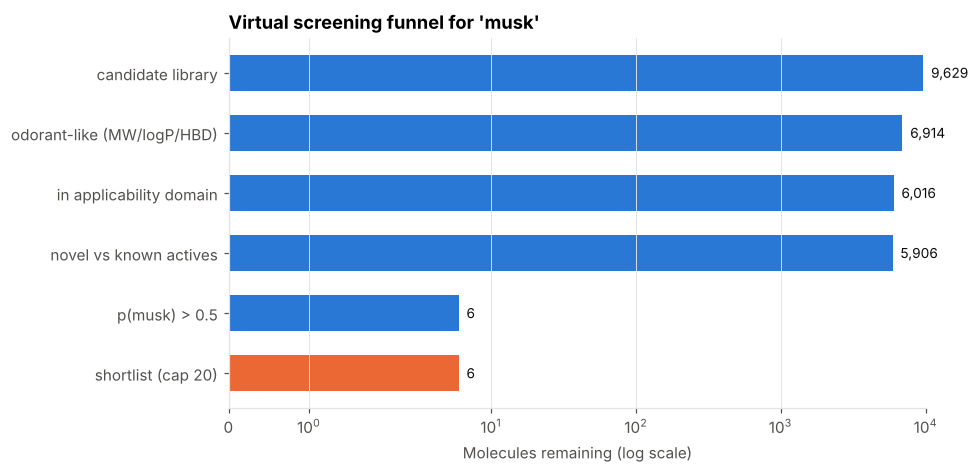

,stage,molecules
0,candidate library,9629
1,odorant-like (MW/logP/HBD),6914
2,in applicability domain,6016
3,novel vs known actives,5906
4,p(musk) > 0.5,6
5,shortlist (cap 20),6


In [62]:
in_domain = lib_f["max_sim_train"] >= AD_THRESHOLD
novel = lib_f["max_sim_known_actives"] < 0.85
hits = lib_f[in_domain & novel].copy()
hits["selectivity"] = 1 / (1 + hits["n_strong_off_notes"])
hits["score"] = hits[f"p_{TARGET_NOTE}"] * hits["selectivity"]
hits = hits.sort_values("score", ascending=False)
hits.to_csv(RESULT_DIR / f"virtual_screen_{TARGET_NOTE}.csv", index=False)

funnel = pd.DataFrame([
    {"stage": "candidate library", "molecules": len(lib)},
    {"stage": "odorant-like (MW/logP/HBD)", "molecules": int(odorant_like.sum())},
    {"stage": "in applicability domain", "molecules": int(in_domain.sum())},
    {"stage": "novel vs known actives", "molecules": int((in_domain & novel).sum())},
    {"stage": f"p({TARGET_NOTE}) > 0.5", "molecules": int((hits[f"p_{TARGET_NOTE}"] > 0.5).sum())},
    {"stage": "shortlist (cap 20)", "molecules": int(min(20, (hits[f"p_{TARGET_NOTE}"] > 0.5).sum()))},
])

fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(funnel))[::-1]
ax.barh(y, funnel["molecules"], color=[CAT[0]] * (len(funnel) - 1) + [CAT[1]], height=0.6)
for yi, (_, r) in zip(y, funnel.iterrows()):
    ax.text(r["molecules"], yi, f"  {r['molecules']:,}", va="center", fontsize=9, color=INK)
ax.set_yticks(y); ax.set_yticklabels(funnel["stage"])
ax.set_xscale("symlog")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Molecules remaining (log scale)")
ax.set_title(f"Virtual screening funnel for '{TARGET_NOTE}'")
plt.tight_layout()
savefig(fig, "p4_02_screening_funnel")
plt.show()
funnel

### 5.1 The shortlist

What a project would actually take forward: the top-ranked candidates with their predicted note, confidence, similarity to training (so a chemist can judge how much to trust it), and a flag for whether the structure came from the database or from analogue generation.

Top 12 by rank; 6 of them clear the p > 0.5 cut used in the funnel. The rest are shown for context, not as candidates.


,name,origin,p_musk,above_cut,max_sim_train,max_sim_known_actives,n_strong_off_notes,mw,logp
0,"(generated, unnamed)",generated analogue,0.73,yes,0.54,0.54,0,244.38,4.40
1,"(generated, unnamed)",generated analogue,0.69,yes,0.50,0.47,0,208.30,3.31
2,"(generated, unnamed)",generated analogue,0.69,yes,0.42,0.42,0,208.30,3.31
3,"(generated, unnamed)",generated analogue,0.67,yes,0.58,0.58,0,244.38,4.40
4,7051-11-8,database,0.64,yes,1.00,0.70,0,194.27,3.00
5,"(generated, unnamed)",generated analogue,0.63,yes,0.55,0.50,0,208.30,3.31
6,"(generated, unnamed)",generated analogue,0.49,,0.74,0.74,0,262.35,3.55
7,"(generated, unnamed)",generated analogue,0.46,,0.66,0.66,0,290.40,4.24
8,99758-40-4,database,0.42,,1.00,0.72,0,237.25,2.71
9,"(generated, unnamed)",generated analogue,0.39,,0.82,0.82,0,290.40,4.33


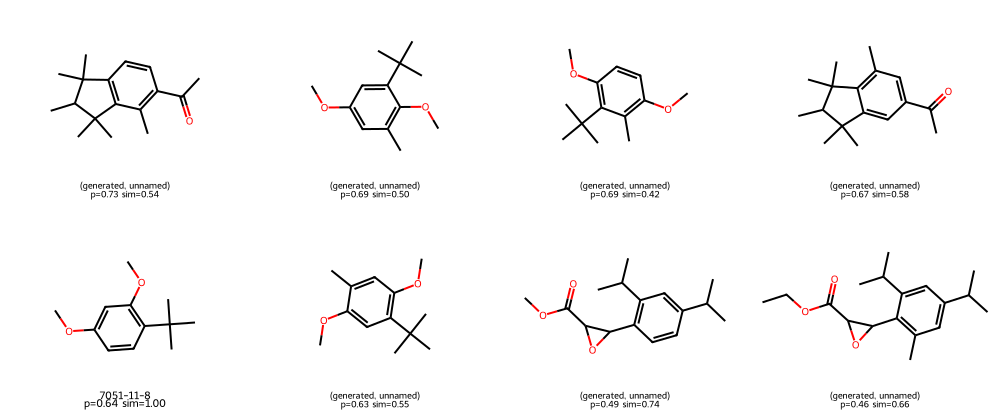

In [63]:
top = hits.head(12).copy()
top["name"] = [n if isinstance(n, str) and n else "(generated, unnamed)" for n in top["name"]]
top["above_cut"] = np.where(top[f"p_{TARGET_NOTE}"] > 0.5, "yes", "")
show = top[["name", "origin", f"p_{TARGET_NOTE}", "above_cut", "max_sim_train", "max_sim_known_actives",
            "n_strong_off_notes", "mw", "logp"]].round(2)
print(f"Top 12 by rank; {int((hits[f'p_{TARGET_NOTE}'] > 0.5).sum())} of them clear the p > 0.5 cut "
      f"used in the funnel. The rest are shown for context, not as candidates.")
display(show.reset_index(drop=True))

grid_mols = [Chem.MolFromSmiles(s) for s in top["smiles"].head(8)]
legends = [f"{(n if isinstance(n, str) and n else 'generated analogue')[:24]}\np={p:.2f} sim={s:.2f}"
           for n, p, s in zip(top["name"].head(8), top[f"p_{TARGET_NOTE}"].head(8), top["max_sim_train"].head(8))]
display(SVG(Draw.MolsToGridImage(grid_mols, legends=legends, molsPerRow=4, subImgSize=(250, 210),
                                 useSVG=True).data))

**Honest reading of the shortlist.** These are hypotheses for a sensory panel, not discoveries. Database molecules at the top are the more interesting result: they are real compounds already in commerce or literature that no source in the merged set describes with this note, so they are **cheap to test** — often available off the shelf. That is the realistic first experiment: order 10 compounds, run a panel, and feed the results back as new labels. Generated analogues need synthesis, so they come second.

A production version would also screen against:
* **Regulatory status:** IFRA restrictions and amendments, FEMA GRAS numbers, EU allergen lists, REACH registration.
* **Safety:** skin sensitization and genotoxicity alerts, which is where the ADMET toolbox from pharma carries over directly.
* **Cost and route:** estimated synthesis steps and starting-material price.
* **Freedom to operate:** patent landscape around the scaffold.

## 6. Deployment: how this fits a DMTA cycle

| Stage | What this pipeline provides | What it needs from the business |
|---|---|---|
| **Design** | Substructure attribution and analogue enumeration suggest what to make next | Perfumer or flavourist brief; target profile |
| **Make** | Prioritized shortlist, ranked by predicted activity and selectivity | Synthesis capacity, route feasibility |
| **Test** | Applicability-domain gating tells the panel which predictions are extrapolation | Sensory panel time, GC-O data |
| **Analyze** | New panel results become new labels; models retrain on the enlarged set | A data pipeline that captures panel results in a structured form |

**The compounding advantage.** Public data is small, noisy and plateaued. An ingredients company has decades of internal panel data with concentrations, thresholds, and negative results — the single biggest lever on model quality. The pipeline is built so internal data drops into the same schema: `source_records` holds provenance, `panel_ratings` holds continuous ratings, and the harmonizer maps internal vocabulary to the shared ontology.

**What I would build next, in order:**

1. **Active learning.** Pick the next panel experiments by expected information gain rather than by predicted activity. With panel time as the bottleneck, this is where the ROI is.
2. **A message-passing GNN** (Chemprop or the OpenPOM MPNN) and a multi-task trunk across odor + taste + receptor data. The Principal Odor Map work shows the representation transfers.
3. **Receptor-level models** on M2OR, which is the path to resolving the stereochemistry blind spot and to mechanistic reasoning about *why* a molecule smells.
4. **Threshold and intensity prediction,** not just character. A molecule with the right note but a 1,000× higher detection threshold is commercially useless, and Keller 2016 plus internal threshold data supports this directly.
5. **MLOps:** versioned datasets and models, drift monitoring on incoming structures, a recorded applicability-domain check on every prediction, and retraining triggered by new panel data.

## 7. Conclusions

**What was built.** An end-to-end, reproducible pipeline from public data to ranked synthesis candidates:

* **Part 1:** a merged, provenance-tracked database of 9,775 molecules — 6,166 with harmonized odor labels across 138 notes from 9 sources, 3,660 with taste labels, plus human panel ratings.
* **Part 2:** chirality-aware featurization, chemical-space analysis, and leakage-controlled splits, with the finding that scaffold splits are inappropriate for odorants.
* **Part 3:** calibrated multi-label aroma models and taste models, validated with grouped CV, bootstrap confidence intervals, and an explicit applicability domain.
* **Part 4:** chemist-readable explanations that reproduce classical structure–odor rules, and a virtual screen that turns the model into a shortlist.

**What the work says about the problem, not just the code**

1. **Data quality is the binding constraint, not model capacity.** Independent expert sources agree only partially on the same molecule (Part 1). No model should be expected to exceed that, and the highest-value investment is better and more consistent data, not a bigger network.
2. **Evaluation protocol changes conclusions more than model choice does.** Random splits inflate headline numbers substantially (Part 3). Any benchmark claim needs its split protocol stated.
3. **The commercially valuable notes are the data-poor ones.** Musk, amber and sandalwood are rare labels (Part 1), and model performance tracks label frequency (Part 3). This is an argument for targeted data generation.
4. **Stereochemistry is a real limit of 2D methods,** quantified rather than hand-waved (Parts 2 and 4), and it points directly at receptor-based modelling.
5. **An explainable model is a usable model.** Attribution that recovers "lactone → coconut" and "macrocycle → musk" earns a chemist's trust, and tells them what to change in the next analogue.

---

*Reproducibility: every notebook runs top to bottom from a clean checkout. Downloads are cached with SHA-256 manifests, seeds are fixed, and package versions are pinned in `requirements.txt`. Data sources, licences and citations are listed in the `sources` table of the database.*